**Cell 1**

In [78]:
# File handling and text processing
from pathlib import Path
import re
import warnings

# Data manipulation and numerical operations
import numpy as np
import pandas as pd

# Data visualisation
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Data splitting, cross-validation and hyperparameter tuning
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_predict,
    GridSearchCV
)

# Machine learning pipelines and model utilities
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# Text feature extraction
from sklearn.feature_extraction.text import (
    TfidfVectorizer,
    CountVectorizer
)

# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB

# Model evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

# XGBoost classification model
try:
    from xgboost import XGBClassifier
except ImportError as exc:
    raise ImportError(
        "XGBoost is required. Install it using "
        "'%pip install xgboost' and restart the kernel."
    ) from exc

# Set a fixed random seed for reproducible experiments
RANDOM_STATE = 42

# Apply a consistent visual style
sns.set_theme(style="whitegrid")

# Display all columns when inspecting datasets
pd.set_option("display.max_columns", None)

# Confirm successful initialisation
print("Library imports completed successfully.")
print("Random state:", RANDOM_STATE)
print("Classification models: Logistic Regression, Naive Bayes, XGBoost")


Library imports completed successfully.
Random state: 42
Classification models: Logistic Regression, Naive Bayes, XGBoost


**cell 2**

In [79]:
# Import the required library for file paths
from pathlib import Path

# Define the original dataset filenames
FAKE_FILE = "Fake.csv"
TRUE_FILE = "True.csv"

# Locate dataset files in common Jupyter/Colab directories
def locate_csv(filename):
    search_directories = [
        Path.cwd(),
        Path("/content"),
        Path("/mnt/data")
    ]

    for directory in search_directories:
        file_path = directory / filename

        if file_path.is_file():
            return file_path

    raise FileNotFoundError(
        f"Dataset file '{filename}' was not found. "
        "Upload Fake.csv and True.csv to the notebook "
        "working directory before running this cell."
    )


# Locate the two original CSV files
fake_path = locate_csv(FAKE_FILE)
true_path = locate_csv(TRUE_FILE)


# Load CSV files without silently removing malformed records
def load_news_dataset(file_path):
    try:
        data = pd.read_csv(
            file_path,
            engine="c",
            encoding="utf-8-sig",
            on_bad_lines="error",
            low_memory=False
        )

    except (pd.errors.ParserError, UnicodeError) as error:
        raise ValueError(
            f"Unable to read '{file_path.name}' correctly. "
            "The CSV may contain malformed quotation marks, "
            "damaged rows, or an encoding issue. "
            "Please check the original source file. "
            f"Original error: {error}"
        ) from error

    return data


# Load fake and real news datasets
fake_df = load_news_dataset(fake_path)
true_df = load_news_dataset(true_path)


# Display dataset dimensions
print("DATASET LOADING SUMMARY")
print("-" * 55)

print("Fake news dataset shape:", fake_df.shape)
print("Real news dataset shape:", true_df.shape)

print("\nFake news articles:", len(fake_df))
print("Real news articles:", len(true_df))

print(
    "Total articles:",
    len(fake_df) + len(true_df)
)


# Check article counts against the original ISOT release
expected_fake = 23481
expected_real = 21417

if (
    len(fake_df) == expected_fake
    and len(true_df) == expected_real
):
    print("\nArticle counts match the expected ISOT dataset.")
else:
    print(
        "\nWARNING: Article counts differ from the "
        "expected ISOT dataset."
    )
    print("Check the source files before continuing.")


# Preview the original datasets
print("\nFAKE NEWS DATASET PREVIEW")
display(fake_df.head(5))

print("\nREAL NEWS DATASET PREVIEW")
display(true_df.head(5))


# Confirm that the files are not empty
if fake_df.empty or true_df.empty:
    raise ValueError(
        "One or both datasets are empty. "
        "Please verify the source CSV files."
    )

print("\nDataset loading completed successfully.")


DATASET LOADING SUMMARY
-------------------------------------------------------
Fake news dataset shape: (23481, 4)
Real news dataset shape: (21417, 4)

Fake news articles: 23481
Real news articles: 21417
Total articles: 44898

Article counts match the expected ISOT dataset.

FAKE NEWS DATASET PREVIEW


,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"



REAL NEWS DATASET PREVIEW


,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017"



Dataset loading completed successfully.


**Cell 3**

In [80]:
# Define the required columns in the original ISOT datasets
required_columns = ["title", "text", "subject", "date"]

# Validate that both datasets contain the expected attributes
for dataset_name, dataset in [
    ("Fake News", fake_df),
    ("Real News", true_df)
]:

    missing_columns = [
        column for column in required_columns
        if column not in dataset.columns
    ]

    if missing_columns:
        raise ValueError(
            f"{dataset_name} dataset is missing "
            f"required columns: {missing_columns}"
        )

print("Dataset structure validation completed successfully.")


# Create independent copies to preserve the loaded datasets
fake_df = fake_df[required_columns].copy()
true_df = true_df[required_columns].copy()


# Assign the binary class labels
# 0 represents Fake News
# 1 represents Real News
fake_df["label"] = 0
true_df["label"] = 1


# Combine both datasets into a single DataFrame
df = pd.concat(
    [fake_df, true_df],
    ignore_index=True
)


# Verify that the combined dataset contains both classes
assert set(df["label"].unique()) == {0, 1}, (
    "The combined dataset must contain both Fake and Real labels."
)

# Verify that no articles were lost during combination
assert len(df) == len(fake_df) + len(true_df), (
    "Article counts do not match after dataset combination."
)


# Display the combined dataset structure
print("\nCOMBINED DATASET SUMMARY")
print("-" * 55)

print("Fake news articles:", len(fake_df))
print("Real news articles:", len(true_df))
print("Total articles:", len(df))

print("\nCombined dataset shape:", df.shape)

print("\nDataset columns:")
print(df.columns.tolist())


# Display the class distribution
class_counts = (
    df["label"]
    .value_counts()
    .sort_index()
    .rename(index={0: "Fake News", 1: "Real News"})
)

print("\nCLASS DISTRIBUTION")
print(class_counts)


# Display the first five records
print("\nCOMBINED DATASET PREVIEW")
display(df.head(5))


print("\nCell 3 completed successfully.")


Dataset structure validation completed successfully.

COMBINED DATASET SUMMARY
-------------------------------------------------------
Fake news articles: 23481
Real news articles: 21417
Total articles: 44898

Combined dataset shape: (44898, 5)

Dataset columns:
['title', 'text', 'subject', 'date', 'label']

CLASS DISTRIBUTION
label
Fake News    23481
Real News    21417
Name: count, dtype: int64

COMBINED DATASET PREVIEW


,title,text,subject,date,label
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",0
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",0
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",0
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017",0
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017",0



Cell 3 completed successfully.


**Cell 4**

In [81]:
# Confirm that the combined dataset is available
if "df" not in globals():
    raise RuntimeError(
        "Please run Cell 3 before executing Cell 4."
    )

# Check the data types of all attributes
print("1. DATASET STRUCTURE")
print("-" * 55)

print("Total records:", len(df))
print("Total columns:", df.shape[1])

print("\nColumn data types:")
print(df.dtypes)


# Identify missing values in each column
print("\n2. MISSING VALUE ANALYSIS")
print("-" * 55)

missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (
        df.isna().mean() * 100
    ).round(2)
})

display(missing_summary)


# Identify exact duplicate records
print("\n3. EXACT DUPLICATE ANALYSIS")
print("-" * 55)

exact_duplicates = int(df.duplicated().sum())

duplicate_percentage = (
    exact_duplicates / len(df) * 100
)

print("Exact duplicate records:", exact_duplicates)

print(
    "Duplicate percentage:",
    f"{duplicate_percentage:.2f}%"
)


# Identify empty or whitespace-only titles and article bodies
print("\n4. EMPTY TEXT ANALYSIS")
print("-" * 55)

empty_titles = (
    df["title"]
    .fillna("")
    .astype(str)
    .str.strip()
    .eq("")
)

empty_articles = (
    df["text"]
    .fillna("")
    .astype(str)
    .str.strip()
    .eq("")
)

empty_text_summary = pd.DataFrame({
    "Field": ["Article Title", "Article Body"],
    "Empty Records": [
        int(empty_titles.sum()),
        int(empty_articles.sum())
    ],
    "Percentage (%)": [
        round(empty_titles.mean() * 100, 2),
        round(empty_articles.mean() * 100, 2)
    ]
})

display(empty_text_summary)


# Examine the distribution of article subjects
print("\n5. SUBJECT DISTRIBUTION BY CLASS")
print("-" * 55)

subject_distribution = pd.crosstab(
    df["subject"].fillna("Missing"),
    df["label"]
)

subject_distribution = subject_distribution.rename(
    columns={
        0: "Fake",
        1: "Real"
    }
)

display(subject_distribution)


# Display a concise data quality summary
print("\n6. DATA QUALITY SUMMARY")
print("-" * 55)

print("Total records:", len(df))
print("Missing article bodies:", int(df["text"].isna().sum()))
print("Empty or whitespace-only bodies:", int(empty_articles.sum()))
print("Empty or whitespace-only titles:", int(empty_titles.sum()))
print("Exact duplicate records:", exact_duplicates)

print("\nData quality assessment completed successfully.")
print("No records have been removed in this cell.")


1. DATASET STRUCTURE
-------------------------------------------------------
Total records: 44898
Total columns: 5

Column data types:
title      object
text       object
subject    object
date       object
label       int64
dtype: object

2. MISSING VALUE ANALYSIS
-------------------------------------------------------


,Missing Count,Missing Percentage
title,0,0.0
text,0,0.0
subject,0,0.0
date,0,0.0
label,0,0.0



3. EXACT DUPLICATE ANALYSIS
-------------------------------------------------------
Exact duplicate records: 209
Duplicate percentage: 0.47%

4. EMPTY TEXT ANALYSIS
-------------------------------------------------------


,Field,Empty Records,Percentage (%)
0,Article Title,0,0.00
1,Article Body,631,1.41



5. SUBJECT DISTRIBUTION BY CLASS
-------------------------------------------------------


label,Fake,Real
subject,,
Government News,1570,0
Middle-east,778,0
News,9050,0
US_News,783,0
left-news,4459,0
politics,6841,0
politicsNews,0,11272
worldnews,0,10145



6. DATA QUALITY SUMMARY
-------------------------------------------------------
Total records: 44898
Missing article bodies: 0
Empty or whitespace-only bodies: 631
Empty or whitespace-only titles: 0
Exact duplicate records: 209

Data quality assessment completed successfully.
No records have been removed in this cell.


**cell 5**

In [82]:
# Create an independent copy to preserve the original dataset
clean_df = df.copy()

# Record the dataset size before cleaning
original_count = len(clean_df)

# Ensure text columns contain strings
# Missing values are temporarily represented as empty strings
clean_df["title"] = clean_df["title"].fillna("").astype(str)
clean_df["text"] = clean_df["text"].fillna("").astype(str)

# Remove leading and trailing whitespace
clean_df["title"] = clean_df["title"].str.strip()
clean_df["text"] = clean_df["text"].str.strip()

# Identify articles with empty or whitespace-only body text
empty_text_mask = clean_df["text"].eq("")

# Count the articles requiring removal
empty_articles_removed = int(empty_text_mask.sum())

# Preserve articles containing meaningful body text
clean_df = clean_df.loc[~empty_text_mask].copy()

# Reset the index after removing invalid records
clean_df.reset_index(drop=True, inplace=True)

# Calculate the number and percentage of retained articles
remaining_articles = len(clean_df)

removal_percentage = (
    empty_articles_removed / original_count * 100
)

retention_percentage = (
    remaining_articles / original_count * 100
)

# Display the cleaning summary
print("DATA CLEANING SUMMARY")
print("-" * 55)

print("Original articles:", original_count)
print("Empty articles removed:", empty_articles_removed)
print("Remaining articles:", remaining_articles)

print(
    "Removal percentage:",
    f"{removal_percentage:.2f}%"
)

print(
    "Retention percentage:",
    f"{retention_percentage:.2f}%"
)

# Check whether any article titles remain empty
remaining_empty_titles = int(
    clean_df["title"].eq("").sum()
)

print("\nRemaining empty titles:", remaining_empty_titles)

# Verify that no empty article bodies remain
assert clean_df["text"].str.strip().ne("").all(), (
    "Empty article bodies remain after cleaning."
)

# Verify that all expected records are accounted for
assert (
    original_count
    == empty_articles_removed + remaining_articles
), "Dataset cleaning counts are inconsistent."

# Display the remaining class distribution
print("\nCLASS DISTRIBUTION AFTER EMPTY TEXT REMOVAL")

class_counts = (
    clean_df["label"]
    .value_counts()
    .sort_index()
    .rename(index={0: "Fake News", 1: "Real News"})
)

display(class_counts)

# Confirm successful cleaning
print("No duplicate articles have been removed yet.")


DATA CLEANING SUMMARY
-------------------------------------------------------
Original articles: 44898
Empty articles removed: 631
Remaining articles: 44267
Removal percentage: 1.41%
Retention percentage: 98.59%

Remaining empty titles: 0

CLASS DISTRIBUTION AFTER EMPTY TEXT REMOVAL


,count
label,
Fake News,22851
Real News,21416


No duplicate articles have been removed yet.


**Cell 6**

In [83]:
# Create a normalised text key for duplicate identification.
# Lowercase conversion and whitespace normalisation help
# identify articles with identical content but different formatting.

# Preserve the original article text for model training.
clean_df["text_key"] = (
    clean_df["text"]
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Count repeated article bodies beyond their first occurrence.
duplicate_count = int(
    clean_df.duplicated(
        subset="text_key",
        keep="first"
    ).sum()
)

# Calculate the percentage of repeated article bodies.
duplicate_percentage = (
    duplicate_count / len(clean_df) * 100
)

# Check whether identical article bodies have different class labels.
# This identifies potential inconsistencies in the dataset.
labels_per_text = (
    clean_df.groupby("text_key")["label"].nunique()
)

# Identify normalised article bodies assigned to both classes.
conflicting_keys = labels_per_text[
    labels_per_text > 1
].index

# Identify all records belonging to conflicting groups.
conflicting_rows = clean_df["text_key"].isin(
    conflicting_keys
)

# Count label inconsistencies.
conflicting_articles = int(conflicting_rows.sum())

conflicting_groups = len(conflicting_keys)

# Display the duplicate detection results.
print("NORMALISED TEXT AND DUPLICATE ANALYSIS")
print("-" * 55)

print("Articles after empty-text removal:", len(clean_df))

print("Repeated article bodies:", duplicate_count)

print(
    "Duplicate percentage:",
    f"{duplicate_percentage:.2f}%"
)

print("Article bodies with conflicting labels:", conflicting_groups)

print("Records involved in conflicting labels:", conflicting_articles)

# Display examples only when conflicting labels exist.
if conflicting_articles > 0:

    print("\nEXAMPLES OF CONFLICTING LABELS")

    display(
        clean_df.loc[
            conflicting_rows,
            ["title", "text", "label"]
        ].head(6)
    )

else:
    print("\nNo conflicting class labels were identified.")

# Verify that normalisation does not remove any records.
assert len(clean_df) > 0, (
    "The cleaned dataset is unexpectedly empty."
)

assert clean_df["text_key"].ne("").all(), (
    "Empty normalised article bodies were found."
)

# Confirm completion.

print("Duplicate records have been identified but not removed.")


NORMALISED TEXT AND DUPLICATE ANALYSIS
-------------------------------------------------------
Articles after empty-text removal: 44267
Repeated article bodies: 5630
Duplicate percentage: 12.72%
Article bodies with conflicting labels: 0
Records involved in conflicting labels: 0

No conflicting class labels were identified.
Duplicate records have been identified but not removed.


**Cell 7**

In [84]:
# Record the dataset size before duplicate removal
before_deduplication = len(clean_df)

# Identify article bodies that have conflicting class labels
# Such records must not be assigned an arbitrary label
labels_per_text = (
    clean_df.groupby("text_key")["label"].nunique()
)

conflicting_keys = labels_per_text[
    labels_per_text > 1
].index

# Identify all records with conflicting labels
conflicting_mask = clean_df["text_key"].isin(
    conflicting_keys
)

# Count conflicting records
conflicting_removed = int(conflicting_mask.sum())

# Remove conflicting records, if any exist
clean_df = clean_df.loc[
    ~conflicting_mask
].copy()

# Record the size before removing repeated article bodies
before_duplicate_removal = len(clean_df)

# Keep only the first occurrence of each normalised article body
clean_df = clean_df.drop_duplicates(
    subset=["text_key"],
    keep="first"
).copy()

# Reset the index after cleaning
clean_df.reset_index(
    drop=True,
    inplace=True
)

# Calculate the number of duplicate records removed
duplicates_removed = (
    before_duplicate_removal - len(clean_df)
)

# Calculate the final dataset size
final_count = len(clean_df)

# Calculate the total number of removed articles
total_removed = original_count - final_count

# Create a cleaning summary table
cleaning_summary = pd.DataFrame({
    "Cleaning Stage": [
        "Original dataset",
        "After empty-text removal",
        "After conflicting-label removal",
        "After duplicate removal"
    ],
    "Remaining Articles": [
        original_count,
        before_deduplication,
        before_duplicate_removal,
        final_count
    ]
})

# Display the cleaning summary
print("FINAL DATA CLEANING SUMMARY")
print("-" * 60)

display(cleaning_summary)

print("Empty article bodies removed:",
      original_count - before_deduplication)

print("Conflicting-label records removed:",
      conflicting_removed)

print("Duplicate article bodies removed:",
      duplicates_removed)

print("Total records removed:", total_removed)

print("Final dataset size:", clean_df.shape)

# Display the final class distribution
final_class_counts = (
    clean_df["label"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
    .rename(index={0: "Fake News", 1: "Real News"})
)

print("\nFINAL CLASS DISTRIBUTION")
display(final_class_counts)

# Verify that no empty article bodies remain
assert clean_df["text"].str.strip().ne("").all(), (
    "Empty article bodies remain after cleaning."
)

# Verify that all normalised article bodies are unique
assert clean_df["text_key"].is_unique, (
    "Duplicate article bodies remain after cleaning."
)

# Verify that both classes are present
assert set(clean_df["label"].unique()) == {0, 1}, (
    "Both Fake and Real classes must be present."
)

# Verify that cleaning counts are consistent
assert (
    total_removed
    == (
        original_count - before_deduplication
        + conflicting_removed
        + duplicates_removed
    )
), "Cleaning record counts are inconsistent."

# Confirm successful dataset preparation
print("\nAll data cleaning validation checks passed.")
print("The dataset is ready for train-test splitting.")


FINAL DATA CLEANING SUMMARY
------------------------------------------------------------


,Cleaning Stage,Remaining Articles
0,Original dataset,44898
1,After empty-text removal,44267
2,After conflicting-label removal,44267
3,After duplicate removal,38637


Empty article bodies removed: 631
Conflicting-label records removed: 0
Duplicate article bodies removed: 5630
Total records removed: 6261
Final dataset size: (38637, 6)

FINAL CLASS DISTRIBUTION


,count
label,
Fake News,17448
Real News,21189



All data cleaning validation checks passed.
The dataset is ready for train-test splitting.


**Cell 8**

In [85]:
# Import the function required for splitting the dataset
from sklearn.model_selection import train_test_split

# Confirm that the cleaned dataset is ready
if clean_df.empty:
    raise ValueError(
        "The cleaned dataset is empty. Check Cell 7."
    )

# Verify that duplicate article bodies have been removed
assert clean_df["text_key"].is_unique, (
    "Duplicate article bodies remain in the cleaned dataset."
)

# Define the training and testing proportions
TEST_SIZE = 0.20

# Split the cleaned dataset while preserving class proportions
# Stratification ensures both subsets contain similar
# proportions of fake (0) and real (1) articles
train_df, test_df = train_test_split(
    clean_df,
    test_size=TEST_SIZE,
    stratify=clean_df["label"],
    random_state=RANDOM_STATE,
    shuffle=True
)

# Create independent copies and reset their indices
train_df = train_df.copy().reset_index(drop=True)
test_df = test_df.copy().reset_index(drop=True)

# Calculate the number of articles in each subset
training_count = len(train_df)
testing_count = len(test_df)
total_count = len(clean_df)

# Calculate the percentage of records in each subset
training_percentage = training_count / total_count * 100
testing_percentage = testing_count / total_count * 100

# Display the dataset splitting summary
print("STRATIFIED TRAIN-TEST SPLIT")
print("-" * 55)

print("Total cleaned articles:", total_count)
print("Training articles:", training_count)
print("Testing articles:", testing_count)

print(
    "Training percentage:",
    f"{training_percentage:.2f}%"
)

print(
    "Testing percentage:",
    f"{testing_percentage:.2f}%"
)

# Compare the proportion of fake and real news
# across the original, training and testing datasets
class_distribution = pd.DataFrame({
    "Overall (%)": (
        clean_df["label"]
        .value_counts(normalize=True)
        .reindex([0, 1]) * 100
    ),
    "Training (%)": (
        train_df["label"]
        .value_counts(normalize=True)
        .reindex([0, 1]) * 100
    ),
    "Testing (%)": (
        test_df["label"]
        .value_counts(normalize=True)
        .reindex([0, 1]) * 100
    )
})

# Replace numerical labels with readable class names
class_distribution.index = ["Fake News", "Real News"]

print("\nCLASS DISTRIBUTION")
display(class_distribution.round(2))

# Verify that all articles are accounted for
assert training_count + testing_count == total_count, (
    "The training and testing counts are inconsistent."
)

# Verify that both classes exist in each subset
assert set(train_df["label"].unique()) == {0, 1}
assert set(test_df["label"].unique()) == {0, 1}

# Verify that the train and test subsets do not overlap
# using the normalised article-body keys
overlap_count = len(
    set(train_df["text_key"]) &
    set(test_df["text_key"])
)

assert overlap_count == 0, (
    "Duplicate article bodies exist across training and testing."
)

print("\nExact article-body overlap:", overlap_count)

STRATIFIED TRAIN-TEST SPLIT
-------------------------------------------------------
Total cleaned articles: 38637
Training articles: 30909
Testing articles: 7728
Training percentage: 80.00%
Testing percentage: 20.00%

CLASS DISTRIBUTION


,Overall (%),Training (%),Testing (%)
Fake News,45.16,45.16,45.16
Real News,54.84,54.84,54.84



Exact article-body overlap: 0


**Cell 9**

In [ ]:
# Verify that the required columns exist in both subsets
required_columns = ["text", "text_key", "label"]

for dataset_name, dataset in [
    ("Training", train_df),
    ("Testing", test_df)
]:
    missing_columns = [
        column for column in required_columns
        if column not in dataset.columns
    ]

    if missing_columns:
        raise ValueError(
            f"{dataset_name} dataset is missing: {missing_columns}"
        )

# Check for missing or empty article bodies
train_empty = int(
    train_df["text"].fillna("").str.strip().eq("").sum()
)

test_empty = int(
    test_df["text"].fillna("").str.strip().eq("").sum()
)

# Check for duplicate article bodies within each subset
train_duplicates = int(
    train_df.duplicated(subset="text_key").sum()
)

test_duplicates = int(
    test_df.duplicated(subset="text_key").sum()
)

# Compare normalised article bodies across the subsets
train_text_keys = set(train_df["text_key"])
test_text_keys = set(test_df["text_key"])

# Identify exact normalised text overlap
overlapping_text = (
    train_text_keys.intersection(test_text_keys)
)

overlap_count = len(overlapping_text)

# Verify the class labels
train_labels_valid = train_df["label"].isin([0, 1]).all()
test_labels_valid = test_df["label"].isin([0, 1]).all()

# Create a data integrity summary
integrity_summary = pd.DataFrame({
    "Check": [
        "Total articles",
        "Empty article bodies",
        "Duplicate article bodies",
        "Invalid class labels"
    ],
    "Training": [
        len(train_df),
        train_empty,
        train_duplicates,
        int((~train_df["label"].isin([0, 1])).sum())
    ],
    "Testing": [
        len(test_df),
        test_empty,
        test_duplicates,
        int((~test_df["label"].isin([0, 1])).sum())
    ]
})

# Display the summary
print("TRAINING AND TESTING DATA INTEGRITY")
print("-" * 60)

display(integrity_summary)

print("\nCROSS-SUBSET DUPLICATE ANALYSIS")
print("-" * 60)

print("Training unique article bodies:", len(train_text_keys))
print("Testing unique article bodies:", len(test_text_keys))
print("Matching article bodies across subsets:", overlap_count)

# Stop execution if data quality problems remain
assert train_empty == 0 and test_empty == 0, (
    "Empty article bodies were detected."
)

assert train_duplicates == 0 and test_duplicates == 0, (
    "Duplicate article bodies remain within a subset."
)

assert train_labels_valid and test_labels_valid, (
    "Invalid class labels were detected."
)

assert overlap_count == 0, (
    "Identical article bodies appear in both training "
    "and testing datasets."
)

# Verify that the split preserves every cleaned record
assert len(train_df) + len(test_df) == len(clean_df), (
    "Training and testing counts do not match "
    "the cleaned dataset."
)

# Confirm successful validation
print("\nAll data integrity checks passed.")
print("No exact normalised article-body overlap was detected.")
print("Training and testing datasets are ready.")


TRAINING AND TESTING DATA INTEGRITY
------------------------------------------------------------


,Check,Training,Testing
0,Total articles,30909,7728
1,Empty article bodies,0,0
2,Duplicate article bodies,0,0
3,Invalid class labels,0,0



CROSS-SUBSET DUPLICATE ANALYSIS
------------------------------------------------------------
Training unique article bodies: 30909
Testing unique article bodies: 7728
Matching article bodies across subsets: 0

All data integrity checks passed.
No exact normalised article-body overlap was detected.
Training and testing datasets are ready.


**Cell 10**

In [ ]:
# Use only article body text as the model input.
# Titles, subjects, dates and duplicate-detection keys are
# excluded to maintain a consistent experimental design.

X_train = train_df["text"].copy()
X_test = test_df["text"].copy()

# Define the binary classification target.
# Fake News = 0
# Real News = 1

y_train = train_df["label"].copy()
y_test = test_df["label"].copy()

# Verify that every article has a corresponding label.
assert len(X_train) == len(y_train), (
    "Training articles and labels do not match."
)

assert len(X_test) == len(y_test), (
    "Testing articles and labels do not match."
)

# Verify that no missing or empty text values remain.
assert X_train.notna().all() and X_test.notna().all(), (
    "Missing article text was detected."
)

assert X_train.str.strip().ne("").all(), (
    "Empty article text was detected in training data."
)

assert X_test.str.strip().ne("").all(), (
    "Empty article text was detected in testing data."
)

# Ensure that the target contains only valid binary labels.
assert y_train.isin([0, 1]).all(), (
    "Invalid training labels were detected."
)

assert y_test.isin([0, 1]).all(), (
    "Invalid testing labels were detected."
)

# Display the dimensions of the model inputs.
print("MODEL INPUT AND TARGET SUMMARY")
print("-" * 55)

print("Training input shape:", X_train.shape)
print("Training target shape:", y_train.shape)

print("Testing input shape:", X_test.shape)
print("Testing target shape:", y_test.shape)

# Display the number of articles in each class.
class_summary = pd.DataFrame({
    "Training": y_train.value_counts().reindex(
        [0, 1], fill_value=0
    ),
    "Testing": y_test.value_counts().reindex(
        [0, 1], fill_value=0
    )
})

class_summary.index = ["Fake News", "Real News"]

print("\nCLASS DISTRIBUTION")
display(class_summary)

# Confirm that the inputs are ready for feature extraction.
print("\nCell 10 completed successfully.")
print("Model input: Article body text only.")
print("Target labels: Fake = 0, Real = 1.")
print("TF-IDF has not been fitted yet.")
print("The held-out test set remains reserved for final evaluation.")


MODEL INPUT AND TARGET SUMMARY
-------------------------------------------------------
Training input shape: (30909,)
Training target shape: (30909,)
Testing input shape: (7728,)
Testing target shape: (7728,)

CLASS DISTRIBUTION


,Training,Testing
Fake News,13958,3490
Real News,16951,4238



Cell 10 completed successfully.
Model input: Article body text only.
Target labels: Fake = 0, Real = 1.
TF-IDF has not been fitted yet.
The held-out test set remains reserved for final evaluation.


**Cell 11**

In [ ]:
# Create a separate copy of the training data for EDA.
# The test dataset remains untouched to prevent data leakage.
eda_df = train_df.copy()

# Define readable class labels.
# Fake = 0 and Real = 1.
class_order = ["Fake", "Real"]

eda_df["class_name"] = eda_df["label"].map({
    0: "Fake",
    1: "Real"
})

# Check that all class labels are valid.
if eda_df["class_name"].isna().any():
    raise ValueError("Unexpected class labels found in training data.")

# ------------------------------------------------------------
# Calculate article and headline length features
# ------------------------------------------------------------

# Count the number of words in each article body.
eda_df["word_count"] = (
    eda_df["text"]
    .fillna("")
    .astype(str)
    .str.split()
    .str.len()
)

# Count the number of characters in each article body.
eda_df["character_count"] = (
    eda_df["text"]
    .fillna("")
    .astype(str)
    .str.len()
)

# Count the number of words in each article headline.
eda_df["title_word_count"] = (
    eda_df["title"]
    .fillna("")
    .astype(str)
    .str.split()
    .str.len()
)

# ------------------------------------------------------------
# Descriptive statistical analysis
# ------------------------------------------------------------

# Calculate descriptive statistics separately for each class.
length_summary = (
    eda_df.groupby("class_name")[
        ["word_count", "character_count", "title_word_count"]
    ]
    .describe()
    .round(2)
    .reindex(class_order)
)

print("EXPLORATORY DATA ANALYSIS: TEXT LENGTH")
print("-" * 60)

print("\n1. DESCRIPTIVE STATISTICS BY NEWS CLASS")
display(length_summary)

# ------------------------------------------------------------
# Create a concise comparison for interpretation
# ------------------------------------------------------------

comparison_summary = (
    eda_df.groupby("class_name")
    .agg(
        Articles=("label", "size"),
        Mean_Article_Words=("word_count", "mean"),
        Median_Article_Words=("word_count", "median"),
        Mean_Article_Characters=("character_count", "mean"),
        Median_Article_Characters=("character_count", "median"),
        Mean_Title_Words=("title_word_count", "mean"),
        Median_Title_Words=("title_word_count", "median")
    )
    .reindex(class_order)
    .round(2)
)

print("\n2. FAKE VS REAL NEWS: LENGTH COMPARISON")
display(comparison_summary)

# ------------------------------------------------------------
# Validate the derived EDA features
# ------------------------------------------------------------

# Check that no negative length values were generated.
assert (
    eda_df[
        ["word_count", "character_count", "title_word_count"]
    ] >= 0
).all().all(), "Invalid negative text lengths detected."

# Confirm that EDA does not modify the number of observations.
assert len(eda_df) == len(train_df), (
    "EDA record count does not match training data."
)

# Confirm successful analysis.
print("\n3. EDA VALIDATION")
print("Training articles analysed:", len(eda_df))
print("Held-out test articles used: 0")
print("Text-length features created successfully.")

EXPLORATORY DATA ANALYSIS: TEXT LENGTH
------------------------------------------------------------

1. DESCRIPTIVE STATISTICS BY NEWS CLASS


word_count                                                     \
                count    mean     std   min    25%    50%    75%     max   
class_name                                                                 
Fake          13958.0  426.92  358.72   1.0  279.0  377.0  504.0  8135.0   
Real          16951.0  385.48  274.83  22.0  148.0  359.0  522.0  5172.0   

           character_count                                                    \
                     count     mean      std    min      25%     50%     75%   
class_name                                                                     
Fake               13958.0  2557.99  2219.61    5.0  1661.25  2238.0  3006.0   
Real               16951.0  2381.19  1689.41  151.0   910.00  2218.0  3220.0   

                    title_word_count                                            
                max            count   mean   std  min   25%   50%   75%   max  
class_name                                                                      
Fake        51793.0          13958.0  14.31  3.96  1.0  12.0  14.0  16.0  42.0  
Real        29780.0          16951.0   9.95  1.69  4.0   9.0  10.0  11.0  20.0


2. FAKE VS REAL NEWS: LENGTH COMPARISON


,Articles,Mean_Article_Words,Median_Article_Words,Mean_Article_Characters,Median_Article_Characters,Mean_Title_Words,Median_Title_Words
class_name,,,,,,,
Fake,13958,426.92,377.0,2557.99,2238.0,14.31,14.0
Real,16951,385.48,359.0,2381.19,2218.0,9.95,10.0



3. EDA VALIDATION
Training articles analysed: 30909
Held-out test articles used: 0
Text-length features created successfully.


**Cell 12**

TRAINING DATASET CLASS DISTRIBUTION
-------------------------------------------------------


,Article Count,Percentage (%)
class_name,,
Fake,13958,45.16
Real,16951,54.84


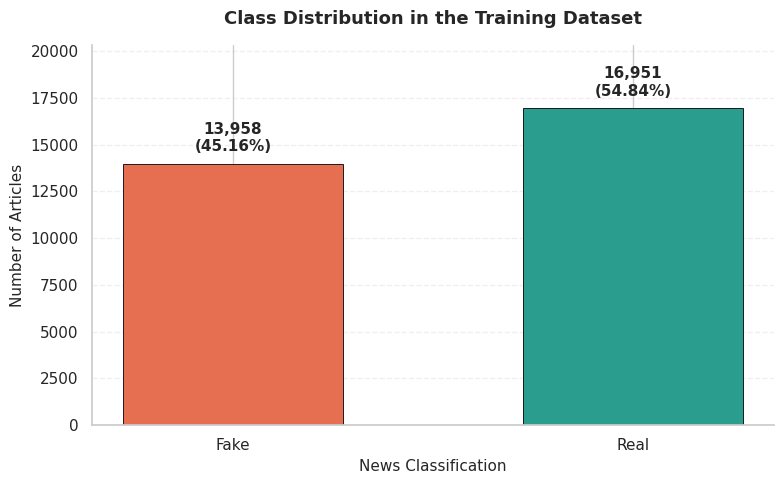


CLASS DISTRIBUTION SUMMARY
-------------------------------------------------------
Total training articles: 30909
Fake news proportion: 45.16%
Real news proportion: 54.84%

EDA interpretation: Class proportions will be considered when evaluating model performance.
Macro F1-score will be used alongside accuracy to provide a balanced comparison.


In [ ]:
# Import the required visualisation libraries
import matplotlib.pyplot as plt
import pandas as pd

# Define a consistent class order and colour scheme
class_order = ["Fake", "Real"]
class_colours = ["#E76F51", "#2A9D8F"]

# Count the number of training articles in each class
class_counts = (
    eda_df["class_name"]
    .value_counts()
    .reindex(class_order, fill_value=0)
)

# Calculate the percentage belonging to each class
class_percentages = (
    class_counts / class_counts.sum() * 100
)

# Create a summary table
class_summary = pd.DataFrame({
    "Article Count": class_counts,
    "Percentage (%)": class_percentages.round(2)
})

print("TRAINING DATASET CLASS DISTRIBUTION")
print("-" * 55)

display(class_summary)

# ------------------------------------------------------------
# Create the class distribution chart
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    class_counts.index,
    class_counts.values,
    color=class_colours,
    width=0.55,
    edgecolor="black",
    linewidth=0.6
)

# Display article counts and percentages above each bar
for bar, count, percentage in zip(
    bars,
    class_counts.values,
    class_percentages.values
):
    ax.annotate(
        f"{count:,}\n({percentage:.2f}%)",
        xy=(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height()
        ),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

# Add clear academic figure labels
ax.set_title(
    "Class Distribution in the Training Dataset",
    fontsize=13,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("News Classification", fontsize=11)
ax.set_ylabel("Number of Articles", fontsize=11)

# Start the vertical axis at zero
ax.set_ylim(
    0,
    class_counts.max() * 1.20
)

# Improve chart readability
ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

# Remove unnecessary chart borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Display a concise interpretation summary
# ------------------------------------------------------------

total_articles = int(class_counts.sum())

fake_percentage = class_percentages.loc["Fake"]
real_percentage = class_percentages.loc["Real"]

print("\nCLASS DISTRIBUTION SUMMARY")
print("-" * 55)

print("Total training articles:", total_articles)
print(f"Fake news proportion: {fake_percentage:.2f}%")
print(f"Real news proportion: {real_percentage:.2f}%")

print(
    "\nEDA interpretation: Class proportions will be "
    "considered when evaluating model performance."
)

print(
    "Macro F1-score will be used alongside accuracy "
    "to provide a balanced comparison."
)

# Confirm that only training records were analysed
assert total_articles == len(train_df), (
    "Class distribution does not match the training dataset."
)


**Cell 13**

ARTICLE AND HEADLINE LENGTH COMPARISON
------------------------------------------------------------


,Article_Median,Article_Q1,Article_Q3,Title_Median,Title_Q1,Title_Q3,Article_IQR,Title_IQR
class_name,,,,,,,,
Fake,377.0,279.0,504.0,14.0,12.0,16.0,225.0,4.0
Real,359.0,148.0,522.0,10.0,9.0,11.0,374.0,2.0


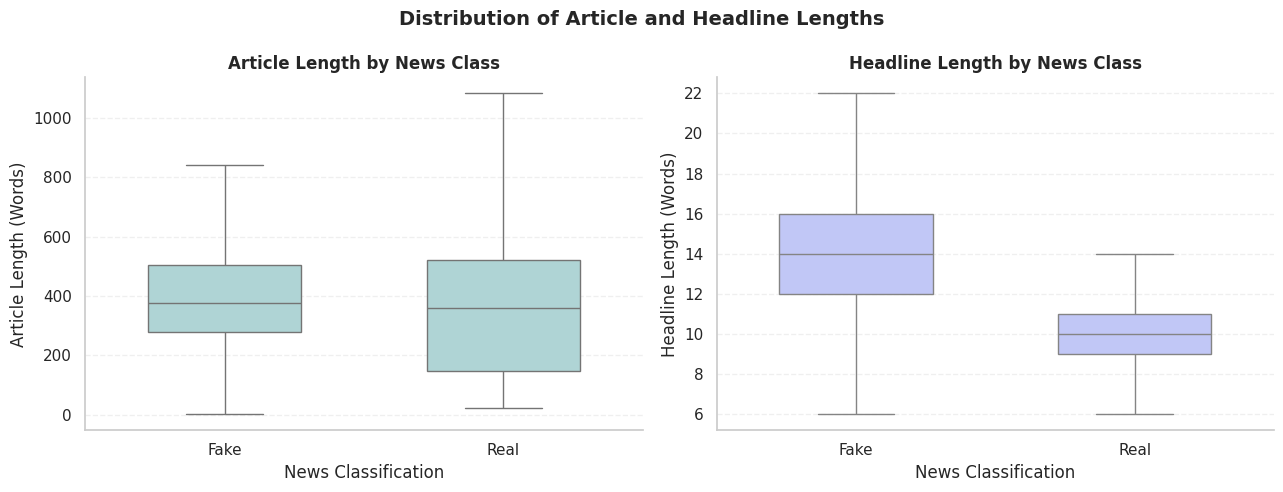


MEDIAN LENGTH COMPARISON
------------------------------------------------------------
Fake News: Median article length = 377 words; Median headline length = 14 words
Real News: Median article length = 359 words; Median headline length = 10 words

Outlier markers are hidden for visual clarity.
No outliers or articles were removed.


In [ ]:
# Import visualisation and data analysis libraries
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Use the training-only EDA dataset created in Cell 11
required_columns = [
    "class_name",
    "word_count",
    "title_word_count"
]

# Check that the required EDA data is available
if "eda_df" not in globals():
    raise RuntimeError(
        "Run Cell 11 before executing Cell 13."
    )

missing_columns = [
    col for col in required_columns
    if col not in eda_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing EDA columns: {missing_columns}"
    )

# Define class order and consistent colours
class_order = ["Fake", "Real"]

article_colour = "#A8DADC"
title_colour = "#B8C0FF"

# ------------------------------------------------------------
# 1. Calculate descriptive statistics
# ------------------------------------------------------------

# Compare the median and interquartile range (IQR)
# of article and headline lengths across both classes
length_comparison = (
    eda_df.groupby("class_name")
    .agg(
        Article_Median=("word_count", "median"),
        Article_Q1=("word_count", lambda x: x.quantile(0.25)),
        Article_Q3=("word_count", lambda x: x.quantile(0.75)),
        Title_Median=("title_word_count", "median"),
        Title_Q1=("title_word_count", lambda x: x.quantile(0.25)),
        Title_Q3=("title_word_count", lambda x: x.quantile(0.75))
    )
    .reindex(class_order)
)

# Calculate interquartile ranges
length_comparison["Article_IQR"] = (
    length_comparison["Article_Q3"]
    - length_comparison["Article_Q1"]
)

length_comparison["Title_IQR"] = (
    length_comparison["Title_Q3"]
    - length_comparison["Title_Q1"]
)

print("ARTICLE AND HEADLINE LENGTH COMPARISON")
print("-" * 60)

display(length_comparison.round(2))

# ------------------------------------------------------------
# 2. Create side-by-side boxplots
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5)
)

# Article word-count distribution
sns.boxplot(
    data=eda_df,
    x="class_name",
    y="word_count",
    order=class_order,
    showfliers=False,
    color=article_colour,
    width=0.55,
    ax=axes[0]
)

axes[0].set_title(
    "Article Length by News Class",
    fontsize=12,
    fontweight="bold"
)

axes[0].set_xlabel("News Classification")
axes[0].set_ylabel("Article Length (Words)")

# Headline word-count distribution
sns.boxplot(
    data=eda_df,
    x="class_name",
    y="title_word_count",
    order=class_order,
    showfliers=False,
    color=title_colour,
    width=0.55,
    ax=axes[1]
)

axes[1].set_title(
    "Headline Length by News Class",
    fontsize=12,
    fontweight="bold"
)

axes[1].set_xlabel("News Classification")
axes[1].set_ylabel("Headline Length (Words)")

# Improve the appearance of both figures
for ax in axes:
    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.3
    )

    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# Add the overall figure title
fig.suptitle(
    "Distribution of Article and Headline Lengths",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 3. Display a concise statistical comparison
# ------------------------------------------------------------

print("\nMEDIAN LENGTH COMPARISON")
print("-" * 60)

for news_class in class_order:
    article_median = length_comparison.loc[
        news_class, "Article_Median"
    ]

    title_median = length_comparison.loc[
        news_class, "Title_Median"
    ]

    print(
        f"{news_class} News: "
        f"Median article length = {article_median:.0f} words; "
        f"Median headline length = {title_median:.0f} words"
    )

# Validate that the analysis used training observations only
assert len(eda_df) == len(train_df), (
    "EDA dataset size differs from the training dataset."
)

print("\nOutlier markers are hidden for visual clarity.")
print("No outliers or articles were removed.")

**Cell 14**

SUBJECT CATEGORY DISTRIBUTION
------------------------------------------------------------


class_name,Fake,Real,Total
subject,,,
politicsNews,0,9053,9053
worldnews,0,7898,7898
News,7303,0,7303
politics,5094,0,5094
US_News,621,0,621
left-news,547,0,547
Government News,393,0,393



CLASS PERCENTAGES WITHIN EACH SUBJECT
------------------------------------------------------------


class_name,Fake,Real
subject,,
politicsNews,0.0,100.0
worldnews,0.0,100.0
News,100.0,0.0
politics,100.0,0.0
US_News,100.0,0.0
left-news,100.0,0.0
Government News,100.0,0.0


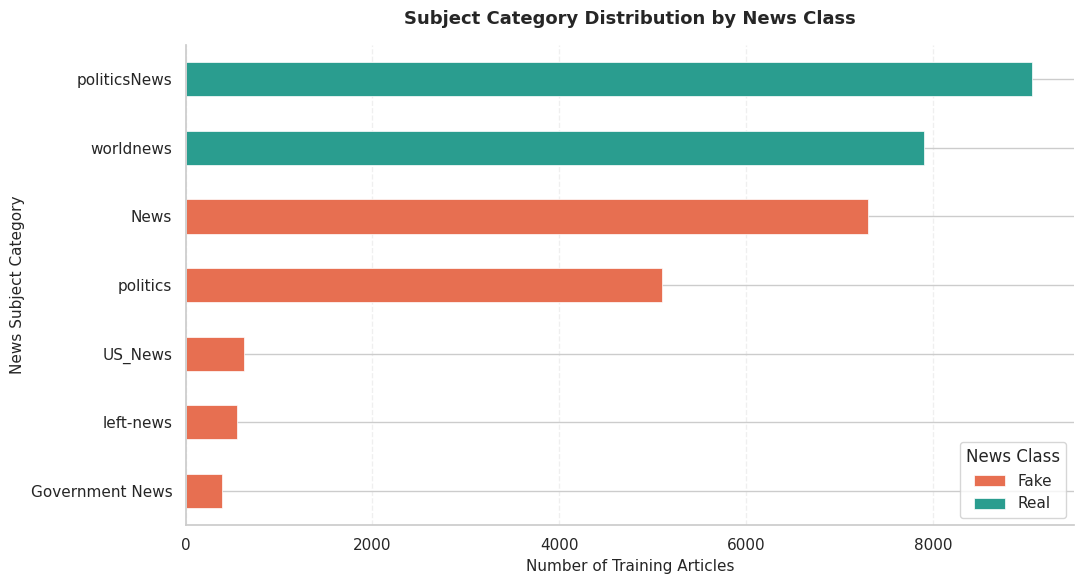


SUBJECT DISTRIBUTION SUMMARY
------------------------------------------------------------
Total subject categories: 7
Training articles analysed: 30909
Held-out test articles used: 0
Subject categories containing only one class: 7

Subject categories may reveal differences in dataset composition.
Subject metadata will not be used as a machine-learning input.


In [ ]:
# Use the training-only EDA dataset created in Cell 11.
# Subject categories are analysed for exploratory purposes
# and will not be included as model input features.

# Verify that the required columns are available.
required_columns = ["subject", "class_name"]

missing_columns = [
    column for column in required_columns
    if column not in eda_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing EDA columns: {missing_columns}"
    )

# Define the class order and consistent colours.
class_order = ["Fake", "Real"]
class_colours = ["#E76F51", "#2A9D8F"]

# ------------------------------------------------------------
# 1. Calculate subject distribution by news class
# ------------------------------------------------------------

# Count fake and real articles within each subject category.
subject_counts = pd.crosstab(
    eda_df["subject"].fillna("Missing"),
    eda_df["class_name"]
)

# Ensure both classes appear in a consistent order.
subject_counts = subject_counts.reindex(
    columns=class_order,
    fill_value=0
)

# Add the total number of articles in each subject.
subject_summary = subject_counts.copy()

subject_summary["Total"] = (
    subject_summary["Fake"] +
    subject_summary["Real"]
)

# Sort subject categories by total article count.
subject_summary = subject_summary.sort_values(
    by="Total",
    ascending=False
)

print("SUBJECT CATEGORY DISTRIBUTION")
print("-" * 60)

display(subject_summary)

# ------------------------------------------------------------
# 2. Calculate class percentages within each subject
# ------------------------------------------------------------

# Calculate the percentage of fake and real articles
# within each subject category.
subject_percentages = (
    subject_counts.div(
        subject_counts.sum(axis=1),
        axis=0
    ) * 100
).round(2)

# Arrange percentage results in the same order as counts.
subject_percentages = subject_percentages.reindex(
    subject_summary.index
)

print("\nCLASS PERCENTAGES WITHIN EACH SUBJECT")
print("-" * 60)

display(subject_percentages)

# ------------------------------------------------------------
# 3. Visualise subject distribution
# ------------------------------------------------------------

# Create a horizontal stacked bar chart.
fig, ax = plt.subplots(figsize=(11, 6))

subject_counts.loc[
    subject_summary.index
].plot(
    kind="barh",
    stacked=True,
    ax=ax,
    color=class_colours,
    edgecolor="white",
    linewidth=0.5
)

# Add academic figure titles and axis labels.
ax.set_title(
    "Subject Category Distribution by News Class",
    fontsize=13,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    "Number of Training Articles",
    fontsize=11
)

ax.set_ylabel(
    "News Subject Category",
    fontsize=11
)

# Display the class legend.
ax.legend(
    title="News Class",
    loc="lower right"
)

# Improve chart readability.
ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Display the largest subject at the top.
ax.invert_yaxis()

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4. Check the reliability of the EDA results
# ------------------------------------------------------------

# Confirm that every training article is represented.
assert subject_counts.to_numpy().sum() == len(eda_df), (
    "Subject counts do not match the training dataset."
)

# Confirm that all subject totals are positive.
assert (subject_summary["Total"] > 0).all(), (
    "An invalid subject count was detected."
)

# ------------------------------------------------------------
# 5. Display the interpretation summary
# ------------------------------------------------------------

print("\nSUBJECT DISTRIBUTION SUMMARY")
print("-" * 60)

print("Total subject categories:", len(subject_summary))

print("Training articles analysed:", len(eda_df))

print("Held-out test articles used: 0")

# Identify subject categories associated with a single class.
single_class_subjects = (
    (subject_counts["Fake"] == 0) |
    (subject_counts["Real"] == 0)
)

print(
    "Subject categories containing only one class:",
    int(single_class_subjects.sum())
)

print(
    "\nSubject categories may reveal differences "
    "in dataset composition."
)

print(
    "Subject metadata will not be used as a "
    "machine-learning input."
)


**Cell 15**

REUTERS SOURCE-RELATED TEXT ANALYSIS
------------------------------------------------------------

1. REUTERS FREQUENCY BY NEWS CLASS


,Articles_With_Reuters,Total_Articles,Articles_Without_Reuters,Reuters_Percentage
class_name,,,,
Fake,176,13958,13782,1.26
Real,16919,16951,32,99.81


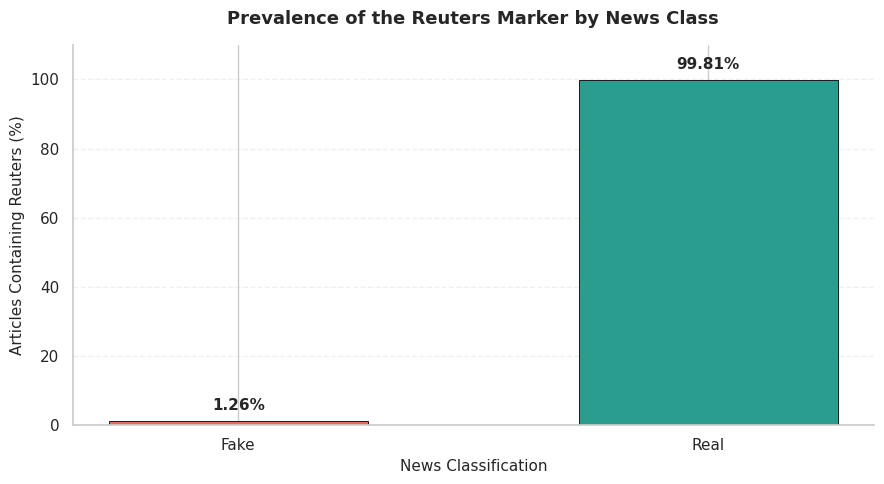


2. REUTERS PREVALENCE COMPARISON
------------------------------------------------------------
Fake articles containing Reuters: 1.26%
Real articles containing Reuters: 99.81%
Difference: 98.55 percentage points

3. INTERPRETATION
Differences in Reuters prevalence indicate source-related patterns within the dataset.
These patterns may influence classification because article bodies are used as model inputs.
Further sensitivity testing is required to assess model dependence on this marker.

Held-out test articles used: 0


In [ ]:
# This analysis investigates whether the word "Reuters"
# appears disproportionately in fake and real articles.
# Only training data is used for exploratory analysis.

import pandas as pd
import matplotlib.pyplot as plt

# Verify that the training EDA dataset is available
if "eda_df" not in globals():
    raise RuntimeError(
        "Run Cell 11 before executing Cell 15."
    )

required_columns = ["text", "class_name"]

missing_columns = [
    column for column in required_columns
    if column not in eda_df.columns
]

if missing_columns:
    raise ValueError(
        f"Required EDA columns are missing: {missing_columns}"
    )

# Define a consistent class order
class_order = ["Fake", "Real"]

# ------------------------------------------------------------
# 1. Identify the Reuters source-related marker
# ------------------------------------------------------------

# Search article bodies for the complete word "Reuters".
# The search ignores capitalisation and excludes partial matches.
eda_df["contains_reuters"] = (
    eda_df["text"]
    .fillna("")
    .astype(str)
    .str.contains(
        r"\breuters\b",
        case=False,
        regex=True,
        na=False
    )
)

# ------------------------------------------------------------
# 2. Calculate Reuters frequency by news class
# ------------------------------------------------------------

reuters_summary = (
    eda_df.groupby("class_name")["contains_reuters"]
    .agg(
        Articles_With_Reuters="sum",
        Total_Articles="count"
    )
    .reindex(class_order)
)

# Calculate articles without the Reuters marker
reuters_summary["Articles_Without_Reuters"] = (
    reuters_summary["Total_Articles"]
    - reuters_summary["Articles_With_Reuters"]
)

# Calculate the percentage containing the Reuters marker
reuters_summary["Reuters_Percentage"] = (
    reuters_summary["Articles_With_Reuters"]
    / reuters_summary["Total_Articles"]
    * 100
)

print("REUTERS SOURCE-RELATED TEXT ANALYSIS")
print("-" * 60)

print("\n1. REUTERS FREQUENCY BY NEWS CLASS")

display(reuters_summary.round(2))

# ------------------------------------------------------------
# 3. Visualise Reuters prevalence by class
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 5))

colours = ["#E76F51", "#2A9D8F"]

bars = ax.bar(
    reuters_summary.index,
    reuters_summary["Reuters_Percentage"],
    color=colours,
    width=0.55,
    edgecolor="black",
    linewidth=0.6
)

# Display percentages above the bars
for bar, percentage in zip(
    bars,
    reuters_summary["Reuters_Percentage"]
):
    ax.annotate(
        f"{percentage:.2f}%",
        xy=(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height()
        ),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

# Add clear academic figure labels
ax.set_title(
    "Prevalence of the Reuters Marker by News Class",
    fontsize=13,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    "News Classification",
    fontsize=11
)

ax.set_ylabel(
    "Articles Containing Reuters (%)",
    fontsize=11
)

ax.set_ylim(0, 110)

# Improve chart readability
ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4. Calculate the difference in Reuters prevalence
# ------------------------------------------------------------

fake_percentage = reuters_summary.loc[
    "Fake", "Reuters_Percentage"
]

real_percentage = reuters_summary.loc[
    "Real", "Reuters_Percentage"
]

percentage_difference = (
    real_percentage - fake_percentage
)

print("\n2. REUTERS PREVALENCE COMPARISON")
print("-" * 60)

print(
    f"Fake articles containing Reuters: "
    f"{fake_percentage:.2f}%"
)

print(
    f"Real articles containing Reuters: "
    f"{real_percentage:.2f}%"
)

print(
    f"Difference: {percentage_difference:.2f} "
    "percentage points"
)

# ------------------------------------------------------------
# 5. Validate the analysis
# ------------------------------------------------------------

# Confirm all training articles are represented
assert (
    reuters_summary["Total_Articles"].sum()
    == len(eda_df)
), "Reuters analysis does not cover all training articles."

# Confirm Reuters counts do not exceed class totals
assert (
    reuters_summary["Articles_With_Reuters"]
    <= reuters_summary["Total_Articles"]
).all(), "Invalid Reuters frequency detected."

print("\n3. INTERPRETATION")

print(
    "Differences in Reuters prevalence indicate "
    "source-related patterns within the dataset."
)

print(
    "These patterns may influence classification "
    "because article bodies are used as model inputs."
)

print(
    "Further sensitivity testing is required to "
    "assess model dependence on this marker."
)

print("\nHeld-out test articles used: 0")

**Cell 16**

DISTINCTIVE VOCABULARY ANALYSIS
------------------------------------------------------------

1. WORDS MORE PREVALENT IN FAKE NEWS


,Word,Fake (%),Real (%),Difference (pp)
4799,video,22.59,2.88,19.71
4871,watch,22.27,1.98,20.30
945,com,21.30,0.86,20.44
2558,know,30.36,8.18,22.17
2265,images,23.77,0.90,22.87
1994,getty,23.21,0.01,23.21
2674,like,46.31,15.93,30.38
2519,just,53.60,16.35,37.24
1799,featured,46.32,0.41,45.91
2264,image,50.59,1.35,49.24



2. WORDS MORE PREVALENT IN REAL NEWS


,Word,Fake (%),Real (%),Real Advantage (pp)
4278,state,24.04,40.09,16.05
4560,thursday,7.54,24.79,17.26
4581,told,25.34,42.77,17.43
4669,tuesday,8.32,26.56,18.24
4893,wednesday,7.26,25.73,18.48
2892,minister,2.49,23.39,20.89
2028,government,17.84,39.04,21.20
4868,washington,13.10,42.18,29.08
3952,said,56.61,93.55,36.95
3848,reuters,1.26,99.81,98.55


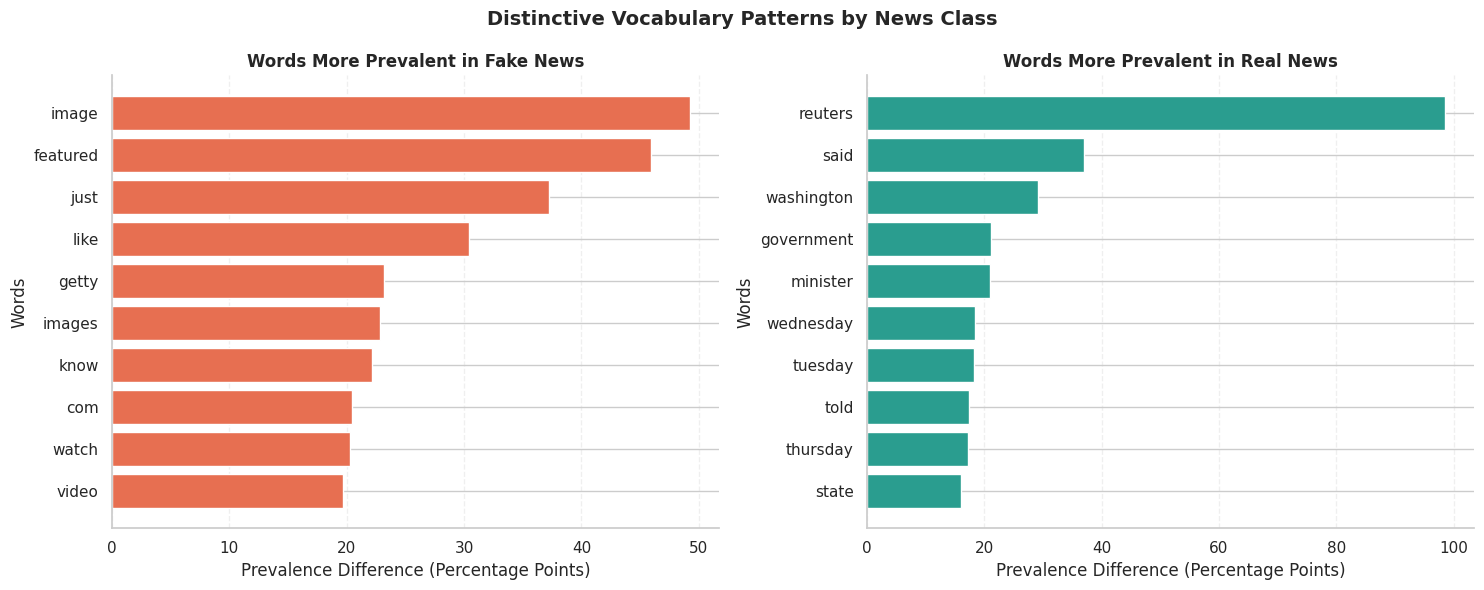


3. VOCABULARY ANALYSIS SUMMARY
------------------------------------------------------------
Fake training articles: 13958
Real training articles: 16951
Total articles analysed: 30909
Vocabulary terms analysed: 5000

All vocabulary validation checks passed.
Held-out test articles used: 0

4. INTERPRETATION
------------------------------------------------------------
The analysis identifies words that appear in different proportions of Fake and Real articles.
Strong vocabulary differences may reflect news topics, writing styles, or source-related patterns.
These associations do not independently establish whether an article is factually accurate.
Later model evaluation will examine whether source-related features affect classification reliability.


In [ ]:
# Compare word prevalence between Fake and Real news.
# Investigate vocabulary patterns and possible source bias.
# Only training data is used to protect the held-out test set.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import CountVectorizer
from IPython.display import display


# ------------------------------------------------------------
# 1. VALIDATE THE TRAINING DATA
# ------------------------------------------------------------

if "eda_df" not in globals():
    raise RuntimeError(
        "Run Cell 11 before executing Cell 16."
    )

required_columns = ["text", "label"]

missing_columns = [
    column for column in required_columns
    if column not in eda_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# Use article bodies from the training data only
eda_text = (
    eda_df["text"]
    .fillna("")
    .astype(str)
)

eda_labels = eda_df["label"].to_numpy()

# Identify the two news classes
fake_mask = eda_labels == 0
real_mask = eda_labels == 1

fake_count = int(fake_mask.sum())
real_count = int(real_mask.sum())

if fake_count == 0 or real_count == 0:
    raise ValueError(
        "Both Fake and Real classes must be present."
    )


# ------------------------------------------------------------
# 2. EXTRACT WORD-PRESENCE FEATURES
# ------------------------------------------------------------

# Binary=True records whether a word appears in an article.
# Repeated appearances within one article are counted once.
#
# Stop-word removal is used for EDA only.
# It does not change the later TF-IDF model configuration.

eda_vectorizer = CountVectorizer(
    lowercase=True,
    stop_words="english",
    binary=True,
    min_df=30,
    max_features=5000
)

word_matrix = eda_vectorizer.fit_transform(
    eda_text
)

# Obtain the vocabulary
vocabulary = eda_vectorizer.get_feature_names_out()


# ------------------------------------------------------------
# 3. CALCULATE WORD PREVALENCE BY CLASS
# ------------------------------------------------------------

# Percentage of Fake articles containing each word
fake_prevalence = (
    np.asarray(
        word_matrix[fake_mask].sum(axis=0)
    ).ravel()
    / fake_count
    * 100
)

# Percentage of Real articles containing each word
real_prevalence = (
    np.asarray(
        word_matrix[real_mask].sum(axis=0)
    ).ravel()
    / real_count
    * 100
)

# Create the comparison table
word_prevalence = pd.DataFrame({
    "Word": vocabulary,
    "Fake (%)": fake_prevalence,
    "Real (%)": real_prevalence
})

# Calculate the percentage-point difference
word_prevalence["Difference (pp)"] = (
    word_prevalence["Fake (%)"]
    - word_prevalence["Real (%)"]
)

# Positive differences: word is more prevalent in Fake.
# Negative differences: word is more prevalent in Real.


# ------------------------------------------------------------
# 4. IDENTIFY DISTINCTIVE WORDS
# ------------------------------------------------------------

# Select the ten words most prevalent in Fake news
# relative to Real news.
top_fake_words = (
    word_prevalence.loc[
        word_prevalence["Difference (pp)"] > 0
    ]
    .nlargest(10, "Difference (pp)")
    .sort_values("Difference (pp)")
    .copy()
)

# Select the ten words most prevalent in Real news
# relative to Fake news.
top_real_words = (
    word_prevalence.loc[
        word_prevalence["Difference (pp)"] < 0
    ]
    .nsmallest(10, "Difference (pp)")
    .copy()
)

# Convert negative differences to positive magnitudes
# for the Real news visualisation.
top_real_words["Real Advantage (pp)"] = (
    -top_real_words["Difference (pp)"]
)

top_real_words = top_real_words.sort_values(
    "Real Advantage (pp)"
)

print("DISTINCTIVE VOCABULARY ANALYSIS")
print("-" * 60)

print("\n1. WORDS MORE PREVALENT IN FAKE NEWS")

display(
    top_fake_words[
        ["Word", "Fake (%)", "Real (%)", "Difference (pp)"]
    ].round(2)
)

print("\n2. WORDS MORE PREVALENT IN REAL NEWS")

display(
    top_real_words[
        ["Word", "Fake (%)", "Real (%)", "Real Advantage (pp)"]
    ].round(2)
)


# ------------------------------------------------------------
# 5. VISUALISE VOCABULARY DIFFERENCES
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 6)
)

# Fake news vocabulary chart
axes[0].barh(
    top_fake_words["Word"],
    top_fake_words["Difference (pp)"],
    color="#E76F51",
    edgecolor="white"
)

axes[0].set_title(
    "Words More Prevalent in Fake News",
    fontsize=12,
    fontweight="bold"
)

axes[0].set_xlabel(
    "Prevalence Difference (Percentage Points)"
)

axes[0].set_ylabel("Words")

# Real news vocabulary chart
axes[1].barh(
    top_real_words["Word"],
    top_real_words["Real Advantage (pp)"],
    color="#2A9D8F",
    edgecolor="white"
)

axes[1].set_title(
    "Words More Prevalent in Real News",
    fontsize=12,
    fontweight="bold"
)

axes[1].set_xlabel(
    "Prevalence Difference (Percentage Points)"
)

axes[1].set_ylabel("Words")

# Improve chart readability
for ax in axes:
    ax.grid(
        axis="x",
        linestyle="--",
        alpha=0.3
    )

    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "Distinctive Vocabulary Patterns by News Class",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6. VALIDATE VOCABULARY ANALYSIS
# ------------------------------------------------------------

print("\n3. VOCABULARY ANALYSIS SUMMARY")
print("-" * 60)

print("Fake training articles:", fake_count)
print("Real training articles:", real_count)
print("Total articles analysed:", fake_count + real_count)
print("Vocabulary terms analysed:", len(vocabulary))

# Verify that all training records are included
assert fake_count + real_count == len(train_df), (
    "Vocabulary analysis does not match training data."
)

# CORRECTED VALIDATION:
# Check that every percentage lies between 0 and 100.
prevalence_values = word_prevalence[
    ["Fake (%)", "Real (%)"]
]

assert (
    (prevalence_values >= 0)
    & (prevalence_values <= 100)
).all().all(), (
    "Invalid word prevalence percentages detected."
)

# Check that no calculated prevalence values are missing
assert prevalence_values.notna().all().all(), (
    "Missing word prevalence values detected."
)

print("\nAll vocabulary validation checks passed.")
print("Held-out test articles used: 0")


# ------------------------------------------------------------
# 7. INTERPRETATION
# ------------------------------------------------------------

print("\n4. INTERPRETATION")
print("-" * 60)

print(
    "The analysis identifies words that appear in "
    "different proportions of Fake and Real articles."
)

print(
    "Strong vocabulary differences may reflect "
    "news topics, writing styles, or source-related patterns."
)

print(
    "These associations do not independently establish "
    "whether an article is factually accurate."
)

print(
    "Later model evaluation will examine whether "
    "source-related features affect classification reliability."
)


**Cell 17**

In [ ]:
# Import the required libraries
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import StratifiedKFold

# ------------------------------------------------------------
# 1. VERIFY THE TRAINING DATA
# ------------------------------------------------------------

# Confirm that the training features and labels are available
required_variables = ["X_train", "y_train", "RANDOM_STATE"]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Run the earlier notebook cells first. Missing: "
        + ", ".join(missing_variables)
    )

# Confirm the number of training articles matches the labels
assert len(X_train) == len(y_train), (
    "Training features and labels have different lengths."
)

# Confirm that both classification labels are present
assert set(y_train.unique()) == {0, 1}, (
    "Training labels must contain Fake (0) and Real (1)."
)

# ------------------------------------------------------------
# 2. DEFINE SHARED TF-IDF SETTINGS
# ------------------------------------------------------------

# All three models will use the same feature representation.
# This allows differences in model performance to be compared
# without differences in TF-IDF settings.

tfidf_settings = {
    "lowercase": True,
    "ngram_range": (1, 1),
    "min_df": 3,
    "max_df": 1.0,
    "max_features": 3000,
    "sublinear_tf": False,
    "norm": "l2",
    "stop_words": None
}

# Important:
# TF-IDF is configured here but not fitted.
# It will be fitted inside each model pipeline to prevent
# information leakage during cross-validation.

# ------------------------------------------------------------
# 3. CONFIGURE STRATIFIED CROSS-VALIDATION
# ------------------------------------------------------------

# Use five folds with class stratification.
# Shuffling and a fixed seed make the splits reproducible.

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Confirm that each class contains enough observations
class_counts = y_train.value_counts()

assert class_counts.min() >= cv.n_splits, (
    "Each class must contain at least five observations."
)

# ------------------------------------------------------------
# 4. DEFINE CONSISTENT EVALUATION METRICS
# ------------------------------------------------------------

# Macro-averaged metrics give equal importance to
# Fake and Real classes, regardless of class frequency.

scoring = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro",
    "roc_auc": "roc_auc"
}

# Macro F1 is the primary model comparison metric
primary_metric = "f1_macro"

# ------------------------------------------------------------
# 5. USE THE SAME FOLDS FOR HYPERPARAMETER TUNING
# ------------------------------------------------------------

# Reuse the same stratified splits during model tuning.
# The held-out test data will not be used for tuning.

tuning_cv = cv

# ------------------------------------------------------------
# 6. DISPLAY AND VALIDATE THE CONFIGURATION
# ------------------------------------------------------------

print("MODEL CONFIGURATION SUMMARY")
print("-" * 60)

print("Random state:", RANDOM_STATE)

print("\nTF-IDF CONFIGURATION")
print("-" * 60)

for setting, value in tfidf_settings.items():
    print(f"{setting}: {value}")

print("\nCROSS-VALIDATION CONFIGURATION")
print("-" * 60)

print("Cross-validation method: StratifiedKFold")
print("Number of folds:", cv.n_splits)
print("Shuffle enabled:", cv.shuffle)
print("Random state:", cv.random_state)

print("\nMODEL EVALUATION METRICS")
print("-" * 60)

for metric in scoring:
    print(metric)

print("\nPrimary evaluation metric:", primary_metric)

print("\nTRAINING DATA VALIDATION")
print("-" * 60)

print("Training articles:", len(X_train))
print("Fake articles:", int(class_counts.loc[0]))
print("Real articles:", int(class_counts.loc[1]))

# Verify the reproducibility settings
assert cv.n_splits == 5
assert cv.random_state == RANDOM_STATE
assert tuning_cv is cv

print("\nAll configuration checks passed.")
print("TF-IDF has not been fitted.")
print("Held-out test articles used: 0")

MODEL CONFIGURATION SUMMARY
------------------------------------------------------------
Random state: 42

TF-IDF CONFIGURATION
------------------------------------------------------------
lowercase: True
ngram_range: (1, 1)
min_df: 3
max_df: 1.0
max_features: 3000
sublinear_tf: False
norm: l2
stop_words: None

CROSS-VALIDATION CONFIGURATION
------------------------------------------------------------
Cross-validation method: StratifiedKFold
Number of folds: 5
Shuffle enabled: True
Random state: 42

MODEL EVALUATION METRICS
------------------------------------------------------------
accuracy
precision_macro
recall_macro
f1_macro
roc_auc

Primary evaluation metric: f1_macro

TRAINING DATA VALIDATION
------------------------------------------------------------
Training articles: 30909
Fake articles: 13958
Real articles: 16951

All configuration checks passed.
TF-IDF has not been fitted.
Held-out test articles used: 0


**Cell 17**

In [ ]:
# Import the cross-validation tool
from sklearn.model_selection import StratifiedKFold

# Set a fixed random seed for reproducibility
RANDOM_STATE = 42

# Use the same TF-IDF settings for all three models
tfidf_settings = {
    "lowercase": True,
    "ngram_range": (1, 1),
    "min_df": 3,
    "max_features": 3000
}

# Create five reproducible folds that preserve class proportions
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Define evaluation metrics
scoring = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro",
    "roc_auc": "roc_auc"
}

# Display the configuration
print("Random state:", RANDOM_STATE)
print("TF-IDF settings:", tfidf_settings)
print("Cross-validation folds:", cv.n_splits)

Random state: 42
TF-IDF settings: {'lowercase': True, 'ngram_range': (1, 1), 'min_df': 3, 'max_features': 3000}
Cross-validation folds: 5


**Cell 18**

In [ ]:
# This cell defines three baseline classification models.
# All models use the same TF-IDF configuration from Cell 17.
# Feature extraction takes place inside each pipeline to
# prevent information leakage during cross-validation.

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from xgboost import XGBClassifier

# ------------------------------------------------------------
# 1. VERIFY THE REQUIRED CONFIGURATION
# ------------------------------------------------------------

required_variables = [
    "tfidf_settings",
    "RANDOM_STATE",
    "cv",
    "X_train",
    "y_train"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Run the earlier cells first. Missing: "
        + ", ".join(missing_variables)
    )

# ------------------------------------------------------------
# 2. LOGISTIC REGRESSION PIPELINE
# ------------------------------------------------------------

# Logistic Regression provides an interpretable linear
# classification baseline with L2 regularisation.

lr_pipeline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(**tfidf_settings)
    ),
    (
        "model",
        LogisticRegression(
            C=1.0,
            penalty="l2",
            solver="liblinear",
            max_iter=2000,
            random_state=RANDOM_STATE
        )
    )
])

# ------------------------------------------------------------
# 3. MULTINOMIAL NAIVE BAYES PIPELINE
# ------------------------------------------------------------

# Multinomial Naive Bayes provides a probabilistic baseline.
# Alpha controls additive smoothing of feature probabilities.

nb_pipeline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(**tfidf_settings)
    ),
    (
        "model",
        MultinomialNB(
            alpha=1.0
        )
    )
])

# ------------------------------------------------------------
# 4. XGBOOST PIPELINE
# ------------------------------------------------------------

# XGBoost uses gradient-boosted decision trees.
# Its nonlinear learning approach allows comparison with
# Logistic Regression and Multinomial Naive Bayes.

xgb_pipeline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(**tfidf_settings)
    ),
    (
        "model",
        XGBClassifier(
            n_estimators=50,
            max_depth=3,
            learning_rate=0.1,
            tree_method="hist",
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=2
        )
    )
])

# ------------------------------------------------------------
# 5. STORE THE THREE BASELINE MODELS
# ------------------------------------------------------------

# This dictionary will be reused during cross-validation,
# baseline evaluation and overfitting diagnostics.

base_models = {
    "Logistic Regression": lr_pipeline,
    "Multinomial Naive Bayes": nb_pipeline,
    "XGBoost": xgb_pipeline
}

# ------------------------------------------------------------
# 6. VERIFY CONSISTENT FEATURE EXTRACTION
# ------------------------------------------------------------

# Confirm that every model uses the specified TF-IDF settings.

for model_name, pipeline in base_models.items():

    assert isinstance(
        pipeline.named_steps["tfidf"],
        TfidfVectorizer
    ), f"{model_name} is missing TF-IDF."

    actual_settings = (
        pipeline.named_steps["tfidf"].get_params()
    )

    for setting, expected_value in tfidf_settings.items():

        assert actual_settings[setting] == expected_value, (
            f"{model_name} has inconsistent "
            f"TF-IDF setting: {setting}"
        )

# Confirm that the models use independent vectorizer objects
assert len({
    id(pipeline.named_steps["tfidf"])
    for pipeline in base_models.values()
}) == 3, (
    "Each pipeline must contain its own TF-IDF vectorizer."
)

# ------------------------------------------------------------
# 7. DISPLAY THE MODEL CONFIGURATION
# ------------------------------------------------------------

print("BASELINE MACHINE-LEARNING PIPELINES")
print("-" * 60)

for model_name, pipeline in base_models.items():

    print(f"\nModel: {model_name}")
    print(
        "Feature extraction:",
        type(pipeline.named_steps["tfidf"]).__name__
    )
    print(
        "Classifier:",
        type(pipeline.named_steps["model"]).__name__
    )

print("\nCOMMON EXPERIMENTAL SETTINGS")
print("-" * 60)

print("Training articles:", len(X_train))
print("TF-IDF maximum features:", tfidf_settings["max_features"])
print("N-gram range:", tfidf_settings["ngram_range"])
print("Cross-validation folds:", cv.n_splits)
print("Random state:", RANDOM_STATE)

print("\nAll three pipelines created successfully.")
print("TF-IDF settings verified across all models.")
print("Models have not been trained yet.")


BASELINE MACHINE-LEARNING PIPELINES
------------------------------------------------------------

Model: Logistic Regression
Feature extraction: TfidfVectorizer
Classifier: LogisticRegression

Model: Multinomial Naive Bayes
Feature extraction: TfidfVectorizer
Classifier: MultinomialNB

Model: XGBoost
Feature extraction: TfidfVectorizer
Classifier: XGBClassifier

COMMON EXPERIMENTAL SETTINGS
------------------------------------------------------------
Training articles: 30909
TF-IDF maximum features: 3000
N-gram range: (1, 1)
Cross-validation folds: 5
Random state: 42

All three pipelines created successfully.
TF-IDF settings verified across all models.
Models have not been trained yet.


**Cell 19**

In [ ]:

# Evaluate all three models using identical validation folds.
# Compare training and validation performance to investigate
# potential underfitting and overfitting.

from sklearn.model_selection import cross_validate

# Store the results for later comparisons
baseline_cv_results = {}
fold_records = []
summary_records = []

# ------------------------------------------------------------
# 1. EVALUATE ALL THREE BASELINE MODELS
# ------------------------------------------------------------

for model_name, pipeline in base_models.items():

    print(f"Evaluating {model_name}...")

    # Fit and evaluate the pipeline across five folds.
    # TF-IDF is fitted separately within each training fold.
    results = cross_validate(
        estimator=pipeline,
        X=X_train,
        y=y_train,
        scoring=scoring,
        cv=cv,
        return_train_score=True,
        n_jobs=1,
        error_score="raise"
    )

    baseline_cv_results[model_name] = results

    # --------------------------------------------------------
    # 2. RECORD THE SCORES FROM EACH FOLD
    # --------------------------------------------------------

    for fold_number in range(cv.n_splits):

        fold_records.append({
            "Model": model_name,
            "Fold": fold_number + 1,

            "Training Macro F1":
                results["train_f1_macro"][fold_number],

            "Validation Macro F1":
                results["test_f1_macro"][fold_number],

            "Training ROC-AUC":
                results["train_roc_auc"][fold_number],

            "Validation ROC-AUC":
                results["test_roc_auc"][fold_number]
        })

    # --------------------------------------------------------
    # 3. CALCULATE AVERAGE PERFORMANCE
    # --------------------------------------------------------

    train_f1 = results["train_f1_macro"].mean()
    val_f1 = results["test_f1_macro"].mean()

    train_auc = results["train_roc_auc"].mean()
    val_auc = results["test_roc_auc"].mean()

    # Calculate training-validation performance gaps.
    # A large positive gap can indicate overfitting.
    f1_gap = train_f1 - val_f1
    auc_gap = train_auc - val_auc

    summary_records.append({
        "Model": model_name,

        "CV Accuracy":
            results["test_accuracy"].mean(),

        "CV Precision (Macro)":
            results["test_precision_macro"].mean(),

        "CV Recall (Macro)":
            results["test_recall_macro"].mean(),

        "Training Macro F1": train_f1,

        "CV Macro F1": val_f1,

        "CV F1 Std":
            results["test_f1_macro"].std(ddof=1),

        "F1 Train–CV Gap": f1_gap,

        "Training ROC-AUC": train_auc,

        "CV ROC-AUC": val_auc,

        "AUC Train–CV Gap": auc_gap
    })

# ------------------------------------------------------------
# 4. PREPARE THE COMPARISON TABLES
# ------------------------------------------------------------

baseline_fold_scores = pd.DataFrame(fold_records)

baseline_summary = (
    pd.DataFrame(summary_records)
    .sort_values(
        "CV Macro F1",
        ascending=False
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 5. DISPLAY BASELINE PERFORMANCE
# ------------------------------------------------------------

print("\nBASELINE MODEL COMPARISON — FIVE-FOLD CV")
print("-" * 65)

display(baseline_summary.round(6))

print("\nFOLD-BY-FOLD TRAINING AND VALIDATION RESULTS")
print("-" * 65)

display(baseline_fold_scores.round(6))

# ------------------------------------------------------------
# 6. VALIDATE THE EVALUATION RESULTS
# ------------------------------------------------------------

# All three models must have five fold-level records.
assert (
    len(baseline_fold_scores)
    == len(base_models) * cv.n_splits
), "Incomplete cross-validation results."

# Performance scores must lie between 0 and 1.
assert baseline_summary["CV Macro F1"].between(0, 1).all(), (
    "Invalid macro F1-score detected."
)

assert baseline_summary["CV ROC-AUC"].between(0, 1).all(), (
    "Invalid ROC-AUC score detected."
)

# ------------------------------------------------------------
# 7. CONFIRM THE EVALUATION PROCEDURE
# ------------------------------------------------------------

print("\nCross-validation completed for all three baseline models.")

print("Validation method: Five-fold StratifiedKFold")
print("Primary comparison metric: Macro F1")
print("Training and validation gaps have been calculated.")

print("\nThe held-out test set has not been used.")
print("These are cross-validation scores, not final test results.")

Evaluating Logistic Regression...
Evaluating Multinomial Naive Bayes...
Evaluating XGBoost...

BASELINE MODEL COMPARISON — FIVE-FOLD CV
-----------------------------------------------------------------


,Model,CV Accuracy,CV Precision (Macro),CV Recall (Macro),Training Macro F1,CV Macro F1,CV F1 Std,F1 Train–CV Gap,Training ROC-AUC,CV ROC-AUC,AUC Train–CV Gap
0,XGBoost,0.995697,0.995881,0.995438,0.996431,0.995654,0.000977,0.000776,0.999823,0.999449,0.000374
1,Logistic Regression,0.984471,0.984787,0.983881,0.988341,0.984309,0.001416,0.004031,0.998975,0.998364,0.000611
2,Multinomial Naive Bayes,0.934841,0.934359,0.934091,0.935540,0.934206,0.004810,0.001333,0.983218,0.982466,0.000752



FOLD-BY-FOLD TRAINING AND VALIDATION RESULTS
-----------------------------------------------------------------


,Model,Fold,Training Macro F1,Validation Macro F1,Training ROC-AUC,Validation ROC-AUC
0,Logistic Regression,1,0.989134,0.982341,0.998969,0.998283
1,Logistic Regression,2,0.987417,0.986104,0.998915,0.998754
2,Logistic Regression,3,0.988233,0.983831,0.999097,0.997593
3,Logistic Regression,4,0.988439,0.985128,0.998977,0.998592
4,Logistic Regression,5,0.988480,0.984143,0.998916,0.998599
5,Multinomial Naive Bayes,1,0.936703,0.932024,0.983409,0.982531
6,Multinomial Naive Bayes,2,0.935041,0.937534,0.983014,0.984116
7,Multinomial Naive Bayes,3,0.936587,0.929529,0.983634,0.980479
8,Multinomial Naive Bayes,4,0.933959,0.940901,0.982774,0.984159
9,Multinomial Naive Bayes,5,0.935408,0.931044,0.983259,0.981047



Cross-validation completed for all three baseline models.
Validation method: Five-fold StratifiedKFold
Primary comparison metric: Macro F1
Training and validation gaps have been calculated.

The held-out test set has not been used.
These are cross-validation scores, not final test results.


**Cell 20**


BASELINE MODEL: LOGISTIC REGRESSION

CLASSIFICATION REPORT
-----------------------------------------------------------------
              precision    recall  f1-score   support

        Fake     0.9877    0.9778    0.9827     13958
        Real     0.9819    0.9900    0.9859     16951

    accuracy                         0.9845     30909
   macro avg     0.9848    0.9839    0.9843     30909
weighted avg     0.9845    0.9845    0.9845     30909


CONFUSION MATRIX
-----------------------------------------------------------------


,Predicted Fake,Predicted Real
Actual Fake,13648,310
Actual Real,170,16781



CLASSIFICATION ERROR ANALYSIS
Fake articles predicted as Real: 310
Real articles predicted as Fake: 170
Total classification errors: 480

BASELINE MODEL: MULTINOMIAL NAIVE BAYES

CLASSIFICATION REPORT
-----------------------------------------------------------------
              precision    recall  f1-score   support

        Fake     0.9291    0.9264    0.9277     13958
        Real     0.9395    0.9418    0.9407     16951

    accuracy                         0.9348     30909
   macro avg     0.9343    0.9341    0.9342     30909
weighted avg     0.9348    0.9348    0.9348     30909


CONFUSION MATRIX
-----------------------------------------------------------------


,Predicted Fake,Predicted Real
Actual Fake,12930,1028
Actual Real,986,15965



CLASSIFICATION ERROR ANALYSIS
Fake articles predicted as Real: 1028
Real articles predicted as Fake: 986
Total classification errors: 2014

BASELINE MODEL: XGBOOST

CLASSIFICATION REPORT
-----------------------------------------------------------------
              precision    recall  f1-score   support

        Fake     0.9977    0.9928    0.9952     13958
        Real     0.9941    0.9981    0.9961     16951

    accuracy                         0.9957     30909
   macro avg     0.9959    0.9954    0.9957     30909
weighted avg     0.9957    0.9957    0.9957     30909


CONFUSION MATRIX
-----------------------------------------------------------------


,Predicted Fake,Predicted Real
Actual Fake,13857,101
Actual Real,32,16919



CLASSIFICATION ERROR ANALYSIS
Fake articles predicted as Real: 101
Real articles predicted as Fake: 32
Total classification errors: 133

BASELINE MODEL COMPARISON


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Fake Predicted Real,Real Predicted Fake,Total Errors
0,XGBoost,0.995697,0.995881,0.995438,0.995654,101,32,133
1,Logistic Regression,0.984471,0.984780,0.983881,0.984309,310,170,480
2,Multinomial Naive Bayes,0.934841,0.934325,0.934091,0.934207,1028,986,2014


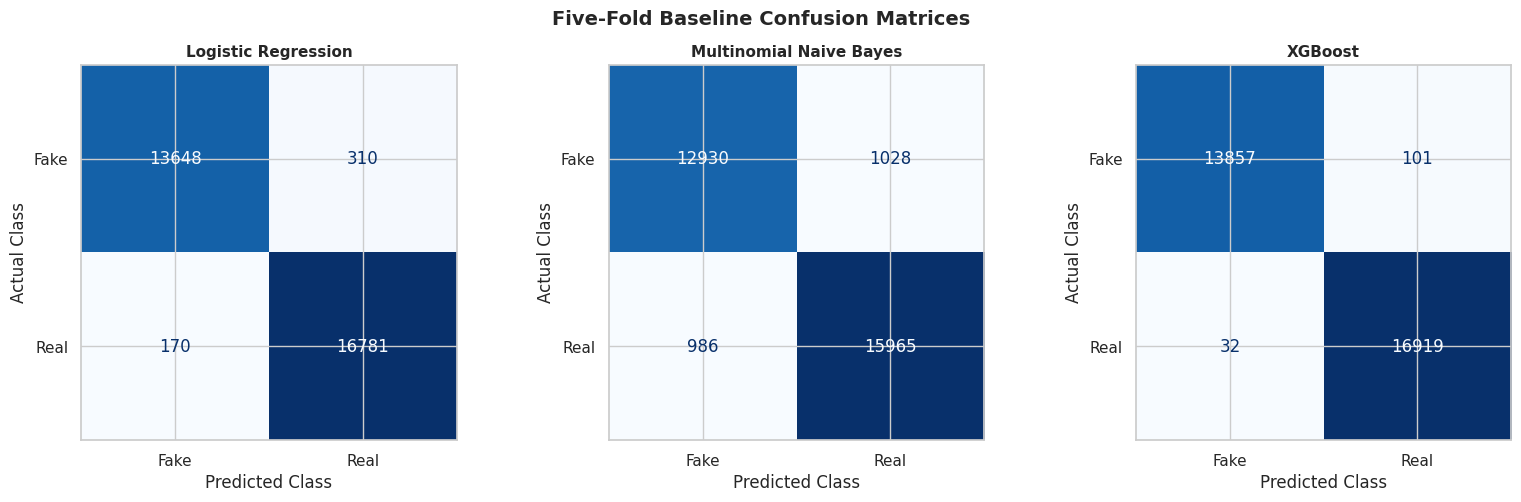


BASELINE EVALUATION COMPLETED SUCCESSFULLY
-----------------------------------------------------------------
Models evaluated: 3
Validation method: Five-fold StratifiedKFold
Primary metric: Macro F1
Training articles evaluated: 30909
Held-out test articles used: 0

Out-of-fold predictions have been saved.
Prediction probabilities have been saved.
Confusion matrices have been saved.

Cell 20 completed successfully.


In [ ]:
# Purpose:
# Evaluate the three baseline models using out-of-fold predictions.
# Examine classification performance and the types of errors.
# Use five-fold cross-validation on training data only.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ------------------------------------------------------------
# 1. VALIDATE THE REQUIRED VARIABLES
# ------------------------------------------------------------

required_variables = [
    "base_models",
    "X_train",
    "y_train",
    "cv"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Please execute the previous cells first. Missing: "
        + ", ".join(missing_variables)
    )

if len(X_train) != len(y_train):
    raise ValueError(
        "Training features and labels have different lengths."
    )

y_true = np.asarray(y_train)

if set(np.unique(y_true)) != {0, 1}:
    raise ValueError(
        "Class labels must be Fake = 0 and Real = 1."
    )

# ------------------------------------------------------------
# 2. PREPARE STORAGE FOR MODEL RESULTS
# ------------------------------------------------------------

# Save predictions for later error analysis.
baseline_oof_predictions = {}

# Save the probability of class 1 (Real news).
# These probabilities will be used for ROC/PR analysis.
baseline_oof_probabilities = {}

# Store confusion matrices for plotting.
baseline_confusion_matrices = {}

# Store model comparison metrics.
baseline_comparison_records = []

class_labels = ["Fake", "Real"]

# ------------------------------------------------------------
# 3. GENERATE FIVE-FOLD OUT-OF-FOLD PREDICTIONS
# ------------------------------------------------------------

for model_name, pipeline in base_models.items():

    print("\n" + "=" * 65)
    print(f"BASELINE MODEL: {model_name.upper()}")
    print("=" * 65)

    # Generate predictions for each validation fold.
    # The pipeline is fitted on the other four folds.
    #
    # The TF-IDF vectorizer is also fitted within
    # each training fold to prevent validation leakage.

    oof_probabilities = cross_val_predict(
        estimator=pipeline,
        X=X_train,
        y=y_train,
        cv=cv,
        method="predict_proba",
        n_jobs=1
    )

    # Verify the probability output has two columns.
    # Column 0 = Fake and Column 1 = Real.
    if oof_probabilities.shape != (len(y_true), 2):
        raise ValueError(
            f"Unexpected probability shape for {model_name}."
        )

    # Select the class with the highest probability.
    oof_predictions = np.argmax(
        oof_probabilities,
        axis=1
    )

    # Store predictions for subsequent analysis.
    baseline_oof_predictions[model_name] = oof_predictions

    baseline_oof_probabilities[model_name] = (
        oof_probabilities[:, 1]
    )

    # --------------------------------------------------------
    # 4. DISPLAY THE CLASSIFICATION REPORT
    # --------------------------------------------------------

    print("\nCLASSIFICATION REPORT")
    print("-" * 65)

    print(
        classification_report(
            y_true,
            oof_predictions,
            labels=[0, 1],
            target_names=class_labels,
            digits=4,
            zero_division=0
        )
    )

    # --------------------------------------------------------
    # 5. CALCULATE OVERALL CLASSIFICATION METRICS
    # --------------------------------------------------------

    model_accuracy = accuracy_score(
        y_true,
        oof_predictions
    )

    model_precision = precision_score(
        y_true,
        oof_predictions,
        average="macro",
        zero_division=0
    )

    model_recall = recall_score(
        y_true,
        oof_predictions,
        average="macro",
        zero_division=0
    )

    model_f1 = f1_score(
        y_true,
        oof_predictions,
        average="macro",
        zero_division=0
    )

    # --------------------------------------------------------
    # 6. CALCULATE THE CONFUSION MATRIX
    # --------------------------------------------------------

    # Rows represent actual classes.
    # Columns represent predicted classes.
    #
    # Matrix order:
    # [[Fake -> Fake, Fake -> Real],
    #  [Real -> Fake, Real -> Real]]

    cm = confusion_matrix(
        y_true,
        oof_predictions,
        labels=[0, 1]
    )

    baseline_confusion_matrices[model_name] = cm

    # Identify both types of classification errors.
    fake_as_real = int(cm[0, 1])
    real_as_fake = int(cm[1, 0])

    total_errors = fake_as_real + real_as_fake

    print("\nCONFUSION MATRIX")
    print("-" * 65)

    cm_table = pd.DataFrame(
        cm,
        index=["Actual Fake", "Actual Real"],
        columns=["Predicted Fake", "Predicted Real"]
    )

    display(cm_table)

    print("\nCLASSIFICATION ERROR ANALYSIS")
    print("Fake articles predicted as Real:", fake_as_real)
    print("Real articles predicted as Fake:", real_as_fake)
    print("Total classification errors:", total_errors)

    # --------------------------------------------------------
    # 7. SAVE MODEL COMPARISON RESULTS
    # --------------------------------------------------------

    baseline_comparison_records.append({
        "Model": model_name,
        "Accuracy": model_accuracy,
        "Macro Precision": model_precision,
        "Macro Recall": model_recall,
        "Macro F1": model_f1,
        "Fake Predicted Real": fake_as_real,
        "Real Predicted Fake": real_as_fake,
        "Total Errors": total_errors
    })

# ------------------------------------------------------------
# 8. CREATE THE BASELINE COMPARISON TABLE
# ------------------------------------------------------------

baseline_oof_summary = (
    pd.DataFrame(baseline_comparison_records)
    .sort_values(
        by="Macro F1",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 65)
print("BASELINE MODEL COMPARISON")
print("=" * 65)

display(baseline_oof_summary.round(6))

# ------------------------------------------------------------
# 9. VISUALISE ALL THREE CONFUSION MATRICES
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 5)
)

for ax, (model_name, cm) in zip(
    axes,
    baseline_confusion_matrices.items()
):

    display_cm = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_labels
    )

    display_cm.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format="d"
    )

    ax.set_title(
        model_name,
        fontsize=11,
        fontweight="bold"
    )

    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

fig.suptitle(
    "Five-Fold Baseline Confusion Matrices",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 10. VALIDATE THE EVALUATION RESULTS
# ------------------------------------------------------------

# Confirm that every model has one out-of-fold prediction
# for each training article.

for model_name in base_models:

    assert (
        len(baseline_oof_predictions[model_name])
        == len(y_true)
    ), f"Incomplete predictions for {model_name}."

    assert (
        baseline_confusion_matrices[model_name].sum()
        == len(y_true)
    ), f"Confusion matrix count mismatch: {model_name}."

# Confirm that all reported metrics are valid.
metric_columns = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1"
]

metric_values = baseline_oof_summary[metric_columns]

assert (
    ((metric_values >= 0) & (metric_values <= 1))
    .all()
    .all()
), "Invalid classification metrics detected."

# Confirm that three models were evaluated.
assert len(baseline_oof_summary) == 3, (
    "All three baseline models must be evaluated."
)

# ------------------------------------------------------------
# 11. CONFIRM COMPLETION
# ------------------------------------------------------------

print("\nBASELINE EVALUATION COMPLETED SUCCESSFULLY")
print("-" * 65)

print("Models evaluated:", len(base_models))
print("Validation method: Five-fold StratifiedKFold")
print("Primary metric: Macro F1")
print("Training articles evaluated:", len(y_true))
print("Held-out test articles used: 0")

print("\nOut-of-fold predictions have been saved.")
print("Prediction probabilities have been saved.")
print("Confusion matrices have been saved.")

**Cell 21**

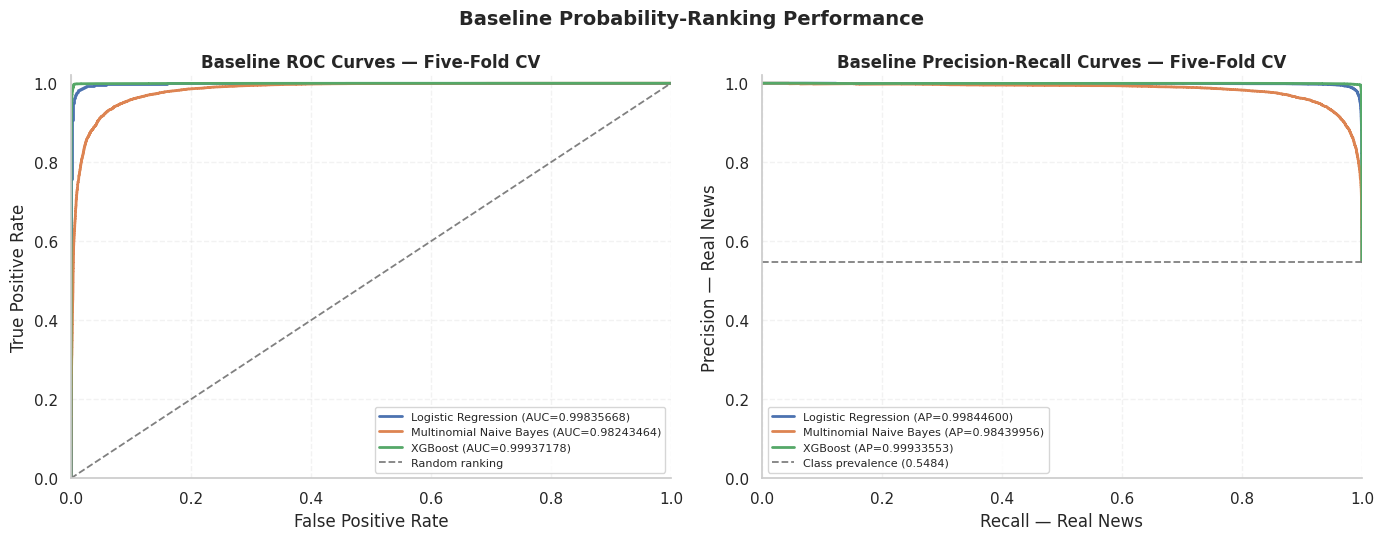

BASELINE ROC-AUC AND AVERAGE PRECISION
-----------------------------------------------------------------


,Model,ROC-AUC,Average Precision
0,Logistic Regression,0.99835668,0.99844600
1,Multinomial Naive Bayes,0.98243464,0.98439956
2,XGBoost,0.99937178,0.99933553



PRECISE MODEL SCORES

Logistic Regression
ROC-AUC: 0.99835668
Average Precision: 0.99844600

Multinomial Naive Bayes
ROC-AUC: 0.98243464
Average Precision: 0.98439956

XGBoost
ROC-AUC: 0.99937178
Average Precision: 0.99933553

EVALUATION SUMMARY
-----------------------------------------------------------------
Models evaluated: 3
Cross-validation folds: 5
Positive class: Real News (1)
Primary comparison metric remains: Macro F1
Held-out test articles used: 0

Near-perfect ROC-AUC scores require further investigation of generalisation and source bias.


In [ ]:
# Purpose:
# Compare the probability-ranking performance of the
# three baseline models using five-fold out-of-fold predictions.
#
# Class 0 = Fake News
# Class 1 = Real News (positive class)
#
# The held-out test set is not used in this analysis.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

# ------------------------------------------------------------
# 1. VALIDATE THE PREVIOUS EVALUATION RESULTS
# ------------------------------------------------------------

required_variables = [
    "baseline_oof_probabilities",
    "base_models",
    "y_train"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Run Cell 20 first. Missing: "
        + ", ".join(missing_variables)
    )

# Convert training labels into a NumPy array.
y_true = np.asarray(y_train)

# Verify the expected binary classes.
if set(np.unique(y_true)) != {0, 1}:
    raise ValueError(
        "Expected class labels: Fake = 0 and Real = 1."
    )

# Set Real News as the positive class.
positive_class = 1

# Calculate the proportion of positive articles.
real_prevalence = float(
    np.mean(y_true == positive_class)
)

# ------------------------------------------------------------
# 2. PREPARE THE FIGURE AND RESULTS STORAGE
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5.5)
)

ranking_records = []

# ------------------------------------------------------------
# 3. CALCULATE ROC-AUC AND AVERAGE PRECISION
# ------------------------------------------------------------

for model_name in base_models:

    if model_name not in baseline_oof_probabilities:
        raise ValueError(
            f"Missing out-of-fold probabilities: {model_name}"
        )

    # Retrieve the probability of Real News (class 1).
    probabilities = np.asarray(
        baseline_oof_probabilities[model_name],
        dtype=float
    )

    # Confirm that every training article has a probability.
    if probabilities.shape != (len(y_true),):
        raise ValueError(
            f"Incorrect probability shape for {model_name}."
        )

    # Check for invalid probability values.
    if not np.isfinite(probabilities).all():
        raise ValueError(
            f"Non-finite probabilities for {model_name}."
        )

    if not (
        (probabilities >= 0)
        & (probabilities <= 1)
    ).all():
        raise ValueError(
            f"Probabilities outside [0, 1] for {model_name}."
        )

    # --------------------------------------------------------
    # 4. ROC CURVE AND ROC-AUC
    # --------------------------------------------------------

    fpr, tpr, roc_thresholds = roc_curve(
        y_true,
        probabilities,
        pos_label=positive_class
    )

    model_roc_auc = roc_auc_score(
        y_true,
        probabilities
    )

    axes[0].plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{model_name} (AUC={model_roc_auc:.8f})"
    )

    # --------------------------------------------------------
    # 5. PRECISION-RECALL CURVE
    # --------------------------------------------------------

    precision_values, recall_values, pr_thresholds = (
        precision_recall_curve(
            y_true,
            probabilities,
            pos_label=positive_class
        )
    )

    model_ap = average_precision_score(
        y_true,
        probabilities,
        pos_label=positive_class
    )

    axes[1].plot(
        recall_values,
        precision_values,
        linewidth=2,
        label=f"{model_name} (AP={model_ap:.8f})"
    )

    # --------------------------------------------------------
    # 6. SAVE EXACT EVALUATION SCORES
    # --------------------------------------------------------

    ranking_records.append({
        "Model": model_name,
        "ROC-AUC": model_roc_auc,
        "Average Precision": model_ap
    })

# ------------------------------------------------------------
# 7. FORMAT THE ROC CURVE
# ------------------------------------------------------------

# A random-ranking classifier has ROC-AUC around 0.5.
axes[0].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="grey",
    linewidth=1.3,
    label="Random ranking"
)

axes[0].set_title(
    "Baseline ROC Curves — Five-Fold CV",
    fontsize=12,
    fontweight="bold"
)

axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")

axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1.02)

axes[0].legend(
    loc="lower right",
    fontsize=8
)

# ------------------------------------------------------------
# 8. FORMAT THE PRECISION-RECALL CURVE
# ------------------------------------------------------------

# The positive-class prevalence is the reference
# average precision of a constant-score classifier.
axes[1].axhline(
    y=real_prevalence,
    linestyle="--",
    color="grey",
    linewidth=1.3,
    label=f"Class prevalence ({real_prevalence:.4f})"
)

axes[1].set_title(
    "Baseline Precision-Recall Curves — Five-Fold CV",
    fontsize=12,
    fontweight="bold"
)

axes[1].set_xlabel("Recall — Real News")
axes[1].set_ylabel("Precision — Real News")

axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1.02)

axes[1].legend(
    loc="lower left",
    fontsize=8
)

# Improve visual readability.
for ax in axes:

    ax.grid(
        linestyle="--",
        alpha=0.25
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "Baseline Probability-Ranking Performance",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. DISPLAY PRECISE BASELINE SCORES
# ------------------------------------------------------------

baseline_ranking_summary = pd.DataFrame(
    ranking_records
)

print("BASELINE ROC-AUC AND AVERAGE PRECISION")
print("-" * 65)

display(
    baseline_ranking_summary.style.format({
        "ROC-AUC": "{:.8f}",
        "Average Precision": "{:.8f}"
    })
)

# Also print plain-text values for the final report.
print("\nPRECISE MODEL SCORES")

for row in ranking_records:

    print(f"\n{row['Model']}")

    print(
        f"ROC-AUC: {row['ROC-AUC']:.8f}"
    )

    print(
        f"Average Precision: "
        f"{row['Average Precision']:.8f}"
    )

# ------------------------------------------------------------
# 10. VALIDATE THE RESULTS
# ------------------------------------------------------------

# Verify that all three baseline models were evaluated.
assert len(baseline_ranking_summary) == len(base_models), (
    "Incomplete baseline probability evaluation."
)

# Verify that evaluation scores are valid.
score_columns = ["ROC-AUC", "Average Precision"]

score_values = baseline_ranking_summary[
    score_columns
]

assert (
    ((score_values >= 0) & (score_values <= 1))
    .all()
    .all()
), "Invalid probability-ranking scores detected."

# ------------------------------------------------------------
# 11. CONFIRM COMPLETION
# ------------------------------------------------------------

print("\nEVALUATION SUMMARY")
print("-" * 65)

print("Models evaluated:", len(base_models))
print("Cross-validation folds: 5")
print("Positive class: Real News (1)")
print("Primary comparison metric remains: Macro F1")
print("Held-out test articles used: 0")

print(
    "\nNear-perfect ROC-AUC scores require further "
    "investigation of generalisation and source bias."
)

**Cell 22**

In [ ]:
# Purpose:
# Optimise Logistic Regression, Naive Bayes and XGBoost.
# Compare baseline and tuned cross-validation performance.
# Record every parameter combination tested.
# Examine training-validation gaps for possible overfitting.
#
# Only the training dataset is used.
# The held-out test dataset remains untouched.

import pandas as pd

from IPython.display import display
from sklearn.model_selection import GridSearchCV

# ------------------------------------------------------------
# 1. VALIDATE REQUIRED VARIABLES
# ------------------------------------------------------------

required_variables = [
    "base_models",
    "baseline_summary",
    "X_train",
    "y_train",
    "cv",
    "scoring",
    "primary_metric"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Run Cells 17-19 before Cell 22. Missing: "
        + ", ".join(missing_variables)
    )

# Use the same five-fold cross-validation as the baseline.
tuning_cv = cv

# Use macro F1 as the primary optimisation metric.
assert primary_metric == "f1_macro", (
    "The primary tuning metric must be macro F1."
)

# ------------------------------------------------------------
# 2. DEFINE HYPERPARAMETER SEARCH GRIDS
# ------------------------------------------------------------

parameter_grids = {
    "Logistic Regression": {
        "model__C": [0.1, 1.0, 10.0]
    },

    "Multinomial Naive Bayes": {
        "model__alpha": [0.1, 0.5, 1.0, 2.0]
    },

    "XGBoost": {
        "model__n_estimators": [50, 100],
        "model__max_depth": [2, 3],
        "model__learning_rate": [0.1]
    }
}

# ------------------------------------------------------------
# 3. PREPARE STORAGE FOR TUNING RESULTS
# ------------------------------------------------------------

# Store the fitted GridSearchCV objects.
tuning_searches = {}

# Store the best fitted pipelines.
tuned_models = {}

# Store all tested configurations.
tuning_trial_records = []

# Store baseline-versus-tuned results.
tuning_summary_records = []

# ------------------------------------------------------------
# 4. RUN GRIDSEARCHCV FOR ALL THREE MODELS
# ------------------------------------------------------------

for model_name, pipeline in base_models.items():

    print("\n" + "=" * 65)
    print(f"HYPERPARAMETER TUNING: {model_name.upper()}")
    print("=" * 65)

    # Configure the search using the same folds
    # and evaluation metrics as the baseline models.
    search = GridSearchCV(
        estimator=pipeline,
        param_grid=parameter_grids[model_name],
        scoring=scoring,
        refit=primary_metric,
        cv=tuning_cv,
        return_train_score=True,
        n_jobs=1,
        error_score="raise"
    )

    # Fit the complete pipeline using training data only.
    search.fit(X_train, y_train)

    # Preserve the fitted search and selected pipeline.
    tuning_searches[model_name] = search
    tuned_models[model_name] = search.best_estimator_

    # Retrieve the complete search results.
    cv_results = pd.DataFrame(search.cv_results_)

    # --------------------------------------------------------
    # 5. RECORD EVERY HYPERPARAMETER COMBINATION
    # --------------------------------------------------------

    for _, row in cv_results.iterrows():

        tuning_trial_records.append({
            "Model": model_name,
            "Parameters": str(row["params"]),
            "Training Macro F1": row["mean_train_f1_macro"],
            "CV Macro F1": row["mean_test_f1_macro"],
            "CV F1 Std": row["std_test_f1_macro"],
            "CV Accuracy": row["mean_test_accuracy"],
            "CV ROC-AUC": row["mean_test_roc_auc"],
            "F1 Rank": int(row["rank_test_f1_macro"])
        })

    # --------------------------------------------------------
    # 6. COMPARE BASELINE AND BEST TUNED CV PERFORMANCE
    # --------------------------------------------------------

    # Retrieve baseline performance from Cell 19.
    baseline_row = baseline_summary.loc[
        baseline_summary["Model"] == model_name
    ]

    if len(baseline_row) != 1:
        raise ValueError(
            f"Baseline result missing or duplicated: {model_name}"
        )

    baseline_f1 = float(
        baseline_row["CV Macro F1"].iloc[0]
    )

    # Retrieve the selected parameter combination.
    best_index = search.best_index_

    tuned_f1 = float(search.best_score_)

    tuned_train_f1 = float(
        cv_results.loc[
            best_index,
            "mean_train_f1_macro"
        ]
    )

    tuned_auc = float(
        cv_results.loc[
            best_index,
            "mean_test_roc_auc"
        ]
    )

    # Compare validation scores on the same folds.
    f1_change = tuned_f1 - baseline_f1

    # Measure the training-validation gap.
    # A substantial positive gap may indicate overfitting.
    train_cv_gap = tuned_train_f1 - tuned_f1

    tuning_summary_records.append({
        "Model": model_name,
        "Baseline CV Macro F1": baseline_f1,
        "Tuned CV Macro F1": tuned_f1,
        "F1 Change": f1_change,
        "Tuned Training Macro F1": tuned_train_f1,
        "Train-CV F1 Gap": train_cv_gap,
        "Tuned CV ROC-AUC": tuned_auc,
        "Best Parameters": str(search.best_params_)
    })

    # Display the best configuration for this model.
    print("\nBest parameters:", search.best_params_)

    print(
        f"Baseline CV Macro F1: {baseline_f1:.6f}"
    )

    print(
        f"Tuned CV Macro F1: {tuned_f1:.6f}"
    )

    print(
        f"CV Macro F1 change: {f1_change:+.6f}"
    )

    print(
        f"Training-validation F1 gap: "
        f"{train_cv_gap:.6f}"
    )

# ------------------------------------------------------------
# 7. CREATE COMPLETE TUNING RESULTS TABLE
# ------------------------------------------------------------

tuning_trials = (
    pd.DataFrame(tuning_trial_records)
    .sort_values(
        by=["Model", "F1 Rank"]
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 65)
print("ALL HYPERPARAMETER COMBINATIONS TESTED")
print("=" * 65)

display(tuning_trials.round(6))

# ------------------------------------------------------------
# 8. CREATE BASELINE-VERSUS-TUNED SUMMARY
# ------------------------------------------------------------

tuning_summary = (
    pd.DataFrame(tuning_summary_records)
    .sort_values(
        by="Tuned CV Macro F1",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 65)
print("BASELINE VERSUS TUNED CROSS-VALIDATION")
print("=" * 65)

display(tuning_summary.round(6))

# ------------------------------------------------------------
# 9. SAVE CONVENIENT NAMES FOR THE TUNED MODELS
# ------------------------------------------------------------

lr_search = tuning_searches["Logistic Regression"]
nb_search = tuning_searches["Multinomial Naive Bayes"]
xgb_search = tuning_searches["XGBoost"]

lr_tuned = tuned_models["Logistic Regression"]
nb_tuned = tuned_models["Multinomial Naive Bayes"]
xgb_tuned = tuned_models["XGBoost"]

# ------------------------------------------------------------
# 10. VALIDATE TUNING RESULTS
# ------------------------------------------------------------

# Confirm all three models were tuned.
assert len(tuning_searches) == 3, (
    "All three models must be tuned."
)

# Confirm every expected parameter combination was evaluated.
assert len(tuning_trials) == 11, (
    "The expected 11 parameter combinations were not evaluated."
)

# Confirm that every best estimator was refitted.
for model_name, search in tuning_searches.items():

    assert hasattr(search, "best_estimator_"), (
        f"Missing best estimator for {model_name}."
    )

# Confirm that the recorded scores are valid.
assert tuning_trials["CV Macro F1"].between(0, 1).all(), (
    "Invalid tuning F1-scores detected."
)

assert tuning_trials["CV ROC-AUC"].between(0, 1).all(), (
    "Invalid tuning ROC-AUC scores detected."
)

print("\nHYPERPARAMETER TUNING COMPLETED")
print("-" * 65)

print("Models tuned:", len(tuning_searches))
print("Parameter combinations:", len(tuning_trials))
print("Cross-validation folds:", tuning_cv.n_splits)
print("Primary selection metric:", primary_metric)

print("\nAll tuning trials have been recorded.")
print("Best fitted pipelines are available.")
print("Held-out test articles used: 0")



HYPERPARAMETER TUNING: LOGISTIC REGRESSION

Best parameters: {'model__C': 10.0}
Baseline CV Macro F1: 0.984309
Tuned CV Macro F1: 0.990525
CV Macro F1 change: +0.006215
Training-validation F1 gap: 0.007148

HYPERPARAMETER TUNING: MULTINOMIAL NAIVE BAYES

Best parameters: {'model__alpha': 0.1}
Baseline CV Macro F1: 0.934206
Tuned CV Macro F1: 0.934470
CV Macro F1 change: +0.000264
Training-validation F1 gap: 0.001806

HYPERPARAMETER TUNING: XGBOOST

Best parameters: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 100}
Baseline CV Macro F1: 0.995654
Tuned CV Macro F1: 0.996276
CV Macro F1 change: +0.000621
Training-validation F1 gap: 0.002009

ALL HYPERPARAMETER COMBINATIONS TESTED


,Model,Parameters,Training Macro F1,CV Macro F1,CV F1 Std,CV Accuracy,CV ROC-AUC,F1 Rank
0,Logistic Regression,{'model__C': 10.0},0.997673,0.990525,0.000941,0.990618,0.999188,1
1,Logistic Regression,{'model__C': 1.0},0.988341,0.984309,0.001267,0.984471,0.998364,2
2,Logistic Regression,{'model__C': 0.1},0.968423,0.966797,0.002027,0.967194,0.995199,3
3,Multinomial Naive Bayes,{'model__alpha': 0.1},0.936276,0.934470,0.004382,0.935100,0.982890,1
4,Multinomial Naive Bayes,{'model__alpha': 0.5},0.935752,0.934434,0.004195,0.935067,0.982610,2
5,Multinomial Naive Bayes,{'model__alpha': 1.0},0.935540,0.934206,0.004302,0.934841,0.982466,3
6,Multinomial Naive Bayes,{'model__alpha': 2.0},0.935059,0.933784,0.004332,0.934420,0.982311,4
7,XGBoost,"{'model__learning_rate': 0.1, 'model__max_dept...",0.998285,0.996276,0.001105,0.996312,0.999693,1
8,XGBoost,"{'model__learning_rate': 0.1, 'model__max_dept...",0.996513,0.995785,0.000966,0.995826,0.999584,2
9,XGBoost,"{'model__learning_rate': 0.1, 'model__max_dept...",0.996431,0.995654,0.000874,0.995697,0.999449,3



BASELINE VERSUS TUNED CROSS-VALIDATION


,Model,Baseline CV Macro F1,Tuned CV Macro F1,F1 Change,Tuned Training Macro F1,Train-CV F1 Gap,Tuned CV ROC-AUC,Best Parameters
0,XGBoost,0.995654,0.996276,0.000621,0.998285,0.002009,0.999693,"{'model__learning_rate': 0.1, 'model__max_dept..."
1,Logistic Regression,0.984309,0.990525,0.006215,0.997673,0.007148,0.999188,{'model__C': 10.0}
2,Multinomial Naive Bayes,0.934206,0.934470,0.000264,0.936276,0.001806,0.982890,{'model__alpha': 0.1}



HYPERPARAMETER TUNING COMPLETED
-----------------------------------------------------------------
Models tuned: 3
Parameter combinations: 11
Cross-validation folds: 5
Primary selection metric: f1_macro

All tuning trials have been recorded.
Best fitted pipelines are available.
Held-out test articles used: 0


**Cell 23**

MODEL SELECTION FROM TRAINING CROSS-VALIDATION
-----------------------------------------------------------------
CV-selected model: XGBoost
Selection metric: Tuned CV Macro F1

TEST EVALUATION: LOGISTIC REGRESSION

Configuration: Baseline
Accuracy: 0.984213
Macro F1: 0.984043
ROC-AUC: 0.99839371
Total errors: 122

CLASSIFICATION REPORT
              precision    recall  f1-score   support

        Fake     0.9895    0.9754    0.9824      3490
        Real     0.9799    0.9915    0.9857      4238

    accuracy                         0.9842      7728
   macro avg     0.9847    0.9834    0.9840      7728
weighted avg     0.9843    0.9842    0.9842      7728


Configuration: Tuned
Accuracy: 0.991589
Macro F1: 0.991503
ROC-AUC: 0.99932843
Total errors: 65

CLASSIFICATION REPORT
              precision    recall  f1-score   support

        Fake     0.9951    0.9862    0.9906      3490
        Real     0.9888    0.9960    0.9924      4238

    accuracy                         0.9916      77

,Model,Configuration,Accuracy,Macro Precision,Macro Recall,Macro F1,ROC-AUC,Average Precision,Fake Predicted Real,Real Predicted Fake,Total Errors
0,Logistic Regression,Baseline,0.984213,0.984739,0.983432,0.984043,0.998394,0.998668,86,36,122
1,Logistic Regression,Tuned,0.991589,0.991921,0.991118,0.991503,0.999328,0.999419,48,17,65
2,Multinomial Naive Bayes,Baseline,0.929089,0.928827,0.927913,0.928344,0.980056,0.982571,294,254,548
3,Multinomial Naive Bayes,Tuned,0.929348,0.928999,0.928275,0.928621,0.980487,0.982938,289,257,546
4,XGBoost,Baseline,0.997024,0.997164,0.996831,0.996995,0.999696,0.999774,18,5,23
5,XGBoost,Tuned,0.997283,0.997399,0.997118,0.997256,0.999897,0.999914,16,5,21



HYPERPARAMETER TUNING: ACTUAL TEST PERFORMANCE CHANGES


,Model,Baseline Macro F1,Tuned Macro F1,Macro F1 Change,Baseline ROC-AUC,Tuned ROC-AUC,ROC-AUC Change,Baseline Errors,Tuned Errors,Error Reduction
0,Logistic Regression,0.984043,0.991503,0.007460,0.998394,0.999328,0.000935,122,65,57
1,Multinomial Naive Bayes,0.928344,0.928621,0.000277,0.980056,0.980487,0.000432,548,546,2
2,XGBoost,0.996995,0.997256,0.000261,0.999696,0.999897,0.000200,23,21,2


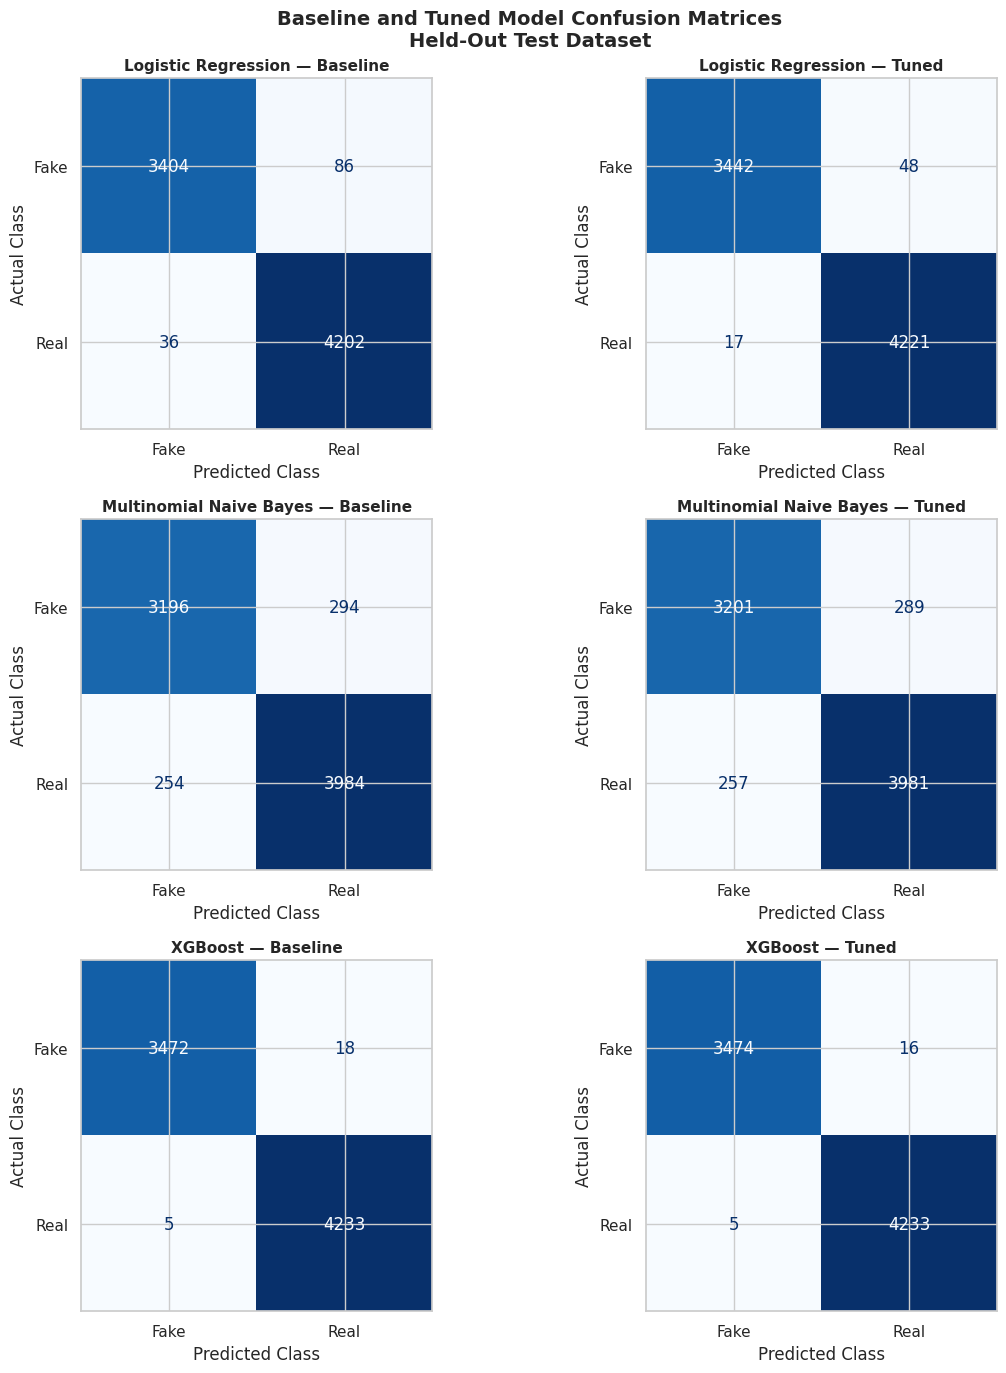


FINAL MODEL-SELECTION EVIDENCE
Model selected using cross-validation: XGBoost

TEST RESULTS FOR THE CV-SELECTED MODEL


,Model,Configuration,Accuracy,Macro Precision,Macro Recall,Macro F1,ROC-AUC,Average Precision,Fake Predicted Real,Real Predicted Fake,Total Errors
5,XGBoost,Tuned,0.997283,0.997399,0.997118,0.997256,0.999897,0.999914,16,5,21



The model was selected using cross-validation rather than its test score.

FINAL TEST EVALUATION COMPLETED
-----------------------------------------------------------------
Models evaluated: 3
Configurations per model: 2
Total model evaluations: 6
Test articles: 7728

Baseline and tuned results compared.
Hyperparameter effects calculated.
Classification errors examined.
Final test confusion matrices generated.


In [ ]:
# Purpose:
# Compare baseline and tuned models on the same held-out
# test dataset using identical evaluation metrics.
#
# Fake News = 0
# Real News = 1
#
# The test dataset is used only for final evaluation.
# Hyperparameter tuning was completed in Cell 22.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ------------------------------------------------------------
# 1. VERIFY THE REQUIRED VARIABLES
# ------------------------------------------------------------

required_variables = [
    "base_models",
    "tuned_models",
    "tuning_summary",
    "X_train",
    "X_test",
    "y_train",
    "y_test"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Run the previous notebook cells first. Missing: "
        + ", ".join(missing_variables)
    )

# Check that all three baseline models have tuned equivalents
if set(base_models) != set(tuned_models):
    raise ValueError(
        "Baseline and tuned model names do not match."
    )

# Validate the training and testing datasets
if len(X_train) != len(y_train):
    raise ValueError("Training data and labels do not match.")

if len(X_test) != len(y_test):
    raise ValueError("Testing data and labels do not match.")

if set(np.unique(y_test)) != {0, 1}:
    raise ValueError(
        "Test labels must contain Fake (0) and Real (1)."
    )

# ------------------------------------------------------------
# 2. IDENTIFY THE MODEL SELECTED BY CROSS-VALIDATION
# ------------------------------------------------------------

# Select the model using the tuning CV results from Cell 22.
# This selection is made BEFORE examining test scores.

cv_selected_model = (
    tuning_summary
    .sort_values(
        "Tuned CV Macro F1",
        ascending=False
    )
    .iloc[0]["Model"]
)

print("MODEL SELECTION FROM TRAINING CROSS-VALIDATION")
print("-" * 65)

print("CV-selected model:", cv_selected_model)
print("Selection metric: Tuned CV Macro F1")

# ------------------------------------------------------------
# 3. PREPARE STORAGE FOR FINAL TEST RESULTS
# ------------------------------------------------------------

test_result_records = []

# Save trained models and predictions for later analysis
baseline_fitted_models = {}
test_predictions = {}
test_probabilities = {}
test_confusion_matrices = {}

# ------------------------------------------------------------
# 4. EVALUATE BASELINE AND TUNED MODELS
# ------------------------------------------------------------

for model_name in base_models:

    print("\n" + "=" * 65)
    print(f"TEST EVALUATION: {model_name.upper()}")
    print("=" * 65)

    # Create and train an independent baseline model.
    # This model uses the original baseline hyperparameters.
    baseline_model = clone(base_models[model_name])

    baseline_model.fit(
        X_train,
        y_train
    )

    baseline_fitted_models[model_name] = baseline_model

    # Retrieve the tuned pipeline fitted by GridSearchCV.
    # Cell 22 already refitted it on the entire training set.
    tuned_model = tuned_models[model_name]

    # Evaluate both configurations on identical test articles.
    configurations = {
        "Baseline": baseline_model,
        "Tuned": tuned_model
    }

    for configuration_name, model in configurations.items():

        print(f"\nConfiguration: {configuration_name}")

        # Generate predictions for the held-out test data
        predictions = model.predict(X_test)

        # Obtain predicted probabilities
        probabilities = model.predict_proba(X_test)

        # Find the column associated with Real News (class 1)
        class_positions = np.flatnonzero(
            np.asarray(model.classes_) == 1
        )

        if len(class_positions) != 1:
            raise ValueError(
                f"Class 1 missing from {model_name}."
            )

        real_class_index = int(class_positions[0])

        real_probabilities = probabilities[
            :, real_class_index
        ]

        # Check probability validity
        if not np.isfinite(real_probabilities).all():
            raise ValueError(
                f"Invalid probabilities for {model_name}."
            )

        # ----------------------------------------------------
        # 5. CALCULATE CLASSIFICATION METRICS
        # ----------------------------------------------------

        accuracy = accuracy_score(
            y_test,
            predictions
        )

        precision = precision_score(
            y_test,
            predictions,
            average="macro",
            zero_division=0
        )

        recall = recall_score(
            y_test,
            predictions,
            average="macro",
            zero_division=0
        )

        macro_f1 = f1_score(
            y_test,
            predictions,
            average="macro",
            zero_division=0
        )

        roc_auc = roc_auc_score(
            y_test,
            real_probabilities
        )

        average_precision = average_precision_score(
            y_test,
            real_probabilities
        )

        # ----------------------------------------------------
        # 6. CALCULATE CONFUSION MATRIX
        # ----------------------------------------------------

        cm = confusion_matrix(
            y_test,
            predictions,
            labels=[0, 1]
        )

        fake_as_real = int(cm[0, 1])
        real_as_fake = int(cm[1, 0])

        total_errors = fake_as_real + real_as_fake

        # Store predictions for subsequent interpretation
        result_key = (model_name, configuration_name)

        test_predictions[result_key] = predictions

        test_probabilities[result_key] = real_probabilities

        test_confusion_matrices[result_key] = cm

        # ----------------------------------------------------
        # 7. RECORD THE FINAL TEST RESULTS
        # ----------------------------------------------------

        test_result_records.append({
            "Model": model_name,
            "Configuration": configuration_name,
            "Accuracy": accuracy,
            "Macro Precision": precision,
            "Macro Recall": recall,
            "Macro F1": macro_f1,
            "ROC-AUC": roc_auc,
            "Average Precision": average_precision,
            "Fake Predicted Real": fake_as_real,
            "Real Predicted Fake": real_as_fake,
            "Total Errors": total_errors
        })

        print(
            f"Accuracy: {accuracy:.6f}"
        )

        print(
            f"Macro F1: {macro_f1:.6f}"
        )

        print(
            f"ROC-AUC: {roc_auc:.8f}"
        )

        print(
            f"Total errors: {total_errors}"
        )

        # Display the complete classification report
        print("\nCLASSIFICATION REPORT")

        print(
            classification_report(
                y_test,
                predictions,
                labels=[0, 1],
                target_names=["Fake", "Real"],
                digits=4,
                zero_division=0
            )
        )

# ------------------------------------------------------------
# 8. CREATE THE FINAL TEST COMPARISON TABLE
# ------------------------------------------------------------

test_comparison = pd.DataFrame(
    test_result_records
)

print("\n" + "=" * 65)
print("FINAL TEST PERFORMANCE: BASELINE VS TUNED")
print("=" * 65)

display(
    test_comparison.round(8)
)

# ------------------------------------------------------------
# 9. CALCULATE THE EFFECT OF HYPERPARAMETER TUNING
# ------------------------------------------------------------

# Compare baseline and tuned results using the SAME test set.
comparison_rows = []

for model_name in base_models:

    baseline_row = test_comparison.loc[
        (test_comparison["Model"] == model_name)
        & (test_comparison["Configuration"] == "Baseline")
    ].iloc[0]

    tuned_row = test_comparison.loc[
        (test_comparison["Model"] == model_name)
        & (test_comparison["Configuration"] == "Tuned")
    ].iloc[0]

    comparison_rows.append({
        "Model": model_name,

        "Baseline Macro F1":
            baseline_row["Macro F1"],

        "Tuned Macro F1":
            tuned_row["Macro F1"],

        "Macro F1 Change":
            tuned_row["Macro F1"]
            - baseline_row["Macro F1"],

        "Baseline ROC-AUC":
            baseline_row["ROC-AUC"],

        "Tuned ROC-AUC":
            tuned_row["ROC-AUC"],

        "ROC-AUC Change":
            tuned_row["ROC-AUC"]
            - baseline_row["ROC-AUC"],

        "Baseline Errors":
            int(baseline_row["Total Errors"]),

        "Tuned Errors":
            int(tuned_row["Total Errors"]),

        "Error Reduction":
            int(
                baseline_row["Total Errors"]
                - tuned_row["Total Errors"]
            )
    })

tuning_test_comparison = pd.DataFrame(
    comparison_rows
)

print("\n" + "=" * 65)
print("HYPERPARAMETER TUNING: ACTUAL TEST PERFORMANCE CHANGES")
print("=" * 65)

display(
    tuning_test_comparison.round(8)
)

# ------------------------------------------------------------
# 10. VISUALISE THE SIX CONFUSION MATRICES
# ------------------------------------------------------------

model_names = list(base_models.keys())
configuration_names = ["Baseline", "Tuned"]

fig, axes = plt.subplots(
    3,
    2,
    figsize=(12, 14)
)

for row_index, model_name in enumerate(model_names):

    for col_index, configuration_name in enumerate(
        configuration_names
    ):

        cm = test_confusion_matrices[
            (model_name, configuration_name)
        ]

        ax = axes[row_index, col_index]

        ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=["Fake", "Real"]
        ).plot(
            ax=ax,
            cmap="Blues",
            colorbar=False,
            values_format="d"
        )

        ax.set_title(
            f"{model_name} — {configuration_name}",
            fontsize=11,
            fontweight="bold"
        )

        ax.set_xlabel("Predicted Class")
        ax.set_ylabel("Actual Class")

fig.suptitle(
    "Baseline and Tuned Model Confusion Matrices\n"
    "Held-Out Test Dataset",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 11. DISPLAY MODEL-SELECTION EVIDENCE
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("FINAL MODEL-SELECTION EVIDENCE")
print("=" * 65)

print(
    "Model selected using cross-validation:",
    cv_selected_model
)

selected_test_result = test_comparison.loc[
    (test_comparison["Model"] == cv_selected_model)
    & (test_comparison["Configuration"] == "Tuned")
]

print("\nTEST RESULTS FOR THE CV-SELECTED MODEL")

display(
    selected_test_result.round(8)
)

print(
    "\nThe model was selected using cross-validation "
    "rather than its test score."
)

# ------------------------------------------------------------
# 12. VALIDATE THE FINAL TEST EVALUATION
# ------------------------------------------------------------

# Three models with two configurations each
assert len(test_comparison) == 6, (
    "Expected six test evaluations."
)

# Every confusion matrix must cover the entire test dataset
for model_key, cm in test_confusion_matrices.items():

    assert cm.sum() == len(y_test), (
        f"Incorrect test count for {model_key}."
    )

# All scores must be between 0 and 1
metric_columns = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "ROC-AUC",
    "Average Precision"
]

metric_values = test_comparison[metric_columns]

assert (
    ((metric_values >= 0) & (metric_values <= 1))
    .all()
    .all()
), "Invalid test evaluation scores."

print("\nFINAL TEST EVALUATION COMPLETED")
print("-" * 65)

print("Models evaluated: 3")
print("Configurations per model: 2")
print("Total model evaluations: 6")
print("Test articles:", len(X_test))

print("\nBaseline and tuned results compared.")
print("Hyperparameter effects calculated.")
print("Classification errors examined.")
print("Final test confusion matrices generated.")

**Cell 24**

UNDERFITTING AND OVERFITTING DIAGNOSTICS
---------------------------------------------------------------------------


,Model,Configuration,Train Macro F1,CV Macro F1,F1 Gap,Train ROC-AUC,CV ROC-AUC,ROC-AUC Gap,CV F1 Std,Selected Parameters
0,Logistic Regression,Baseline,0.988341,0.984309,0.004031,0.998975,0.998364,0.000611,0.001416,Original baseline
1,Logistic Regression,Tuned,0.997673,0.990525,0.007148,0.999900,0.999188,0.000712,0.001052,{'model__C': 10.0}
2,Multinomial Naive Bayes,Baseline,0.935540,0.934206,0.001333,0.983218,0.982466,0.000752,0.004810,Original baseline
3,Multinomial Naive Bayes,Tuned,0.936276,0.934470,0.001806,0.983668,0.982890,0.000779,0.004899,{'model__alpha': 0.1}
4,XGBoost,Baseline,0.996431,0.995654,0.000776,0.999823,0.999449,0.000374,0.000977,Original baseline
5,XGBoost,Tuned,0.998285,0.996276,0.002009,0.999990,0.999693,0.000296,0.001235,"{'model__learning_rate': 0.1, 'model__max_dept..."


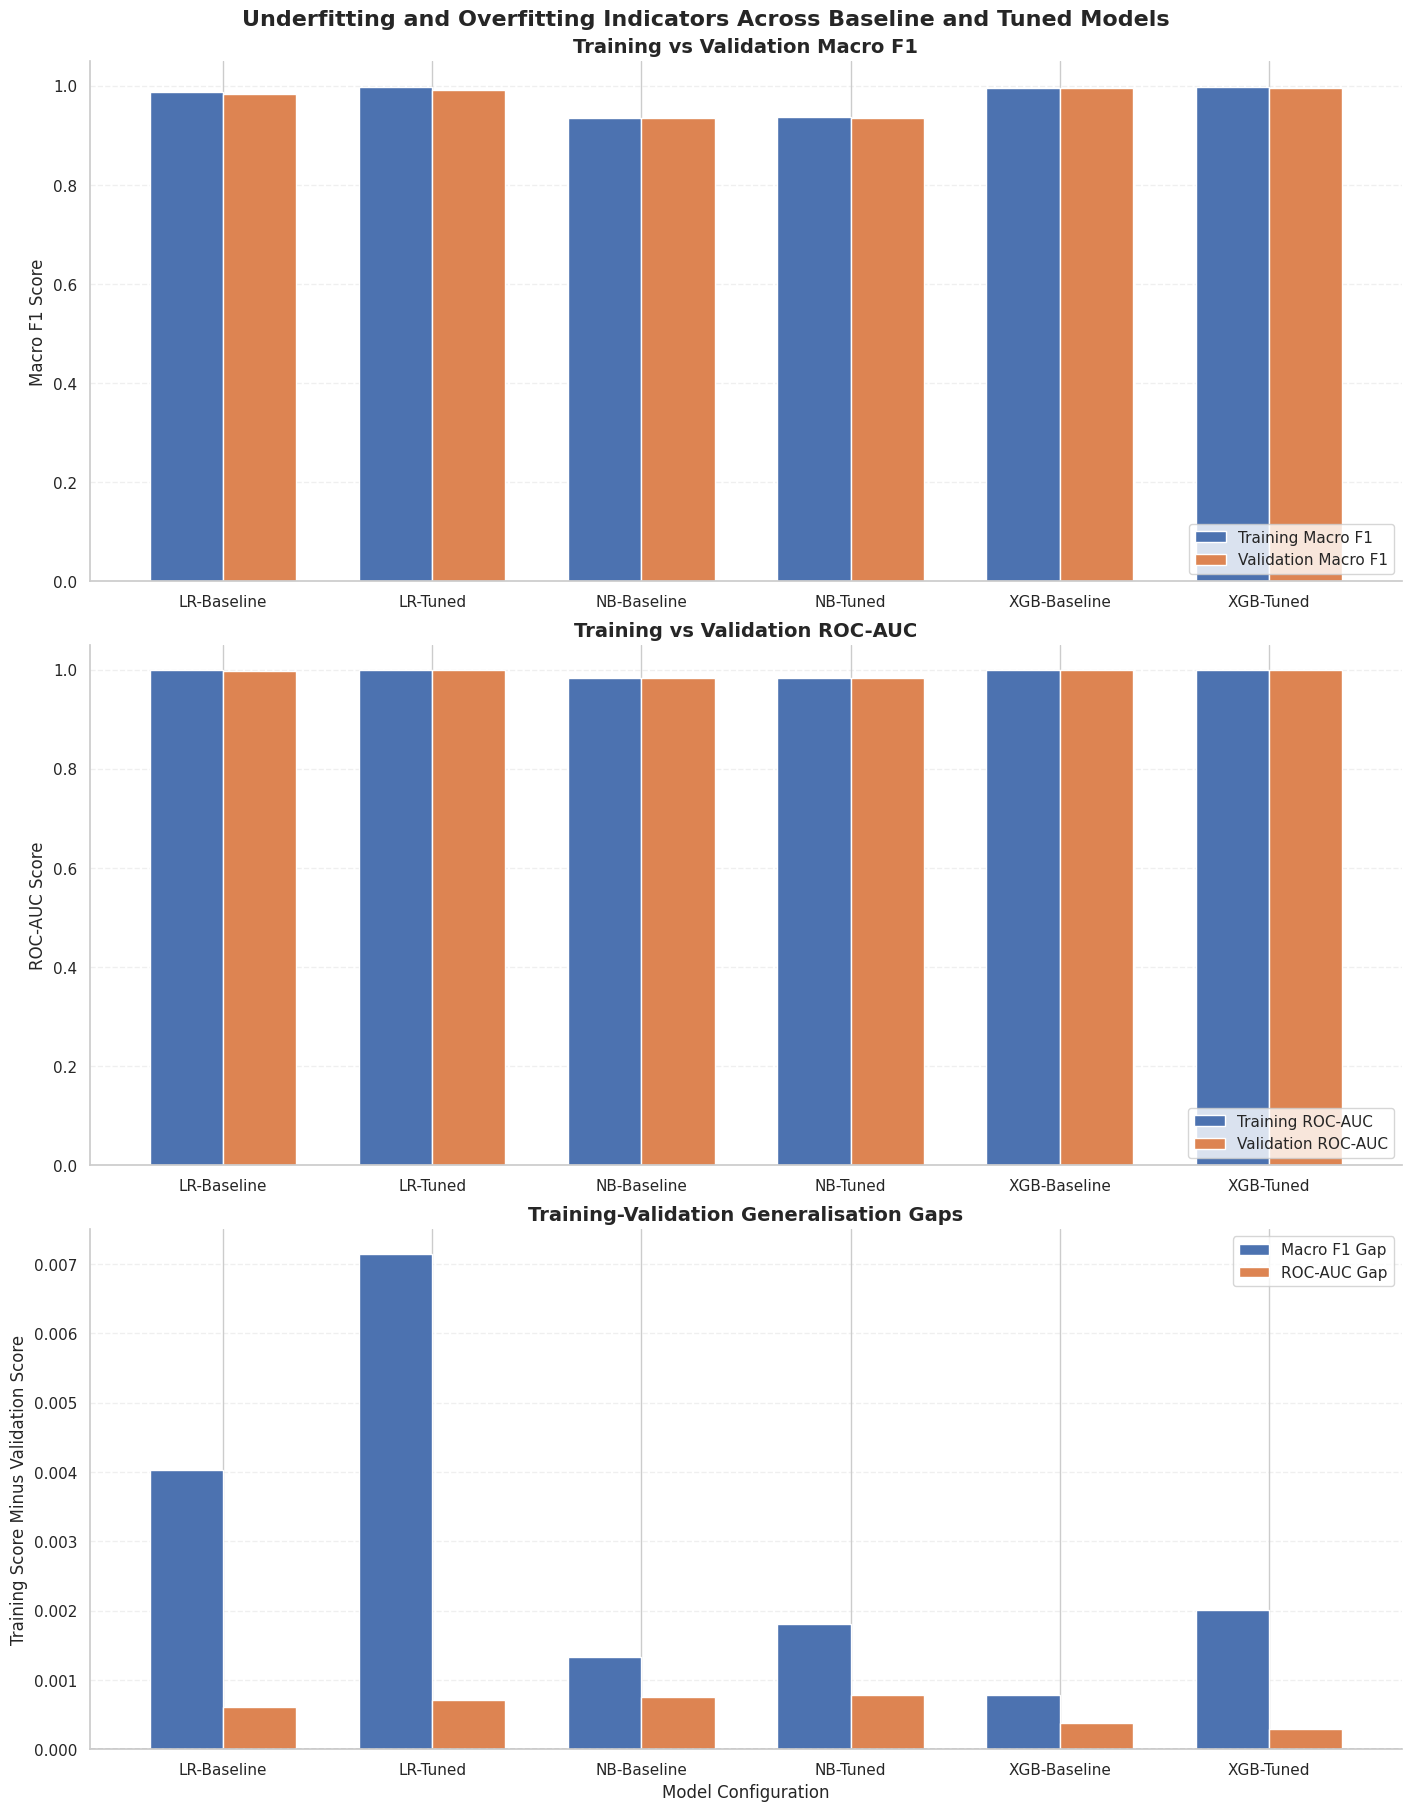


INTERPRETATION
---------------------------------------------------------------------------
Possible underfitting: both training and validation scores are relatively low.
Possible overfitting: training scores are higher than validation scores.
Small gaps indicate similar performance across training and validation folds.
High validation scores do not guarantee generalisation to unfamiliar publishers.


In [ ]:
# ============================================================
# CELL 24: CLEAN UNDERFITTING AND OVERFITTING DIAGNOSTICS
# Fake News Detection Using Machine Learning
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# ------------------------------------------------------------
# 1. VERIFY REQUIRED RESULTS
# ------------------------------------------------------------

required_variables = [
    "base_models",
    "baseline_cv_results",
    "tuning_searches",
    "cv"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Run Cells 19 and 22 first. Missing: "
        + ", ".join(missing_variables)
    )

if (
    set(base_models) != set(baseline_cv_results)
    or set(base_models) != set(tuning_searches)
):
    raise ValueError(
        "Model names do not match across evaluation results."
    )

# ------------------------------------------------------------
# 2. COLLECT BASELINE AND TUNED SCORES
# ------------------------------------------------------------

diagnostic_records = []

for model_name in base_models:

    # Baseline results from Cell 19
    baseline = baseline_cv_results[model_name]

    diagnostic_records.append({
        "Model": model_name,
        "Configuration": "Baseline",
        "Train Macro F1": float(np.mean(baseline["train_f1_macro"])),
        "CV Macro F1": float(np.mean(baseline["test_f1_macro"])),
        "Train ROC-AUC": float(np.mean(baseline["train_roc_auc"])),
        "CV ROC-AUC": float(np.mean(baseline["test_roc_auc"])),
        "CV F1 Std": float(np.std(baseline["test_f1_macro"], ddof=1)),
        "Selected Parameters": "Original baseline"
    })

    # Tuned results from Cell 22
    search = tuning_searches[model_name]
    best_index = int(search.best_index_)
    results = search.cv_results_

    tuned_fold_f1 = [
        float(results[f"split{i}_test_f1_macro"][best_index])
        for i in range(cv.n_splits)
    ]

    diagnostic_records.append({
        "Model": model_name,
        "Configuration": "Tuned",
        "Train Macro F1": float(results["mean_train_f1_macro"][best_index]),
        "CV Macro F1": float(results["mean_test_f1_macro"][best_index]),
        "Train ROC-AUC": float(results["mean_train_roc_auc"][best_index]),
        "CV ROC-AUC": float(results["mean_test_roc_auc"][best_index]),
        "CV F1 Std": float(np.std(tuned_fold_f1, ddof=1)),
        "Selected Parameters": str(search.best_params_)
    })

# ------------------------------------------------------------
# 3. CALCULATE GENERALISATION GAPS
# ------------------------------------------------------------

diagnostic_summary = pd.DataFrame(diagnostic_records)

diagnostic_summary["F1 Gap"] = (
    diagnostic_summary["Train Macro F1"]
    - diagnostic_summary["CV Macro F1"]
)

diagnostic_summary["ROC-AUC Gap"] = (
    diagnostic_summary["Train ROC-AUC"]
    - diagnostic_summary["CV ROC-AUC"]
)

# Short labels for cleaner charts
short_names = {
    "Logistic Regression": "LR",
    "Multinomial Naive Bayes": "NB",
    "XGBoost": "XGB"
}

diagnostic_summary["Short Label"] = diagnostic_summary.apply(
    lambda row: f"{short_names[row['Model']]}-{row['Configuration']}",
    axis=1
)

# Keep neat column order
diagnostic_display = diagnostic_summary[
    [
        "Model",
        "Configuration",
        "Train Macro F1",
        "CV Macro F1",
        "F1 Gap",
        "Train ROC-AUC",
        "CV ROC-AUC",
        "ROC-AUC Gap",
        "CV F1 Std",
        "Selected Parameters"
    ]
].copy()

print("UNDERFITTING AND OVERFITTING DIAGNOSTICS")
print("-" * 75)
display(diagnostic_display.round(6))

# ------------------------------------------------------------
# 4. PREPARE CHART DATA
# ------------------------------------------------------------

x_labels = diagnostic_summary["Short Label"].tolist()
x = np.arange(len(x_labels))
bar_width = 0.35

# ------------------------------------------------------------
# 5. CREATE CLEAN VERTICAL FIGURES
# ------------------------------------------------------------

fig, axes = plt.subplots(
    3, 1,
    figsize=(14, 18),
    constrained_layout=True
)

# -------------------------
# Plot 1: Macro F1
# -------------------------
axes[0].bar(
    x - bar_width / 2,
    diagnostic_summary["Train Macro F1"],
    width=bar_width,
    label="Training Macro F1"
)

axes[0].bar(
    x + bar_width / 2,
    diagnostic_summary["CV Macro F1"],
    width=bar_width,
    label="Validation Macro F1"
)

axes[0].set_title(
    "Training vs Validation Macro F1",
    fontsize=14,
    fontweight="bold"
)
axes[0].set_ylabel("Macro F1 Score")
axes[0].set_ylim(0, 1.05)
axes[0].set_xticks(x)
axes[0].set_xticklabels(x_labels, rotation=0)
axes[0].legend(loc="lower right")
axes[0].grid(axis="y", linestyle="--", alpha=0.3)

# -------------------------
# Plot 2: ROC-AUC
# -------------------------
axes[1].bar(
    x - bar_width / 2,
    diagnostic_summary["Train ROC-AUC"],
    width=bar_width,
    label="Training ROC-AUC"
)

axes[1].bar(
    x + bar_width / 2,
    diagnostic_summary["CV ROC-AUC"],
    width=bar_width,
    label="Validation ROC-AUC"
)

axes[1].set_title(
    "Training vs Validation ROC-AUC",
    fontsize=14,
    fontweight="bold"
)
axes[1].set_ylabel("ROC-AUC Score")
axes[1].set_ylim(0, 1.05)
axes[1].set_xticks(x)
axes[1].set_xticklabels(x_labels, rotation=0)
axes[1].legend(loc="lower right")
axes[1].grid(axis="y", linestyle="--", alpha=0.3)

# -------------------------
# Plot 3: Generalisation Gaps
# -------------------------
axes[2].bar(
    x - bar_width / 2,
    diagnostic_summary["F1 Gap"],
    width=bar_width,
    label="Macro F1 Gap"
)

axes[2].bar(
    x + bar_width / 2,
    diagnostic_summary["ROC-AUC Gap"],
    width=bar_width,
    label="ROC-AUC Gap"
)

axes[2].axhline(0, color="black", linestyle="--", linewidth=1)

axes[2].set_title(
    "Training-Validation Generalisation Gaps",
    fontsize=14,
    fontweight="bold"
)
axes[2].set_ylabel("Training Score Minus Validation Score")
axes[2].set_xlabel("Model Configuration")
axes[2].set_xticks(x)
axes[2].set_xticklabels(x_labels, rotation=0)
axes[2].legend(loc="upper right")
axes[2].grid(axis="y", linestyle="--", alpha=0.3)

# Remove unnecessary borders
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_axisbelow(True)

fig.suptitle(
    "Underfitting and Overfitting Indicators Across Baseline and Tuned Models",
    fontsize=16,
    fontweight="bold"
)

plt.show()

# ------------------------------------------------------------
# 6. INTERPRETATION OUTPUT
# ------------------------------------------------------------

print("\nINTERPRETATION")
print("-" * 75)
print("Possible underfitting: both training and validation scores are relatively low.")
print("Possible overfitting: training scores are higher than validation scores.")
print("Small gaps indicate similar performance across training and validation folds.")
print("High validation scores do not guarantee generalisation to unfamiliar publishers.")


**Cell 25**

REUTERS SOURCE-MARKER ANALYSIS
-----------------------------------------------------------------
Test articles: 7728
Articles mentioning Reuters: 4266
Reuters mention rate: 55.20%

REUTERS PREVALENCE BY NEWS CLASS
-----------------------------------------------------------------


Reuters Marker,Mentioned,Not mentioned,Total,Mention Rate (%)
Actual Class,,,,
Fake,33,3457,3490,0.9456
Real,4233,5,4238,99.8820



REUTERS-ONLY DIAGNOSTIC RULE
-----------------------------------------------------------------
Accuracy: 0.995083
Macro F1: 0.995033
This result measures source-marker association, not genuine fake-news detection capability.

REUTERS MASKING
-----------------------------------------------------------------
Articles modified: 4266
Articles left unchanged: 3462

REUTERS MASKING: MODEL SENSITIVITY
-----------------------------------------------------------------


,Model,Configuration,Original Macro F1,Masked Macro F1,F1 Change,Original ROC-AUC,Masked ROC-AUC,AUC Change,Changed Predictions,Reuters Flip Rate (%),Mean Change in P(Real)
0,Logistic Regression,Baseline,0.984043,0.980267,-0.003776,0.998394,0.997357,-0.001037,33,0.773558,-0.034436
1,Logistic Regression,Tuned,0.991503,0.981475,-0.010028,0.999328,0.998390,-0.000939,83,1.945617,-0.044967
2,Multinomial Naive Bayes,Baseline,0.928344,0.925253,-0.003091,0.980056,0.978041,-0.002015,24,0.562588,-0.009816
3,Multinomial Naive Bayes,Tuned,0.928621,0.926302,-0.002319,0.980487,0.978518,-0.001969,18,0.421941,-0.009697
4,XGBoost,Baseline,0.996995,0.312950,-0.684044,0.999696,0.924561,-0.075135,4244,99.484294,-0.965053
5,XGBoost,Tuned,0.997256,0.330334,-0.666922,0.999897,0.986950,-0.012946,4175,97.866854,-0.938339


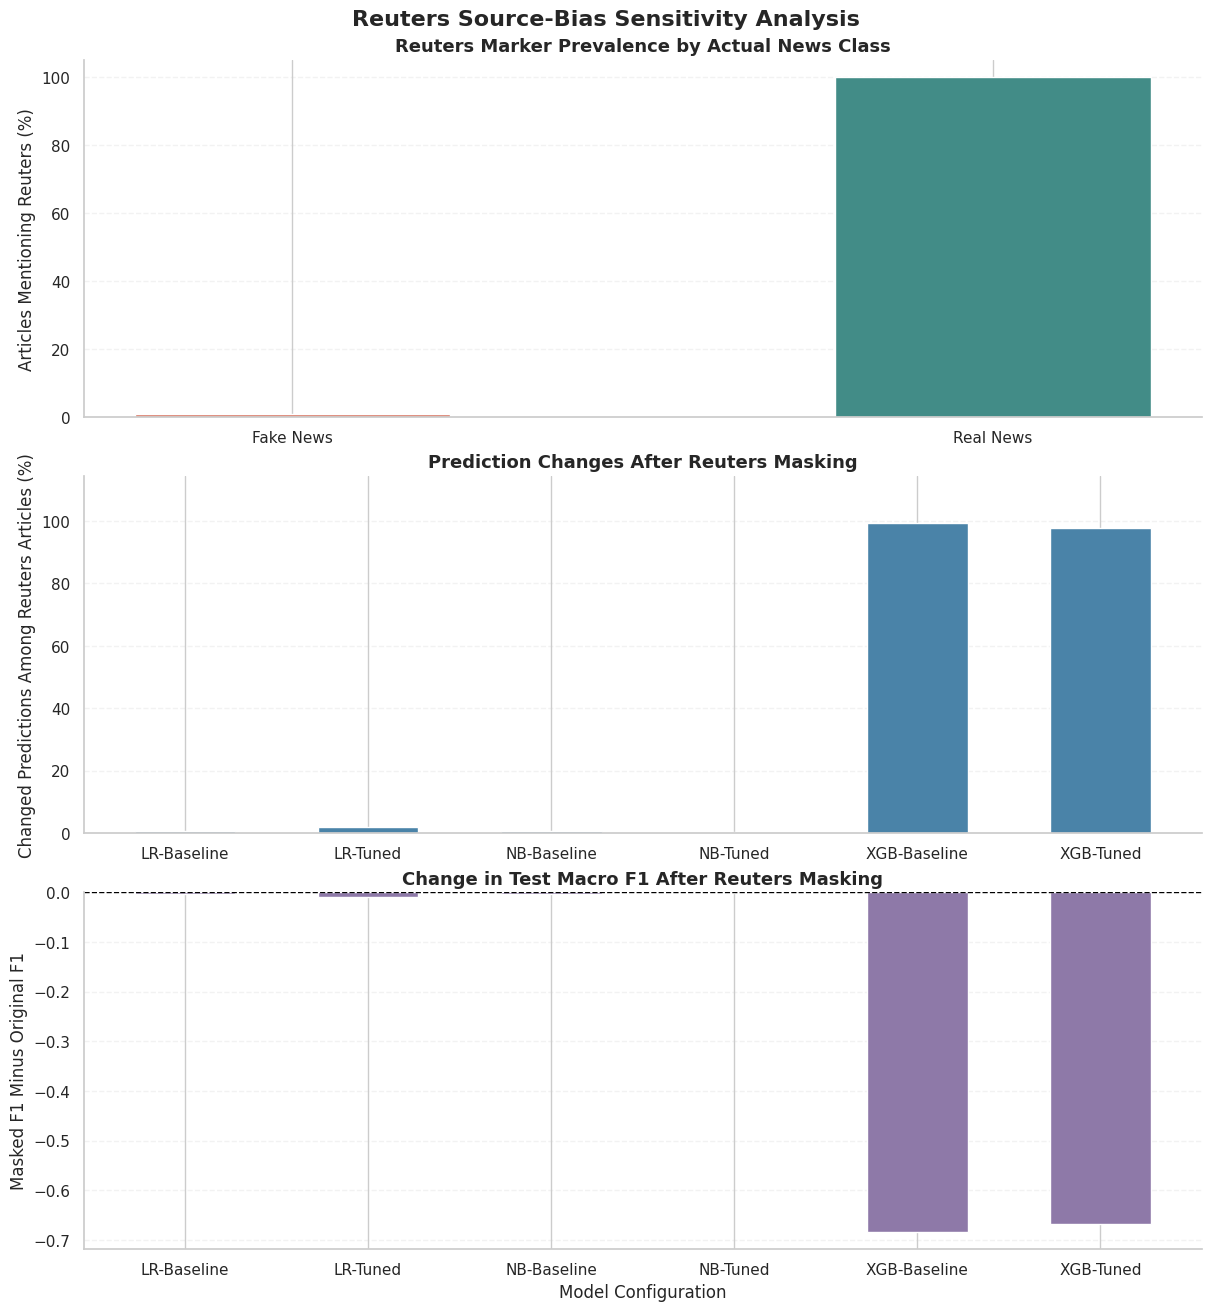


INTERPRETATION
-----------------------------------------------------------------
A strong Reuters-label association suggests that the dataset contains a potentially useful source cue.
Prediction changes after masking Reuters indicate sensitivity to that specific word.
A small change does not rule out source bias because other source-related vocabulary may remain.
Masking a word only at test time is an exploratory perturbation, not an independent external validation.
The analysis does not establish whether individual articles are factually true or false.
No models were retrained or selected using these results.


In [ ]:
# Purpose:
# Investigate whether model performance is influenced by
# the source-related word "Reuters".
#
# Three checks are performed:
# 1. Reuters marker prevalence across the two classes.
# 2. Performance of a simple Reuters-only prediction rule.
# 3. Changes in fitted model predictions after removing Reuters.
#
# No model retraining or hyperparameter tuning is performed.
# Results are exploratory and must not be used to select models.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score
)

# ------------------------------------------------------------
# 1. VERIFY REQUIRED VARIABLES
# ------------------------------------------------------------

required_variables = [
    "X_test",
    "y_test",
    "base_models",
    "baseline_fitted_models",
    "tuned_models",
    "test_predictions",
    "test_probabilities"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Run Cell 23 first. Missing: "
        + ", ".join(missing_variables)
    )

if (
    set(base_models) != set(baseline_fitted_models)
    or set(base_models) != set(tuned_models)
):
    raise ValueError(
        "Baseline and tuned models do not match."
    )

# Convert labels to an array.
y_true = np.asarray(y_test)

if set(np.unique(y_true)) != {0, 1}:
    raise ValueError(
        "Expected labels: Fake = 0 and Real = 1."
    )

if len(X_test) != len(y_true):
    raise ValueError(
        "Test articles and labels have different lengths."
    )

# ------------------------------------------------------------
# 2. IDENTIFY THE REUTERS SOURCE MARKER
# ------------------------------------------------------------

# This analysis uses the article body text only.
# The regular expression matches the complete word
# "Reuters", regardless of capitalisation.

original_text = pd.Series(
    X_test,
    copy=True
).astype(str).reset_index(drop=True)

reuters_mask = original_text.str.contains(
    r"\breuters\b",
    case=False,
    regex=True,
    na=False
).to_numpy()

reuters_count = int(reuters_mask.sum())

print("REUTERS SOURCE-MARKER ANALYSIS")
print("-" * 65)

print("Test articles:", len(original_text))
print("Articles mentioning Reuters:", reuters_count)

print(
    "Reuters mention rate:",
    f"{100 * reuters_count / len(original_text):.2f}%"
)

# ------------------------------------------------------------
# 3. EXAMINE REUTERS PREVALENCE BY ACTUAL CLASS
# ------------------------------------------------------------

actual_class = np.where(
    y_true == 0,
    "Fake",
    "Real"
)

marker_status = np.where(
    reuters_mask,
    "Mentioned",
    "Not mentioned"
)

source_marker_table = pd.crosstab(
    pd.Series(actual_class, name="Actual Class"),
    pd.Series(marker_status, name="Reuters Marker")
)

source_marker_table = source_marker_table.reindex(
    index=["Fake", "Real"],
    columns=["Mentioned", "Not mentioned"],
    fill_value=0
)

source_marker_table["Total"] = (
    source_marker_table["Mentioned"]
    + source_marker_table["Not mentioned"]
)

source_marker_table["Mention Rate (%)"] = (
    100
    * source_marker_table["Mentioned"]
    / source_marker_table["Total"]
)

print("\nREUTERS PREVALENCE BY NEWS CLASS")
print("-" * 65)

display(source_marker_table.round(4))

# ------------------------------------------------------------
# 4. TEST A SIMPLE REUTERS-ONLY RULE
# ------------------------------------------------------------

# Diagnostic rule:
# Reuters mentioned     -> predict Real (1)
# Reuters not mentioned -> predict Fake (0)
#
# This is NOT one of the three trained ML models.
# It is a simple diagnostic for source-label association.

marker_predictions = reuters_mask.astype(int)

marker_accuracy = accuracy_score(
    y_true,
    marker_predictions
)

marker_macro_f1 = f1_score(
    y_true,
    marker_predictions,
    average="macro",
    zero_division=0
)

print("\nREUTERS-ONLY DIAGNOSTIC RULE")
print("-" * 65)

print(f"Accuracy: {marker_accuracy:.6f}")
print(f"Macro F1: {marker_macro_f1:.6f}")

print(
    "This result measures source-marker association, "
    "not genuine fake-news detection capability."
)

# ------------------------------------------------------------
# 5. REMOVE ONLY THE WORD REUTERS
# ------------------------------------------------------------

# Create a modified copy of test article text.
# Keep all other words unchanged.
#
# This deliberately modifies the test inputs without
# refitting the TF-IDF vectorizer or the classifier.

reuters_masked_text = original_text.str.replace(
    r"\breuters\b",
    " ",
    case=False,
    regex=True
)

# Verify that articles without Reuters were not changed.
assert np.array_equal(
    original_text.to_numpy()[~reuters_mask],
    reuters_masked_text.to_numpy()[~reuters_mask]
), "Text without Reuters was unexpectedly modified."

print("\nREUTERS MASKING")
print("-" * 65)

print("Articles modified:", reuters_count)
print("Articles left unchanged:", len(y_true) - reuters_count)

# ------------------------------------------------------------
# 6. COMPARE ORIGINAL AND MODIFIED PREDICTIONS
# ------------------------------------------------------------

source_bias_records = []

for model_name in base_models:

    configurations = {
        "Baseline": baseline_fitted_models[model_name],
        "Tuned": tuned_models[model_name]
    }

    for configuration_name, model in configurations.items():

        result_key = (
            model_name,
            configuration_name
        )

        if (
            result_key not in test_predictions
            or result_key not in test_probabilities
        ):
            raise KeyError(
                f"Missing Cell 23 results for {result_key}."
            )

        # Reuse original test predictions from Cell 23.
        original_predictions = np.asarray(
            test_predictions[result_key]
        )

        original_probabilities = np.asarray(
            test_probabilities[result_key],
            dtype=float
        )

        # Predict again using the Reuters-masked text.
        masked_predictions = np.asarray(
            model.predict(reuters_masked_text)
        )

        masked_proba_matrix = np.asarray(
            model.predict_proba(reuters_masked_text)
        )

        # Identify the probability column for Real (1).
        real_class_positions = np.flatnonzero(
            np.asarray(model.classes_) == 1
        )

        if len(real_class_positions) != 1:
            raise ValueError(
                f"Real class missing for {model_name}."
            )

        real_index = int(real_class_positions[0])

        masked_probabilities = (
            masked_proba_matrix[:, real_index]
        )

        # Validate the prediction lengths.
        for values in [
            original_predictions,
            original_probabilities,
            masked_predictions,
            masked_probabilities
        ]:
            if len(values) != len(y_true):
                raise ValueError(
                    f"Prediction length mismatch: {result_key}"
                )

        # ----------------------------------------------------
        # 7. CALCULATE ORIGINAL AND MASKED PERFORMANCE
        # ----------------------------------------------------

        original_f1 = f1_score(
            y_true,
            original_predictions,
            average="macro",
            zero_division=0
        )

        masked_f1 = f1_score(
            y_true,
            masked_predictions,
            average="macro",
            zero_division=0
        )

        original_auc = roc_auc_score(
            y_true,
            original_probabilities
        )

        masked_auc = roc_auc_score(
            y_true,
            masked_probabilities
        )

        # Identify predictions that changed after masking.
        prediction_changed = (
            original_predictions != masked_predictions
        )

        changed_reuters = int(
            prediction_changed[reuters_mask].sum()
        )

        if reuters_count > 0:

            flip_rate = (
                100 * changed_reuters / reuters_count
            )

            mean_probability_change = float(
                np.mean(
                    masked_probabilities[reuters_mask]
                    - original_probabilities[reuters_mask]
                )
            )

        else:
            flip_rate = 0.0
            mean_probability_change = 0.0

        # Record sensitivity results.
        source_bias_records.append({
            "Model": model_name,
            "Configuration": configuration_name,
            "Original Macro F1": original_f1,
            "Masked Macro F1": masked_f1,
            "F1 Change": masked_f1 - original_f1,
            "Original ROC-AUC": original_auc,
            "Masked ROC-AUC": masked_auc,
            "AUC Change": masked_auc - original_auc,
            "Changed Predictions": changed_reuters,
            "Reuters Flip Rate (%)": flip_rate,
            "Mean Change in P(Real)": mean_probability_change
        })

# ------------------------------------------------------------
# 8. DISPLAY THE SENSITIVITY RESULTS
# ------------------------------------------------------------

source_bias_results = pd.DataFrame(
    source_bias_records
)

print("\nREUTERS MASKING: MODEL SENSITIVITY")
print("-" * 65)

display(source_bias_results.round(8))

# ------------------------------------------------------------
# 9. VALIDATE THE RESULTS
# ------------------------------------------------------------

# Three models, two configurations each.
assert len(source_bias_results) == 6, (
    "Expected six sensitivity evaluations."
)

metric_columns = [
    "Original Macro F1",
    "Masked Macro F1",
    "Original ROC-AUC",
    "Masked ROC-AUC"
]

metric_values = source_bias_results[
    metric_columns
].to_numpy(dtype=float)

assert np.isfinite(metric_values).all(), (
    "Non-finite evaluation scores detected."
)

assert (
    ((metric_values >= 0) & (metric_values <= 1))
    .all()
), "Evaluation scores outside the valid range."

assert (
    source_bias_results["Changed Predictions"]
    <= reuters_count
).all(), "More prediction changes than modified articles."

# ------------------------------------------------------------
# 10. PREPARE CLEAN FIGURE LABELS
# ------------------------------------------------------------

short_names = {
    "Logistic Regression": "LR",
    "Multinomial Naive Bayes": "NB",
    "XGBoost": "XGB"
}

plot_labels = [
    f"{short_names[name]}-{configuration}"
    for name, configuration in zip(
        source_bias_results["Model"],
        source_bias_results["Configuration"]
    )
]

x = np.arange(len(plot_labels))

# ------------------------------------------------------------
# 11. VISUALISE SOURCE-BIAS INDICATORS
# ------------------------------------------------------------

# Use three vertically arranged panels to prevent overlapping
# titles, labels and legends in notebook or report outputs.

fig, axes = plt.subplots(
    3,
    1,
    figsize=(12, 13),
    constrained_layout=True
)

# Panel 1: Reuters prevalence in each actual class.
axes[0].bar(
    ["Fake News", "Real News"],
    source_marker_table["Mention Rate (%)"],
    width=0.45,
    color=["#D97866", "#428C87"]
)

axes[0].set_title(
    "Reuters Marker Prevalence by Actual News Class",
    fontsize=13,
    fontweight="bold"
)

axes[0].set_ylabel("Articles Mentioning Reuters (%)")
axes[0].set_ylim(0, 105)

# Panel 2: Prediction changes after removing Reuters.
axes[1].bar(
    x,
    source_bias_results["Reuters Flip Rate (%)"],
    width=0.55,
    color="#4A83A8"
)

axes[1].set_title(
    "Prediction Changes After Reuters Masking",
    fontsize=13,
    fontweight="bold"
)

axes[1].set_ylabel(
    "Changed Predictions Among Reuters Articles (%)"
)

axes[1].set_xticks(x)
axes[1].set_xticklabels(plot_labels)
axes[1].set_ylim(
    0,
    max(
        5,
        source_bias_results["Reuters Flip Rate (%)"].max()
        * 1.15
    )
)

# Panel 3: Changes in macro F1.
axes[2].bar(
    x,
    source_bias_results["F1 Change"],
    width=0.55,
    color="#8E79A8"
)

axes[2].axhline(
    y=0,
    color="black",
    linestyle="--",
    linewidth=1
)

axes[2].set_title(
    "Change in Test Macro F1 After Reuters Masking",
    fontsize=13,
    fontweight="bold"
)

axes[2].set_ylabel("Masked F1 Minus Original F1")
axes[2].set_xlabel("Model Configuration")

axes[2].set_xticks(x)
axes[2].set_xticklabels(plot_labels)

# Apply consistent chart formatting.
for ax in axes:

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.25
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "Reuters Source-Bias Sensitivity Analysis",
    fontsize=16,
    fontweight="bold"
)

plt.show()

# ------------------------------------------------------------
# 12. DISPLAY INTERPRETATION NOTES
# ------------------------------------------------------------

print("\nINTERPRETATION")
print("-" * 65)

print(
    "A strong Reuters-label association suggests that "
    "the dataset contains a potentially useful source cue."
)

print(
    "Prediction changes after masking Reuters indicate "
    "sensitivity to that specific word."
)

print(
    "A small change does not rule out source bias because "
    "other source-related vocabulary may remain."
)

print(
    "Masking a word only at test time is an exploratory "
    "perturbation, not an independent external validation."
)

print(
    "The analysis does not establish whether individual "
    "articles are factually true or false."
)

print(
    "No models were retrained or selected using these results."
)


**Cell 26**

FINAL MODEL COMPARISON
---------------------------------------------------------------------------


,CV Rank,Model,Baseline CV F1,Tuned CV F1,CV F1 Std,Train-CV F1 Gap,Baseline Test F1,Tuned Test F1,Tuned Test ROC-AUC,Fake Predicted Real,Real Predicted Fake,Tuned Test Errors,Reuters Masking F1 Change,Best Parameters
0,1,XGBoost,0.995654,0.996276,0.001235,0.002009,0.996995,0.997256,0.999897,16,5,21,-0.666922,"{'model__learning_rate': 0.1, 'model__max_dept..."
1,2,Logistic Regression,0.984309,0.990525,0.001052,0.007148,0.984043,0.991503,0.999328,48,17,65,-0.010028,{'model__C': 10.0}
2,3,Multinomial Naive Bayes,0.934206,0.934470,0.004899,0.001806,0.928344,0.928621,0.980487,289,257,546,-0.002319,{'model__alpha': 0.1}



MODEL SELECTED BY CROSS-VALIDATION
---------------------------------------------------------------------------
Selected model: XGBoost
Selection metric: Five-fold CV macro F1
Final estimator: Tuned pipeline from Cell 22

COMPARISON OF THE TWO HIGHEST CV SCORES
---------------------------------------------------------------------------
Highest CV macro F1: 0.99627568
Second-highest CV macro F1: 0.99052451
CV macro F1 difference: 0.00575117

The difference identifies the observed cross-validation ranking.
It does not by itself establish a statistically significant advantage.

SELECTED MODEL: PERFORMANCE SUMMARY
---------------------------------------------------------------------------
Baseline CV Macro F1: 0.995654
Tuned CV Macro F1: 0.996276
Baseline Test Macro F1: 0.996995
Tuned Test Macro F1: 0.997256
Tuned Test ROC-AUC: 0.99989669
Training-CV F1 Gap: +0.002009
Fake articles predicted as Real: 16
Real articles predicted as Fake: 5
Total test errors: 21
Reuters-masking F1 change: -0.

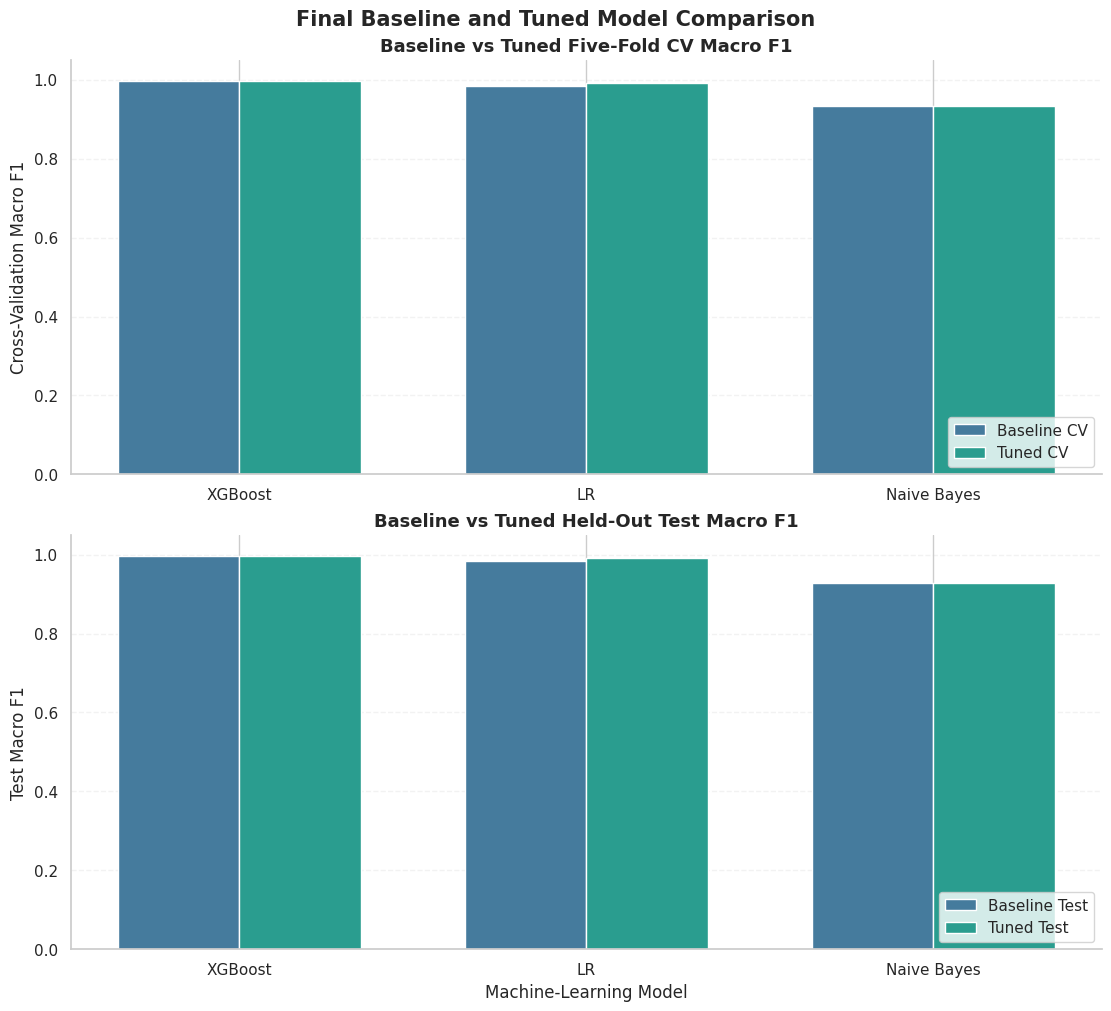


FINAL INTERPRETATION
---------------------------------------------------------------------------
The preferred model was selected using the highest five-fold cross-validation macro F1.
Held-out test performance was used to assess the selected model, not to change its selection.
Similar scores between models must be discussed without assuming meaningful superiority.
Training-validation gaps provide evidence about possible overfitting or underfitting.
Reuters sensitivity highlights potential source-related limitations.
Near-perfect scores cannot establish reliable performance on news from unseen publishers.

Final model: XGBoost


In [ ]:
# Purpose:
# Compare Logistic Regression, Multinomial Naive Bayes,
# and XGBoost using consistent evaluation evidence.
#
# Model selection is based on five-fold CV macro F1.
# Held-out test results are used for final assessment,
# NOT to change the model-selection decision.
#
# No retraining or additional tuning is performed.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


# ------------------------------------------------------------
# 1. VERIFY REQUIRED RESULTS
# ------------------------------------------------------------

required_variables = [
    "base_models",
    "tuned_models",
    "baseline_summary",
    "tuning_summary",
    "tuning_searches",
    "test_comparison",
    "cv_selected_model",
    "diagnostic_summary",
    "source_bias_results"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Run Cells 19-25 first. Missing: "
        + ", ".join(missing_variables)
    )

model_names = list(base_models.keys())

if (
    set(model_names) != set(tuned_models)
    or set(model_names) != set(tuning_searches)
):
    raise ValueError(
        "Model names do not match across evaluation results."
    )


# ------------------------------------------------------------
# 2. PREPARE THE FINAL COMPARISON TABLE
# ------------------------------------------------------------

comparison_records = []

for model_name in model_names:

    # Baseline cross-validation performance
    baseline_cv = baseline_summary.loc[
        baseline_summary["Model"] == model_name
    ]

    # Tuned cross-validation performance
    tuned_cv = tuning_summary.loc[
        tuning_summary["Model"] == model_name
    ]

    # Baseline held-out test performance
    baseline_test = test_comparison.loc[
        (test_comparison["Model"] == model_name)
        & (test_comparison["Configuration"] == "Baseline")
    ]

    # Tuned held-out test performance
    tuned_test = test_comparison.loc[
        (test_comparison["Model"] == model_name)
        & (test_comparison["Configuration"] == "Tuned")
    ]

    # Tuned generalisation diagnostics
    tuned_diagnostics = diagnostic_summary.loc[
        (diagnostic_summary["Model"] == model_name)
        & (diagnostic_summary["Configuration"] == "Tuned")
    ]

    # Source-bias sensitivity of the tuned model
    bias_result = source_bias_results.loc[
        (source_bias_results["Model"] == model_name)
        & (source_bias_results["Configuration"] == "Tuned")
    ]

    # Each lookup must return exactly one record.
    result_tables = [
        baseline_cv,
        tuned_cv,
        baseline_test,
        tuned_test,
        tuned_diagnostics,
        bias_result
    ]

    if any(len(table) != 1 for table in result_tables):
        raise ValueError(
            f"Missing or duplicate results for {model_name}."
        )

    baseline_cv = baseline_cv.iloc[0]
    tuned_cv = tuned_cv.iloc[0]
    baseline_test = baseline_test.iloc[0]
    tuned_test = tuned_test.iloc[0]
    tuned_diagnostics = tuned_diagnostics.iloc[0]
    bias_result = bias_result.iloc[0]

    comparison_records.append({
        "Model": model_name,

        "Baseline CV F1": float(
            baseline_cv["CV Macro F1"]
        ),

        "Tuned CV F1": float(
            tuned_cv["Tuned CV Macro F1"]
        ),

        "CV F1 Std": float(
            tuned_diagnostics["CV F1 Std"]
        ),

        "Train-CV F1 Gap": float(
            tuned_diagnostics["F1 Gap"]
        ),

        "Baseline Test F1": float(
            baseline_test["Macro F1"]
        ),

        "Tuned Test F1": float(
            tuned_test["Macro F1"]
        ),

        "Tuned Test ROC-AUC": float(
            tuned_test["ROC-AUC"]
        ),

        "Fake Predicted Real": int(
            tuned_test["Fake Predicted Real"]
        ),

        "Real Predicted Fake": int(
            tuned_test["Real Predicted Fake"]
        ),

        "Tuned Test Errors": int(
            tuned_test["Total Errors"]
        ),

        "Reuters Masking F1 Change": float(
            bias_result["F1 Change"]
        ),

        "Best Parameters": str(
            tuning_searches[model_name].best_params_
        )
    })


# ------------------------------------------------------------
# 3. RANK MODELS USING CROSS-VALIDATION ONLY
# ------------------------------------------------------------

model_selection_table = pd.DataFrame(
    comparison_records
)

# The primary ranking metric was established in Cell 17.
model_selection_table = (
    model_selection_table
    .sort_values(
        "Tuned CV F1",
        ascending=False,
        kind="stable"
    )
    .reset_index(drop=True)
)

model_selection_table.insert(
    0,
    "CV Rank",
    range(1, len(model_selection_table) + 1)
)

print("FINAL MODEL COMPARISON")
print("-" * 75)

display(
    model_selection_table.round(6)
)


# ------------------------------------------------------------
# 4. PRESERVE THE ORIGINAL MODEL-SELECTION DECISION
# ------------------------------------------------------------

# Cell 23 selected this model using training CV scores.
# Do not reselect a model based on the held-out test set.

final_model_name = cv_selected_model

if final_model_name not in tuned_models:
    raise ValueError(
        "The CV-selected model is not available."
    )

# Retrieve the fitted, tuned pipeline.
final_model = tuned_models[final_model_name]

print("\nMODEL SELECTED BY CROSS-VALIDATION")
print("-" * 75)

print("Selected model:", final_model_name)
print("Selection metric: Five-fold CV macro F1")
print("Final estimator: Tuned pipeline from Cell 22")


# ------------------------------------------------------------
# 5. EXAMINE THE GAP BETWEEN LEADING MODELS
# ------------------------------------------------------------

best_cv_score = float(
    model_selection_table.loc[0, "Tuned CV F1"]
)

second_cv_score = float(
    model_selection_table.loc[1, "Tuned CV F1"]
)

cv_score_difference = (
    best_cv_score - second_cv_score
)

print("\nCOMPARISON OF THE TWO HIGHEST CV SCORES")
print("-" * 75)

print(
    "Highest CV macro F1:",
    f"{best_cv_score:.8f}"
)

print(
    "Second-highest CV macro F1:",
    f"{second_cv_score:.8f}"
)

print(
    "CV macro F1 difference:",
    f"{cv_score_difference:.8f}"
)

if np.isclose(
    cv_score_difference,
    0.0,
    rtol=0,
    atol=1e-12
):
    print(
        "\nThe two models have numerically tied "
        "cross-validation scores."
    )

    print(
        "Their ranking does not establish that "
        "one model is superior."
    )

else:
    print(
        "\nThe difference identifies the observed "
        "cross-validation ranking."
    )

    print(
        "It does not by itself establish a "
        "statistically significant advantage."
    )


# ------------------------------------------------------------
# 6. DISPLAY THE SELECTED MODEL'S EVIDENCE
# ------------------------------------------------------------

selected_row = model_selection_table.loc[
    model_selection_table["Model"] == final_model_name
].iloc[0]

print("\nSELECTED MODEL: PERFORMANCE SUMMARY")
print("-" * 75)

print(
    f"Baseline CV Macro F1: "
    f"{selected_row['Baseline CV F1']:.6f}"
)

print(
    f"Tuned CV Macro F1: "
    f"{selected_row['Tuned CV F1']:.6f}"
)

print(
    f"Baseline Test Macro F1: "
    f"{selected_row['Baseline Test F1']:.6f}"
)

print(
    f"Tuned Test Macro F1: "
    f"{selected_row['Tuned Test F1']:.6f}"
)

print(
    f"Tuned Test ROC-AUC: "
    f"{selected_row['Tuned Test ROC-AUC']:.8f}"
)

print(
    f"Training-CV F1 Gap: "
    f"{selected_row['Train-CV F1 Gap']:+.6f}"
)

print(
    f"Fake articles predicted as Real: "
    f"{selected_row['Fake Predicted Real']}"
)

print(
    f"Real articles predicted as Fake: "
    f"{selected_row['Real Predicted Fake']}"
)

print(
    f"Total test errors: "
    f"{selected_row['Tuned Test Errors']}"
)

print(
    f"Reuters-masking F1 change: "
    f"{selected_row['Reuters Masking F1 Change']:+.6f}"
)


# ------------------------------------------------------------
# 7. CREATE CLEAN MODEL COMPARISON FIGURES
# ------------------------------------------------------------

# Use short model names to avoid overlapping labels.
short_names = {
    "Logistic Regression": "LR",
    "Multinomial Naive Bayes": "Naive Bayes",
    "XGBoost": "XGBoost"
}

labels = [
    short_names.get(name, name)
    for name in model_selection_table["Model"]
]

x = np.arange(len(labels))
bar_width = 0.35

# Two vertically arranged plots for report readability.
fig, axes = plt.subplots(
    2,
    1,
    figsize=(11, 10),
    constrained_layout=True
)

# ------------------------------------------------------------
# 8. PLOT CROSS-VALIDATION PERFORMANCE
# ------------------------------------------------------------

axes[0].bar(
    x - bar_width / 2,
    model_selection_table["Baseline CV F1"],
    bar_width,
    label="Baseline CV",
    color="#457B9D"
)

axes[0].bar(
    x + bar_width / 2,
    model_selection_table["Tuned CV F1"],
    bar_width,
    label="Tuned CV",
    color="#2A9D8F"
)

axes[0].set_title(
    "Baseline vs Tuned Five-Fold CV Macro F1",
    fontsize=13,
    fontweight="bold"
)

axes[0].set_ylabel("Cross-Validation Macro F1")
axes[0].set_ylim(0, 1.05)
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels)
axes[0].legend(loc="lower right")


# ------------------------------------------------------------
# 9. PLOT HELD-OUT TEST PERFORMANCE
# ------------------------------------------------------------

axes[1].bar(
    x - bar_width / 2,
    model_selection_table["Baseline Test F1"],
    bar_width,
    label="Baseline Test",
    color="#457B9D"
)

axes[1].bar(
    x + bar_width / 2,
    model_selection_table["Tuned Test F1"],
    bar_width,
    label="Tuned Test",
    color="#2A9D8F"
)

axes[1].set_title(
    "Baseline vs Tuned Held-Out Test Macro F1",
    fontsize=13,
    fontweight="bold"
)

axes[1].set_ylabel("Test Macro F1")
axes[1].set_xlabel("Machine-Learning Model")
axes[1].set_ylim(0, 1.05)
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels)
axes[1].legend(loc="lower right")

for ax in axes:

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.25
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "Final Baseline and Tuned Model Comparison",
    fontsize=15,
    fontweight="bold"
)

plt.show()


# ------------------------------------------------------------
# 10. VALIDATE FINAL COMPARISON RESULTS
# ------------------------------------------------------------

assert len(model_selection_table) == 3, (
    "Expected results for three classifiers."
)

assert set(model_selection_table["Model"]) == set(
    base_models
), "One or more models are missing."

score_columns = [
    "Baseline CV F1",
    "Tuned CV F1",
    "Baseline Test F1",
    "Tuned Test F1",
    "Tuned Test ROC-AUC"
]

scores = model_selection_table[
    score_columns
].to_numpy(dtype=float)

assert np.isfinite(scores).all(), (
    "Non-finite model scores detected."
)

assert (
    ((scores >= 0) & (scores <= 1))
    .all()
), "Model scores must be between 0 and 1."


# ------------------------------------------------------------
# 11. FINAL METHODOLOGICAL INTERPRETATION
# ------------------------------------------------------------

print("\nFINAL INTERPRETATION")
print("-" * 75)

print(
    "The preferred model was selected using the "
    "highest five-fold cross-validation macro F1."
)

print(
    "Held-out test performance was used to assess "
    "the selected model, not to change its selection."
)

print(
    "Similar scores between models must be discussed "
    "without assuming meaningful superiority."
)

print(
    "Training-validation gaps provide evidence "
    "about possible overfitting or underfitting."
)

print(
    "Reuters sensitivity highlights potential "
    "source-related limitations."
)

print(
    "Near-perfect scores cannot establish reliable "
    "performance on news from unseen publishers."
)

print("\nFinal model:", final_model_name)

**Cell 27**

FINAL MODEL CLASSIFICATION ERROR ANALYSIS
----------------------------------------------------------------------
CV-selected model: XGBoost
Test articles: 7728
Correct predictions: 7707
Incorrect predictions: 21

CLASS-SPECIFIC ERROR BREAKDOWN


,Error Type,Error Count,Actual Class Total,Class Error Rate (%)
0,Fake predicted Real,16,3490,0.4585
1,Real predicted Fake,5,4238,0.1180



CONFUSION MATRIX
----------------------------------------------------------------------


,Predicted Fake,Predicted Real
Actual Fake,3474,16
Actual Real,5,4233



PREDICTED-CLASS PROBABILITY ANALYSIS
----------------------------------------------------------------------


,Outcome,Articles,Mean_Predicted_Probability,Median_Predicted_Probability
0,Correct,7707,0.996818,0.998738
1,Incorrect,21,0.940251,0.966618


... (4 outputs left out)


ARTICLE CHARACTERISTICS BY PREDICTION OUTCOME
----------------------------------------------------------------------


,Outcome,Articles,Median_Word_Count,Mean_Word_Count,Reuters_Mentions,Reuters Mention Rate (%)
0,Correct,7707,366.0,398.9346,4250,55.1447
1,Incorrect,21,334.0,369.0476,16,76.1905



ERROR RATES BY REUTERS MARKER
----------------------------------------------------------------------


,Reuters Mentioned,Articles,Errors,Error Rate (%)
0,False,3462,5,0.1444
1,True,4266,16,0.3751


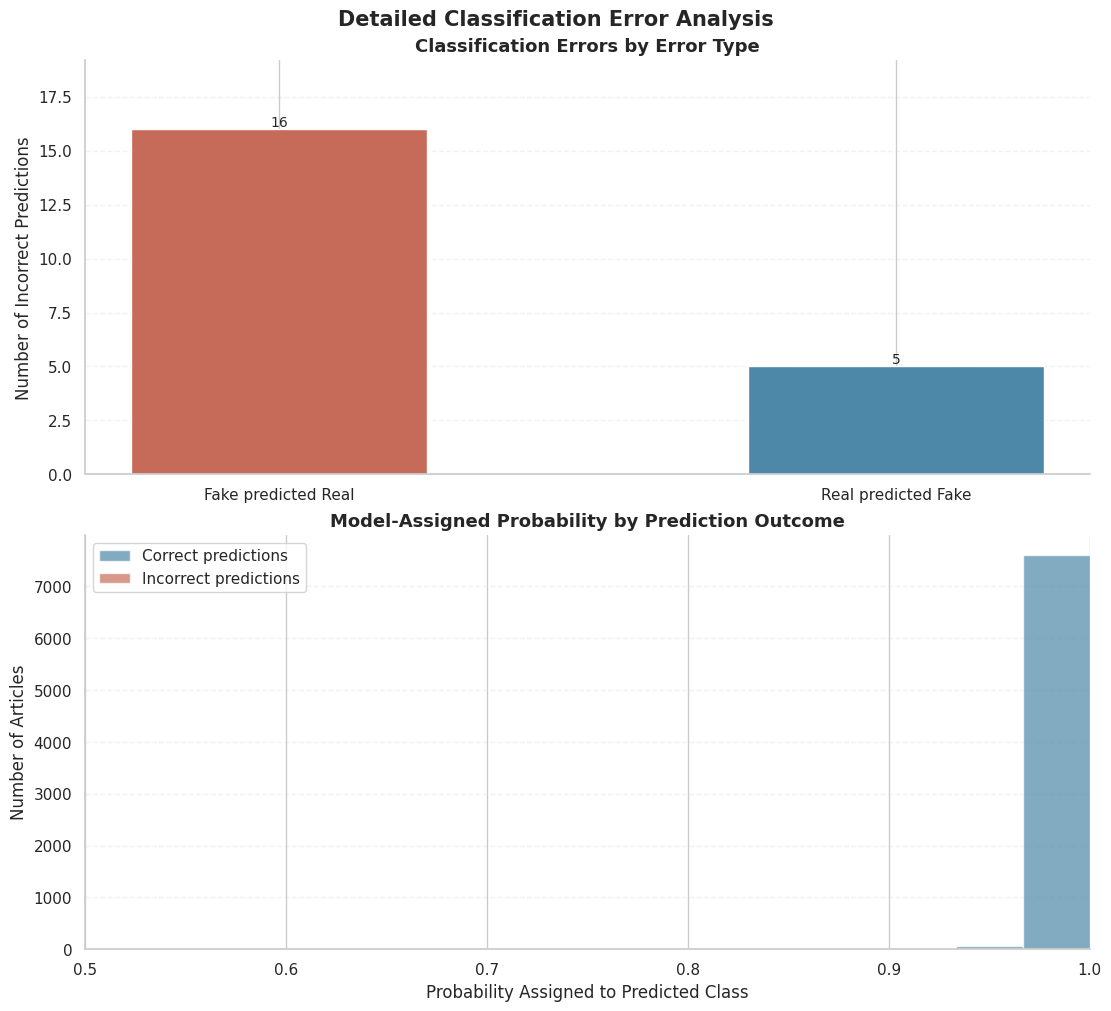


ERROR ANALYSIS INTERPRETATION
----------------------------------------------------------------------
Fake news incorrectly predicted as real: 16 articles (0.4585%).
Real news incorrectly predicted as fake: 5 articles (0.1180%).

No models were retrained.
No model selection was changed.


In [ ]:
# Purpose:
# Investigate classification errors made by the final
# model selected using cross-validation in Cell 26.
#
# Focus:
# 1. Fake news incorrectly predicted as real
# 2. Real news incorrectly predicted as fake
# 3. Confidence associated with incorrect predictions
# 4. Article length and Reuters source-marker patterns
#
# No model training, tuning or reselection is performed.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.metrics import confusion_matrix


# ------------------------------------------------------------
# 1. VERIFY REQUIRED VARIABLES
# ------------------------------------------------------------

required_variables = [
    "final_model_name",
    "final_model",
    "X_test",
    "y_test",
    "test_predictions",
    "test_probabilities"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Run Cells 23 and 26 first. Missing: "
        + ", ".join(missing_variables)
    )

# Retrieve the final CV-selected tuned model results.
result_key = (final_model_name, "Tuned")

if (
    result_key not in test_predictions
    or result_key not in test_probabilities
):
    raise KeyError(
        f"Missing final test predictions for {result_key}."
    )


# ------------------------------------------------------------
# 2. PREPARE THE ORIGINAL TEST RESULTS
# ------------------------------------------------------------

y_true = np.asarray(y_test, dtype=int).reshape(-1)

y_pred = np.asarray(
    test_predictions[result_key],
    dtype=int
).reshape(-1)

prob_real = np.asarray(
    test_probabilities[result_key],
    dtype=float
).reshape(-1)

article_text = (
    pd.Series(X_test)
    .reset_index(drop=True)
    .fillna("")
    .astype(str)
)

# Verify consistent lengths.
n_articles = len(y_true)

if not (
    len(y_pred) == n_articles
    and len(prob_real) == n_articles
    and len(article_text) == n_articles
):
    raise ValueError(
        "Test labels, predictions and texts do not align."
    )

if (
    set(np.unique(y_true)) != {0, 1}
    or not set(np.unique(y_pred)).issubset({0, 1})
):
    raise ValueError(
        "Expected binary labels: Fake = 0, Real = 1."
    )

if (
    not np.isfinite(prob_real).all()
    or ((prob_real < 0) | (prob_real > 1)).any()
):
    raise ValueError(
        "Invalid predicted probabilities detected."
    )


# ------------------------------------------------------------
# 3. IDENTIFY CLASSIFICATION ERRORS
# ------------------------------------------------------------

# False Real: Actual Fake (0), predicted Real (1).
fake_as_real = (y_true == 0) & (y_pred == 1)

# False Fake: Actual Real (1), predicted Fake (0).
real_as_fake = (y_true == 1) & (y_pred == 0)

is_error = y_true != y_pred

# Probability assigned to the predicted class.
# This represents model-assigned probability,
# not necessarily calibrated real-world confidence.
predicted_class_probability = np.where(
    y_pred == 1,
    prob_real,
    1.0 - prob_real
)

error_type = np.select(
    [fake_as_real, real_as_fake],
    ["Fake predicted Real", "Real predicted Fake"],
    default="Correct"
)


# ------------------------------------------------------------
# 4. CREATE ARTICLE-LEVEL DIAGNOSTIC DATA
# ------------------------------------------------------------

# Normalise whitespace for readable text excerpts.
readable_text = (
    article_text
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

final_error_details = pd.DataFrame({
    "Article ID": np.arange(1, n_articles + 1),

    "Actual Label": np.where(
        y_true == 0, "Fake", "Real"
    ),

    "Predicted Label": np.where(
        y_pred == 0, "Fake", "Real"
    ),

    "Error Type": error_type,

    "Is Error": is_error,

    "Predicted-Class Probability":
        predicted_class_probability,

    "Article Word Count":
        readable_text.str.split().str.len().to_numpy(),

    "Reuters Mentioned":
        article_text.str.contains(
            r"\breuters\b",
            case=False,
            regex=True,
            na=False
        ).to_numpy(),

    "Text Excerpt":
        readable_text.str.slice(0, 160).to_numpy()
})

# Keep all errors for the following analysis.
final_error_cases = final_error_details.loc[
    final_error_details["Is Error"]
].copy()


# ------------------------------------------------------------
# 5. CALCULATE CLASS-SPECIFIC ERROR RATES
# ------------------------------------------------------------

n_fake = int((y_true == 0).sum())
n_real = int((y_true == 1).sum())

n_fake_as_real = int(fake_as_real.sum())
n_real_as_fake = int(real_as_fake.sum())

total_errors = int(is_error.sum())

fake_error_rate = (
    100 * n_fake_as_real / n_fake
)

real_error_rate = (
    100 * n_real_as_fake / n_real
)

final_error_summary = pd.DataFrame([
    {
        "Error Type": "Fake predicted Real",
        "Error Count": n_fake_as_real,
        "Actual Class Total": n_fake,
        "Class Error Rate (%)": fake_error_rate
    },
    {
        "Error Type": "Real predicted Fake",
        "Error Count": n_real_as_fake,
        "Actual Class Total": n_real,
        "Class Error Rate (%)": real_error_rate
    }
])

print("FINAL MODEL CLASSIFICATION ERROR ANALYSIS")
print("-" * 70)

print("CV-selected model:", final_model_name)
print("Test articles:", n_articles)
print("Correct predictions:", n_articles - total_errors)
print("Incorrect predictions:", total_errors)

print("\nCLASS-SPECIFIC ERROR BREAKDOWN")

display(
    final_error_summary.round(4)
)


# ------------------------------------------------------------
# 6. VERIFY THE CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

assert int(cm[0, 1]) == n_fake_as_real
assert int(cm[1, 0]) == n_real_as_fake
assert int(cm.sum()) == n_articles

print("\nCONFUSION MATRIX")
print("-" * 70)

display(
    pd.DataFrame(
        cm,
        index=["Actual Fake", "Actual Real"],
        columns=["Predicted Fake", "Predicted Real"]
    )
)


# ------------------------------------------------------------
# 7. ANALYSE PREDICTION CONFIDENCE
# ------------------------------------------------------------

# Compare model-assigned probabilities for correct
# and incorrect predictions.

final_error_details["Outcome"] = np.where(
    final_error_details["Is Error"],
    "Incorrect",
    "Correct"
)

confidence_summary = (
    final_error_details
    .groupby("Outcome")
    .agg(
        Articles=("Article ID", "count"),
        Mean_Predicted_Probability=(
            "Predicted-Class Probability", "mean"
        ),
        Median_Predicted_Probability=(
            "Predicted-Class Probability", "median"
        )
    )
    .reset_index()
)

print("\nPREDICTED-CLASS PROBABILITY ANALYSIS")
print("-" * 70)

display(
    confidence_summary.round(6)
)


# ------------------------------------------------------------
# 8. EXAMINE THE MOST CONFIDENT ERRORS
# ------------------------------------------------------------

# Display up to five errors from each direction.
# These are diagnostic examples, not a random sample.

example_columns = [
    "Article ID",
    "Actual Label",
    "Predicted Label",
    "Predicted-Class Probability",
    "Article Word Count",
    "Reuters Mentioned",
    "Text Excerpt"
]

for error_name in [
    "Fake predicted Real",
    "Real predicted Fake"
]:

    examples = (
        final_error_cases.loc[
            final_error_cases["Error Type"] == error_name
        ]
        .sort_values(
            "Predicted-Class Probability",
            ascending=False
        )
        .head(5)
    )

    print("\n" + "=" * 70)
    print("HIGH-CONFIDENCE ERRORS:", error_name.upper())
    print("=" * 70)

    if examples.empty:
        print("No errors of this type were observed.")
    else:
        display(
            examples[example_columns].round(6)
        )


# ------------------------------------------------------------
# 9. EXAMINE ARTICLE LENGTH AND REUTERS MARKERS
# ------------------------------------------------------------

article_characteristics = (
    final_error_details
    .groupby("Outcome")
    .agg(
        Articles=("Article ID", "count"),
        Median_Word_Count=("Article Word Count", "median"),
        Mean_Word_Count=("Article Word Count", "mean"),
        Reuters_Mentions=("Reuters Mentioned", "sum")
    )
    .reset_index()
)

article_characteristics["Reuters Mention Rate (%)"] = (
    100
    * article_characteristics["Reuters_Mentions"]
    / article_characteristics["Articles"]
)

print("\nARTICLE CHARACTERISTICS BY PREDICTION OUTCOME")
print("-" * 70)

display(
    article_characteristics.round(4)
)

# Descriptive error rates within Reuters-marker groups.
# These are observational associations only.

reuters_error_summary = (
    final_error_details
    .groupby("Reuters Mentioned")
    .agg(
        Articles=("Article ID", "count"),
        Errors=("Is Error", "sum")
    )
    .reset_index()
)

reuters_error_summary["Error Rate (%)"] = (
    100
    * reuters_error_summary["Errors"]
    / reuters_error_summary["Articles"]
)

print("\nERROR RATES BY REUTERS MARKER")
print("-" * 70)

display(
    reuters_error_summary.round(4)
)


# ------------------------------------------------------------
# 10. CREATE CLEAN ERROR-ANALYSIS FIGURES
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    1,
    figsize=(11, 10),
    constrained_layout=True
)

# Figure A: Errors by classification direction.
error_labels = [
    "Fake predicted Real",
    "Real predicted Fake"
]

error_counts = [
    n_fake_as_real,
    n_real_as_fake
]

bars = axes[0].bar(
    error_labels,
    error_counts,
    width=0.48,
    color=["#C66B5A", "#4D88A8"]
)

axes[0].set_title(
    "Classification Errors by Error Type",
    fontsize=13,
    fontweight="bold"
)

axes[0].set_ylabel("Number of Incorrect Predictions")

axes[0].set_ylim(
    0,
    max(3, max(error_counts) * 1.20)
)

for bar, count in zip(bars, error_counts):

    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(count),
        ha="center",
        va="bottom",
        fontsize=10
    )


# Figure B: Model probability distributions.
correct_probabilities = (
    final_error_details.loc[
        ~final_error_details["Is Error"],
        "Predicted-Class Probability"
    ].to_numpy()
)

error_probabilities = (
    final_error_cases[
        "Predicted-Class Probability"
    ].to_numpy()
)

bins = np.linspace(0.5, 1.0, 16)

if len(correct_probabilities) > 0:

    axes[1].hist(
        correct_probabilities,
        bins=bins,
        alpha=0.70,
        label="Correct predictions",
        color="#4D88A8"
    )

if len(error_probabilities) > 0:

    axes[1].hist(
        error_probabilities,
        bins=bins,
        alpha=0.70,
        label="Incorrect predictions",
        color="#C66B5A"
    )

axes[1].set_title(
    "Model-Assigned Probability by Prediction Outcome",
    fontsize=13,
    fontweight="bold"
)

axes[1].set_xlabel(
    "Probability Assigned to Predicted Class"
)

axes[1].set_ylabel("Number of Articles")
axes[1].set_xlim(0.5, 1.0)
axes[1].legend(loc="upper left")

for ax in axes:

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.25
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "Detailed Classification Error Analysis",
    fontsize=15,
    fontweight="bold"
)

plt.show()


# ------------------------------------------------------------
# 11. FINAL VALIDATION
# ------------------------------------------------------------

assert total_errors == (
    n_fake_as_real + n_real_as_fake
), "Error counts are inconsistent."

assert len(final_error_cases) == total_errors, (
    "Error-case table has an incorrect row count."
)

assert final_error_summary["Class Error Rate (%)"].between(
    0, 100
).all(), "Invalid class-specific error rate."

assert final_error_details[
    "Predicted-Class Probability"
].between(0, 1).all(), "Invalid probability detected."

print("\nERROR ANALYSIS INTERPRETATION")
print("-" * 70)

print(
    f"Fake news incorrectly predicted as real: "
    f"{n_fake_as_real} articles ({fake_error_rate:.4f}%)."
)

print(
    f"Real news incorrectly predicted as fake: "
    f"{n_real_as_fake} articles ({real_error_rate:.4f}%)."
)

print("\nNo models were retrained.")
print("No model selection was changed.")

**Cell 28**

MODEL ROBUSTNESS ANALYSIS
----------------------------------------------------------------------
Test articles: 7728
Models: 3
Selected final model: XGBoost

ORIGINAL ARTICLE LENGTHS
----------------------------------------------------------------------


,text
count,7728.00
mean,398.85
std,303.88
min,1.00
25%,213.00
50%,366.00
75%,511.00
max,7209.00



Evaluating robustness: Logistic Regression

Evaluating robustness: Multinomial Naive Bayes

Evaluating robustness: XGBoost

ROBUSTNESS COMPARISON RESULTS
----------------------------------------------------------------------


,Model,Scenario,Macro F1,F1 Change,ROC-AUC,Fake Recall,Changed Predictions,Prediction Change (%),Articles Shortened (%)
0,Logistic Regression,Full article,0.991503,0.000000,0.999328,0.986246,0,0.000000,0.000000
1,Logistic Regression,First 250 words,0.988750,-0.002752,0.998874,0.979943,69,0.892857,70.354555
2,Logistic Regression,First 100 words,0.988222,-0.003281,0.999371,0.977077,115,1.488095,86.827122
3,Multinomial Naive Bayes,Full article,0.928621,0.000000,0.980487,0.917192,0,0.000000,0.000000
4,Multinomial Naive Bayes,First 250 words,0.923539,-0.005082,0.978728,0.895702,253,3.273810,70.354555
5,Multinomial Naive Bayes,First 100 words,0.925965,-0.002656,0.981074,0.886533,427,5.525362,86.827122
6,XGBoost,Full article,0.997256,0.000000,0.999897,0.995415,0,0.000000,0.000000
7,XGBoost,First 250 words,0.995426,-0.001830,0.999327,0.992550,16,0.207039,70.354555
8,XGBoost,First 100 words,0.996995,-0.000261,0.999387,0.996275,22,0.284679,86.827122


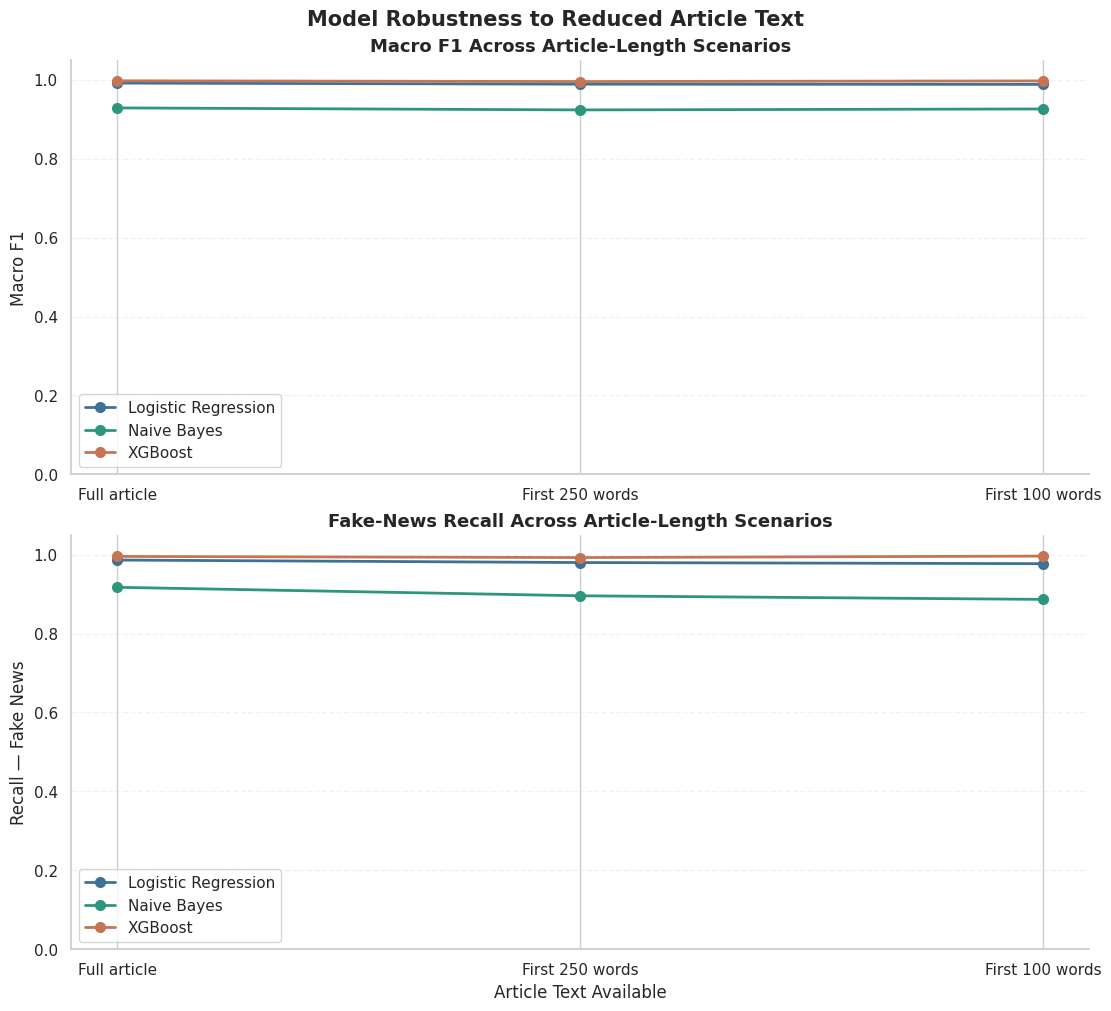


CV-SELECTED MODEL ROBUSTNESS
----------------------------------------------------------------------
Selected model: XGBoost


,Macro F1,F1 Change,ROC-AUC,Fake Recall,Prediction Change (%),Articles Shortened (%)
Scenario,,,,,,
Full article,0.997256,0.000000,0.999897,0.995415,0.000000,0.000000
First 250 words,0.995426,-0.001830,0.999327,0.992550,0.207039,70.354555
First 100 words,0.996995,-0.000261,0.999387,0.996275,0.284679,86.827122



No models were retrained.
No hyperparameters were changed.
The CV-selected model remains: XGBoost


In [ ]:
# Purpose:
# Investigate how the three tuned classifiers respond when
# only part of an article is available.
#
# Compare:
# 1. Full article text
# 2. First 250 words
# 3. First 100 words
#
# Evaluation metrics:
# - Macro F1
# - ROC-AUC
# - Fake-news recall
# - Prediction change rate
#
# No models are retrained, retuned or reselected.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.metrics import (
    f1_score,
    recall_score,
    roc_auc_score
)


# ------------------------------------------------------------
# 1. VERIFY REQUIRED VARIABLES
# ------------------------------------------------------------

required_variables = [
    "tuned_models",
    "base_models",
    "final_model_name",
    "X_test",
    "y_test",
    "test_predictions",
    "test_probabilities"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Run Cells 22, 23 and 26 first. Missing: "
        + ", ".join(missing_variables)
    )

if set(tuned_models) != set(base_models):
    raise ValueError(
        "The tuned model names do not match the baseline models."
    )

if final_model_name not in tuned_models:
    raise ValueError(
        "The CV-selected final model is unavailable."
    )


# ------------------------------------------------------------
# 2. PREPARE TEST ARTICLES AND LABELS
# ------------------------------------------------------------

y_true = np.asarray(
    y_test,
    dtype=int
).reshape(-1)

original_text = (
    pd.Series(X_test)
    .reset_index(drop=True)
    .fillna("")
    .astype(str)
)

if len(original_text) != len(y_true):
    raise ValueError(
        "Test text and labels have different lengths."
    )

if set(np.unique(y_true)) != {0, 1}:
    raise ValueError(
        "Expected labels: Fake = 0, Real = 1."
    )

# Calculate the word count of each original article.
article_word_counts = (
    original_text.str.split().str.len()
)

print("MODEL ROBUSTNESS ANALYSIS")
print("-" * 70)

print("Test articles:", len(original_text))
print("Models:", len(tuned_models))
print("Selected final model:", final_model_name)

print("\nORIGINAL ARTICLE LENGTHS")
print("-" * 70)

display(
    article_word_counts.describe().round(2)
)


# ------------------------------------------------------------
# 3. CREATE A SAFE TEXT-TRUNCATION FUNCTION
# ------------------------------------------------------------

def truncate_article(text, max_words):
    """
    Return the first max_words words of an article.

    Articles already shorter than the limit are preserved.
    No labels or model parameters are changed.
    """

    words = text.split()

    if len(words) <= max_words:
        return text

    return " ".join(words[:max_words])


# ------------------------------------------------------------
# 4. PREPARE THE ROBUSTNESS SCENARIOS
# ------------------------------------------------------------

scenario_order = [
    "Full article",
    "First 250 words",
    "First 100 words"
]

# Reuse the original test predictions for the full article.
# Predict again only for the shortened-text scenarios.

scenario_texts = {
    "First 250 words": original_text.apply(
        lambda text: truncate_article(text, 250)
    ),

    "First 100 words": original_text.apply(
        lambda text: truncate_article(text, 100)
    )
}

# Verify that truncation does not add new words.
for limit, scenario_name in [
    (250, "First 250 words"),
    (100, "First 100 words")
]:

    shortened_counts = (
        scenario_texts[scenario_name]
        .str.split()
        .str.len()
    )

    assert (shortened_counts <= limit).all(), (
        f"Truncation failed for {scenario_name}."
    )

    assert (
        shortened_counts.to_numpy()
        <= article_word_counts.to_numpy()
    ).all(), (
        f"Article length increased in {scenario_name}."
    )


# ------------------------------------------------------------
# 5. EVALUATE ALL THREE TUNED MODELS
# ------------------------------------------------------------

robustness_records = []

robustness_predictions = {}

for model_name, model in tuned_models.items():

    print(f"\nEvaluating robustness: {model_name}")

    result_key = (model_name, "Tuned")

    # Retrieve the original full-text results from Cell 23.
    if (
        result_key not in test_predictions
        or result_key not in test_probabilities
    ):
        raise KeyError(
            f"Missing original test results for {model_name}."
        )

    original_predictions = np.asarray(
        test_predictions[result_key]
    )

    original_probabilities = np.asarray(
        test_probabilities[result_key],
        dtype=float
    )

    if (
        len(original_predictions) != len(y_true)
        or len(original_probabilities) != len(y_true)
    ):
        raise ValueError(
            f"Original prediction length mismatch: {model_name}"
        )

    # Calculate the original full-text macro F1.
    original_f1 = f1_score(
        y_true,
        original_predictions,
        average="macro",
        zero_division=0
    )

    # --------------------------------------------------------
    # 6. TEST EACH TEXT-LENGTH SCENARIO
    # --------------------------------------------------------

    for scenario_name in scenario_order:

        if scenario_name == "Full article":

            # Reuse the original predictions.
            predictions = original_predictions.copy()

            real_probabilities = (
                original_probabilities.copy()
            )

            articles_shortened = 0

        else:

            # Retrieve the shortened text.
            modified_text = scenario_texts[scenario_name]

            # Predict using the already-fitted model.
            predictions = np.asarray(
                model.predict(modified_text)
            )

            probability_matrix = np.asarray(
                model.predict_proba(modified_text)
            )

            # Identify the probability column for Real (1).
            real_class_positions = np.flatnonzero(
                np.asarray(model.classes_) == 1
            )

            if len(real_class_positions) != 1:
                raise ValueError(
                    f"Class 1 missing for {model_name}."
                )

            real_index = int(
                real_class_positions[0]
            )

            real_probabilities = (
                probability_matrix[:, real_index]
            )

            # Count articles affected by truncation.
            word_limit = (
                250 if scenario_name == "First 250 words"
                else 100
            )

            articles_shortened = int(
                (article_word_counts > word_limit).sum()
            )

        # ----------------------------------------------------
        # 7. VALIDATE PREDICTIONS
        # ----------------------------------------------------

        if (
            len(predictions) != len(y_true)
            or len(real_probabilities) != len(y_true)
        ):
            raise ValueError(
                f"Prediction length mismatch: "
                f"{model_name}, {scenario_name}"
            )

        if (
            not np.isfinite(real_probabilities).all()
            or ((real_probabilities < 0)
                | (real_probabilities > 1)).any()
        ):
            raise ValueError(
                f"Invalid probabilities: "
                f"{model_name}, {scenario_name}"
            )

        # ----------------------------------------------------
        # 8. CALCULATE PERFORMANCE METRICS
        # ----------------------------------------------------

        macro_f1 = f1_score(
            y_true,
            predictions,
            average="macro",
            zero_division=0
        )

        roc_auc = roc_auc_score(
            y_true,
            real_probabilities
        )

        # Recall for Fake news (class 0).
        # Lower fake recall means more fake articles
        # are incorrectly classified as real.
        fake_recall = recall_score(
            y_true,
            predictions,
            pos_label=0,
            zero_division=0
        )

        # Compare predictions with the full-text baseline.
        changed_predictions = int(
            np.sum(
                predictions != original_predictions
            )
        )

        prediction_change_rate = (
            100
            * changed_predictions
            / len(y_true)
        )

        shortened_percentage = (
            100
            * articles_shortened
            / len(y_true)
        )

        # Save the scenario predictions.
        robustness_predictions[
            (model_name, scenario_name)
        ] = predictions

        # Record the evaluation results.
        robustness_records.append({
            "Model": model_name,
            "Scenario": scenario_name,
            "Macro F1": macro_f1,
            "F1 Change": macro_f1 - original_f1,
            "ROC-AUC": roc_auc,
            "Fake Recall": fake_recall,
            "Changed Predictions": changed_predictions,
            "Prediction Change (%)": prediction_change_rate,
            "Articles Shortened (%)": shortened_percentage
        })


# ------------------------------------------------------------
# 9. CREATE THE ROBUSTNESS COMPARISON TABLE
# ------------------------------------------------------------

robustness_results = pd.DataFrame(
    robustness_records
)

# Preserve the intended scenario order.
robustness_results["Scenario"] = pd.Categorical(
    robustness_results["Scenario"],
    categories=scenario_order,
    ordered=True
)

robustness_results = (
    robustness_results
    .sort_values(["Model", "Scenario"])
    .reset_index(drop=True)
)

print("\nROBUSTNESS COMPARISON RESULTS")
print("-" * 70)

display(
    robustness_results.round(6)
)


# ------------------------------------------------------------
# 10. CREATE CLEAN VERTICAL COMPARISON CHARTS
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    1,
    figsize=(11, 10),
    constrained_layout=True
)

x = np.arange(len(scenario_order))

short_names = {
    "Logistic Regression": "Logistic Regression",
    "Multinomial Naive Bayes": "Naive Bayes",
    "XGBoost": "XGBoost"
}

model_colors = [
    "#3E7198",
    "#2C967F",
    "#C57551"
]

# Plot one line per tuned classifier.
for model_index, model_name in enumerate(tuned_models):

    model_rows = (
        robustness_results.loc[
            robustness_results["Model"] == model_name
        ]
        .set_index("Scenario")
        .loc[scenario_order]
    )

    label = short_names.get(
        model_name,
        model_name
    )

    # --------------------------------------------------------
    # 11. CHART A: MACRO F1 ROBUSTNESS
    # --------------------------------------------------------

    axes[0].plot(
        x,
        model_rows["Macro F1"],
        marker="o",
        markersize=7,
        linewidth=2,
        color=model_colors[model_index],
        label=label
    )

    # --------------------------------------------------------
    # 12. CHART B: FAKE-NEWS RECALL ROBUSTNESS
    # --------------------------------------------------------

    axes[1].plot(
        x,
        model_rows["Fake Recall"],
        marker="o",
        markersize=7,
        linewidth=2,
        color=model_colors[model_index],
        label=label
    )


# Format the first chart.
axes[0].set_title(
    "Macro F1 Across Article-Length Scenarios",
    fontsize=13,
    fontweight="bold"
)

axes[0].set_ylabel("Macro F1")
axes[0].set_ylim(0, 1.05)
axes[0].legend(loc="lower left")

# Format the second chart.
axes[1].set_title(
    "Fake-News Recall Across Article-Length Scenarios",
    fontsize=13,
    fontweight="bold"
)

axes[1].set_ylabel("Recall — Fake News")
axes[1].set_xlabel("Article Text Available")
axes[1].set_ylim(0, 1.05)
axes[1].legend(loc="lower left")

# Apply shared formatting.
for ax in axes:

    ax.set_xticks(x)
    ax.set_xticklabels(scenario_order)

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.25
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "Model Robustness to Reduced Article Text",
    fontsize=15,
    fontweight="bold"
)

plt.show()


# ------------------------------------------------------------
# 13. SUMMARISE THE CV-SELECTED FINAL MODEL
# ------------------------------------------------------------

selected_model_robustness = (
    robustness_results.loc[
        robustness_results["Model"] == final_model_name
    ]
    .set_index("Scenario")
    .loc[scenario_order]
)

print("\nCV-SELECTED MODEL ROBUSTNESS")
print("-" * 70)

print("Selected model:", final_model_name)

display(
    selected_model_robustness[
        [
            "Macro F1",
            "F1 Change",
            "ROC-AUC",
            "Fake Recall",
            "Prediction Change (%)",
            "Articles Shortened (%)"
        ]
    ].round(6)
)


# ------------------------------------------------------------
# 14. FINAL VALIDATION
# ------------------------------------------------------------

# Three models evaluated under three text scenarios.
assert len(robustness_results) == 9, (
    "Expected nine robustness evaluations."
)

metric_columns = [
    "Macro F1",
    "ROC-AUC",
    "Fake Recall"
]

metric_values = robustness_results[
    metric_columns
].to_numpy(dtype=float)

assert np.isfinite(metric_values).all(), (
    "Non-finite robustness scores detected."
)

assert (
    ((metric_values >= 0) & (metric_values <= 1))
    .all()
), "Invalid robustness metric values."

assert robustness_results[
    "Prediction Change (%)"
].between(0, 100).all(), (
    "Invalid prediction change percentages."
)

print("\nNo models were retrained.")
print("No hyperparameters were changed.")
print("The CV-selected model remains:", final_model_name)

**Cell 29**

In [ ]:
# Purpose:
# Consolidate the experimental findings into a clear,
# reproducible summary suitable for the final MSc report.
#
# Evidence includes:
# - Cross-validation performance
# - Baseline versus tuned test performance
# - Underfitting and overfitting diagnostics
# - Classification errors
# - Reuters source-bias sensitivity
# - Article-length robustness
#
# No models are retrained.
# No additional test-based model selection is performed.

import numpy as np
import pandas as pd
from IPython.display import display


# ------------------------------------------------------------
# 1. VERIFY REQUIRED RESULTS
# ------------------------------------------------------------

required_variables = [
    "model_selection_table",
    "final_model_name",
    "cv_selected_model",
    "tuning_test_comparison",
    "diagnostic_summary",
    "source_bias_results",
    "robustness_results",
    "final_error_summary",
    "test_comparison",
    "X_train",
    "X_test",
    "y_train",
    "y_test"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Run the previous evaluation cells first. Missing: "
        + ", ".join(missing_variables)
    )

# The final model must remain the one selected using CV.
if final_model_name != cv_selected_model:
    raise ValueError(
        "Final model selection differs from Cell 23."
    )


# ------------------------------------------------------------
# 2. CONSOLIDATE MODEL COMPARISON RESULTS
# ------------------------------------------------------------

# Combine cross-validation and held-out test evidence
# without introducing any new selection criteria.

tuning_columns = [
    "Model",
    "Macro F1 Change",
    "ROC-AUC Change",
    "Error Reduction"
]

final_results_summary = model_selection_table.merge(
    tuning_test_comparison[tuning_columns],
    on="Model",
    how="inner",
    validate="one_to_one"
)

if len(final_results_summary) != 3:
    raise ValueError(
        "Expected complete results for three classifiers."
    )

# Arrange columns in a report-friendly order.
summary_columns = [
    "CV Rank",
    "Model",
    "Baseline CV F1",
    "Tuned CV F1",
    "CV F1 Std",
    "Train-CV F1 Gap",
    "Baseline Test F1",
    "Tuned Test F1",
    "Macro F1 Change",
    "Tuned Test ROC-AUC",
    "ROC-AUC Change",
    "Tuned Test Errors",
    "Error Reduction"
]

print("=" * 75)
print("FINAL EXPERIMENTAL MODEL COMPARISON")
print("=" * 75)

display(
    final_results_summary[
        summary_columns
    ].round(6)
)


# ------------------------------------------------------------
# 3. RETRIEVE THE CV-SELECTED MODEL'S EVIDENCE
# ------------------------------------------------------------

selected_results = final_results_summary.loc[
    final_results_summary["Model"] == final_model_name
]

if len(selected_results) != 1:
    raise ValueError(
        "Missing or duplicate selected-model results."
    )

selected = selected_results.iloc[0]

# Retrieve the selected model's diagnostic results.
selected_diagnostics = diagnostic_summary.loc[
    (diagnostic_summary["Model"] == final_model_name)
    & (diagnostic_summary["Configuration"] == "Tuned")
]

# Retrieve Reuters masking results.
selected_bias = source_bias_results.loc[
    (source_bias_results["Model"] == final_model_name)
    & (source_bias_results["Configuration"] == "Tuned")
]

# Retrieve text-length robustness results.
selected_robustness = robustness_results.loc[
    robustness_results["Model"] == final_model_name
]

if (
    len(selected_diagnostics) != 1
    or len(selected_bias) != 1
    or len(selected_robustness) != 3
):
    raise ValueError(
        "Incomplete diagnostic results for the final model."
    )

diagnostics = selected_diagnostics.iloc[0]
bias = selected_bias.iloc[0]

full_text_result = selected_robustness.loc[
    selected_robustness["Scenario"] == "Full article"
]

short_text_result = selected_robustness.loc[
    selected_robustness["Scenario"] == "First 100 words"
]

if (
    len(full_text_result) != 1
    or len(short_text_result) != 1
):
    raise ValueError(
        "Required robustness scenarios are missing."
    )

full_text_result = full_text_result.iloc[0]
short_text_result = short_text_result.iloc[0]


# ------------------------------------------------------------
# 4. SUMMARISE THE FINAL MODEL
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("CROSS-VALIDATION-SELECTED MODEL")
print("=" * 75)

print("Selected model:", final_model_name)

print(
    "Selection criterion:",
    "Highest tuned five-fold CV macro F1"
)

print(
    f"Baseline CV macro F1: "
    f"{selected['Baseline CV F1']:.6f}"
)

print(
    f"Tuned CV macro F1: "
    f"{selected['Tuned CV F1']:.6f}"
)

print(
    f"Tuned test macro F1: "
    f"{selected['Tuned Test F1']:.6f}"
)

print(
    f"Tuned test ROC-AUC: "
    f"{selected['Tuned Test ROC-AUC']:.8f}"
)

print(
    f"Training-validation F1 gap: "
    f"{diagnostics['F1 Gap']:+.6f}"
)

print(
    f"Training-validation ROC-AUC gap: "
    f"{diagnostics['ROC-AUC Gap']:+.8f}"
)


# ------------------------------------------------------------
# 5. EVALUATE THE EFFECT OF HYPERPARAMETER TUNING
# ------------------------------------------------------------

f1_change = float(
    selected["Macro F1 Change"]
)

auc_change = float(
    selected["ROC-AUC Change"]
)

print("\n" + "=" * 75)
print("HYPERPARAMETER TUNING FINDINGS")
print("=" * 75)

print(
    f"Test macro F1 change: {f1_change:+.8f}"
)

print(
    f"Test ROC-AUC change: {auc_change:+.8f}"
)

print(
    "Test error reduction:",
    int(selected["Error Reduction"])
)

# Interpret the observed test F1 difference without
# assuming that tuning must always improve test scores.

if f1_change > 1e-12:

    tuning_interpretation = (
        "The tuned model achieved a higher macro F1 "
        "than its baseline on this held-out test set."
    )

elif f1_change < -1e-12:

    tuning_interpretation = (
        "The tuned model achieved a lower macro F1 "
        "than its baseline on this held-out test set."
    )

else:

    tuning_interpretation = (
        "Baseline and tuned models achieved the "
        "same observed test macro F1."
    )

print("\nInterpretation:")
print(tuning_interpretation)

print(
    "The observed difference does not, by itself, "
    "establish a general improvement."
)


# ------------------------------------------------------------
# 6. SUMMARISE CLASSIFICATION ERRORS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("CLASSIFICATION ERROR FINDINGS")
print("=" * 75)

display(
    final_error_summary.round(4)
)

fake_as_real = int(
    selected["Fake Predicted Real"]
)

real_as_fake = int(
    selected["Real Predicted Fake"]
)

print(
    "\nFake articles predicted as Real:",
    fake_as_real
)

print(
    "Real articles predicted as Fake:",
    real_as_fake
)

print(
    "Both error types are important, but their "
    "real-world consequences differ."
)


# ------------------------------------------------------------
# 7. SUMMARISE SOURCE-BIAS EVIDENCE
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("REUTERS SOURCE-BIAS FINDINGS")
print("=" * 75)

print(
    f"Change in macro F1 after Reuters masking: "
    f"{bias['F1 Change']:+.8f}"
)

print(
    f"Prediction flip rate among Reuters articles: "
    f"{bias['Reuters Flip Rate (%)']:.4f}%"
)

print(
    "These results measure sensitivity to the "
    "Reuters token, not all possible source cues."
)

print(
    "A small effect does not rule out source bias."
)


# ------------------------------------------------------------
# 8. SUMMARISE ARTICLE-LENGTH ROBUSTNESS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("ARTICLE-LENGTH ROBUSTNESS FINDINGS")
print("=" * 75)

robustness_f1_change = (
    float(short_text_result["Macro F1"])
    - float(full_text_result["Macro F1"])
)

fake_recall_change = (
    float(short_text_result["Fake Recall"])
    - float(full_text_result["Fake Recall"])
)

print(
    f"Full article macro F1: "
    f"{full_text_result['Macro F1']:.6f}"
)

print(
    f"First 100 words macro F1: "
    f"{short_text_result['Macro F1']:.6f}"
)

print(
    f"Macro F1 change: "
    f"{robustness_f1_change:+.6f}"
)

print(
    f"Fake-news recall change: "
    f"{fake_recall_change:+.6f}"
)

print(
    "This experiment assesses reduced-text "
    "sensitivity, not external publisher generalisation."
)


# ------------------------------------------------------------
# 9. COMPARE THE TWO LEADING MODELS
# ------------------------------------------------------------

ranked_models = final_results_summary.sort_values(
    "Tuned CV F1",
    ascending=False,
    kind="stable"
)

top_model = ranked_models.iloc[0]
second_model = ranked_models.iloc[1]

leading_cv_gap = (
    float(top_model["Tuned CV F1"])
    - float(second_model["Tuned CV F1"])
)

print("\n" + "=" * 75)
print("MODEL-SELECTION JUSTIFICATION")
print("=" * 75)

print(
    "Highest CV score:",
    top_model["Model"]
)

print(
    "Second-highest CV score:",
    second_model["Model"]
)

print(
    f"CV macro F1 difference: "
    f"{leading_cv_gap:.8f}"
)

print(
    "The ranking follows the predefined "
    "cross-validation metric."
)

print(
    "A small numerical difference does not "
    "establish statistically significant superiority."
)

print(
    "Model complexity, interpretability and "
    "practical constraints must also be discussed."
)


# ------------------------------------------------------------
# 10. CREATE A REPORT-READY FINDINGS TABLE
# ------------------------------------------------------------

final_findings_table = pd.DataFrame([
    {
        "Research Area": "Model selection",
        "Finding": (
            f"{final_model_name} was selected using "
            f"five-fold CV macro F1 "
            f"({selected['Tuned CV F1']:.6f})."
        )
    },
    {
        "Research Area": "Held-out performance",
        "Finding": (
            f"Test macro F1 = "
            f"{selected['Tuned Test F1']:.6f}; "
            f"ROC-AUC = "
            f"{selected['Tuned Test ROC-AUC']:.8f}."
        )
    },
    {
        "Research Area": "Hyperparameter tuning",
        "Finding": (
            f"Observed test macro F1 change = "
            f"{f1_change:+.6f}."
        )
    },
    {
        "Research Area": "Generalisation diagnostics",
        "Finding": (
            f"Training-validation macro F1 gap = "
            f"{diagnostics['F1 Gap']:+.6f}."
        )
    },
    {
        "Research Area": "Classification errors",
        "Finding": (
            f"{fake_as_real} fake articles predicted "
            f"real; {real_as_fake} real articles "
            f"predicted fake."
        )
    },
    {
        "Research Area": "Reuters sensitivity",
        "Finding": (
            f"Macro F1 change after masking = "
            f"{bias['F1 Change']:+.6f}."
        )
    },
    {
        "Research Area": "Text-length robustness",
        "Finding": (
            f"Macro F1 change using first 100 words = "
            f"{robustness_f1_change:+.6f}."
        )
    }
])

print("\n" + "=" * 75)
print("REPORT-READY RESEARCH FINDINGS")
print("=" * 75)

display(final_findings_table)


# ------------------------------------------------------------
# 11. VERIFY FINAL RESULTS
# ------------------------------------------------------------

assert final_model_name in (
    final_results_summary["Model"].tolist()
), "Selected model is missing."

assert len(final_findings_table) == 7, (
    "Research findings table is incomplete."
)

assert len(X_train) == len(y_train), (
    "Training data length mismatch."
)

assert len(X_test) == len(y_test), (
    "Testing data length mismatch."
)

numeric_columns = [
    "Baseline CV F1",
    "Tuned CV F1",
    "Baseline Test F1",
    "Tuned Test F1",
    "Tuned Test ROC-AUC"
]

values = final_results_summary[
    numeric_columns
].to_numpy(dtype=float)

assert np.isfinite(values).all(), (
    "Non-finite final scores detected."
)

assert (
    ((values >= 0) & (values <= 1))
    .all()
), "Final scores outside the valid range."


print("\nNo models were retrained.")
print("No hyperparameters were changed.")
print("No new model was selected.")


FINAL EXPERIMENTAL MODEL COMPARISON


,CV Rank,Model,Baseline CV F1,Tuned CV F1,CV F1 Std,Train-CV F1 Gap,Baseline Test F1,Tuned Test F1,Macro F1 Change,Tuned Test ROC-AUC,ROC-AUC Change,Tuned Test Errors,Error Reduction
0,1,XGBoost,0.995654,0.996276,0.001235,0.002009,0.996995,0.997256,0.000261,0.999897,0.000200,21,2
1,2,Logistic Regression,0.984309,0.990525,0.001052,0.007148,0.984043,0.991503,0.007460,0.999328,0.000935,65,57
2,3,Multinomial Naive Bayes,0.934206,0.934470,0.004899,0.001806,0.928344,0.928621,0.000277,0.980487,0.000432,546,2



CROSS-VALIDATION-SELECTED MODEL
Selected model: XGBoost
Selection criterion: Highest tuned five-fold CV macro F1
Baseline CV macro F1: 0.995654
Tuned CV macro F1: 0.996276
Tuned test macro F1: 0.997256
Tuned test ROC-AUC: 0.99989669
Training-validation F1 gap: +0.002009
Training-validation ROC-AUC gap: +0.00029642

HYPERPARAMETER TUNING FINDINGS
Test macro F1 change: +0.00026147
Test ROC-AUC change: +0.00020019
Test error reduction: 2

Interpretation:
The tuned model achieved a higher macro F1 than its baseline on this held-out test set.
The observed difference does not, by itself, establish a general improvement.

CLASSIFICATION ERROR FINDINGS


,Error Type,Error Count,Actual Class Total,Class Error Rate (%)
0,Fake predicted Real,16,3490,0.4585
1,Real predicted Fake,5,4238,0.1180



Fake articles predicted as Real: 16
Real articles predicted as Fake: 5
Both error types are important, but their real-world consequences differ.

REUTERS SOURCE-BIAS FINDINGS
Change in macro F1 after Reuters masking: -0.66692172
Prediction flip rate among Reuters articles: 97.8669%
These results measure sensitivity to the Reuters token, not all possible source cues.
A small effect does not rule out source bias.

ARTICLE-LENGTH ROBUSTNESS FINDINGS
Full article macro F1: 0.997256
First 100 words macro F1: 0.996995
Macro F1 change: -0.000261
Fake-news recall change: +0.000860
This experiment assesses reduced-text sensitivity, not external publisher generalisation.

MODEL-SELECTION JUSTIFICATION
Highest CV score: XGBoost
Second-highest CV score: Logistic Regression
CV macro F1 difference: 0.00575117
The ranking follows the predefined cross-validation metric.
A small numerical difference does not establish statistically significant superiority.
Model complexity, interpretability and practi

,Research Area,Finding
0,Model selection,XGBoost was selected using five-fold CV macro ...
1,Held-out performance,Test macro F1 = 0.997256; ROC-AUC = 0.99989669.
2,Hyperparameter tuning,Observed test macro F1 change = +0.000261.
3,Generalisation diagnostics,Training-validation macro F1 gap = +0.002009.
4,Classification errors,16 fake articles predicted real; 5 real articl...
5,Reuters sensitivity,Macro F1 change after masking = -0.666922.
6,Text-length robustness,Macro F1 change using first 100 words = -0.000...



No models were retrained.
No hyperparameters were changed.
No new model was selected.


In [ ]:

# ============================================================
# CELL 30: FINAL EXPERIMENTAL RESULTS SUMMARY
# Fake News Detection Using Machine Learning
# ============================================================

# Display a concise final comparison of the three models.
# No printed explanations or paragraphs.
# No additional training, tuning, or model selection.

import numpy as np
import pandas as pd
from IPython.display import display

# ------------------------------------------------------------
# 1. VERIFY REQUIRED RESULTS
# ------------------------------------------------------------

required_variables = [
    "final_results_summary",
    "source_bias_results",
    "robustness_results",
    "final_model_name",
    "cv_selected_model"
]

missing = [
    name for name in required_variables
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Missing previous results: " + ", ".join(missing)
    )

assert final_model_name == cv_selected_model, (
    "The final model must match the CV-selected model."
)

# ------------------------------------------------------------
# 2. COMBINE FINAL EVALUATION RESULTS
# ------------------------------------------------------------

summary_records = []

for _, row in final_results_summary.iterrows():

    model_name = row["Model"]

    # Retrieve Reuters sensitivity results.
    bias = source_bias_results.loc[
        (source_bias_results["Model"] == model_name)
        & (source_bias_results["Configuration"] == "Tuned")
    ]

    # Retrieve full-text performance.
    full_text = robustness_results.loc[
        (robustness_results["Model"] == model_name)
        & (robustness_results["Scenario"] == "Full article")
    ]

    # Retrieve shortened-text performance.
    short_text = robustness_results.loc[
        (robustness_results["Model"] == model_name)
        & (robustness_results["Scenario"] == "First 100 words")
    ]

    if any(
        len(result) != 1
        for result in [bias, full_text, short_text]
    ):
        raise ValueError(
            f"Incomplete evaluation results: {model_name}"
        )

    # Calculate the change in macro F1 after truncation.
    short_text_change = (
        float(short_text["Macro F1"].iloc[0])
        - float(full_text["Macro F1"].iloc[0])
    )

    summary_records.append({
        "Model": model_name,

        "CV Selected":
            "Yes" if model_name == final_model_name else "No",

        "CV Macro F1":
            float(row["Tuned CV F1"]),

        "Test Macro F1":
            float(row["Tuned Test F1"]),

        "Test ROC-AUC":
            float(row["Tuned Test ROC-AUC"]),

        "Tuning F1 Change":
            float(row["Macro F1 Change"]),

        "Train-CV F1 Gap":
            float(row["Train-CV F1 Gap"]),

        "Test Errors":
            int(row["Tuned Test Errors"]),

        "Reuters F1 Change":
            float(bias["F1 Change"].iloc[0]),

        "100-Word F1 Change":
            short_text_change
    })

# ------------------------------------------------------------
# 3. CREATE THE FINAL RESULTS TABLE
# ------------------------------------------------------------

final_cell30_summary = pd.DataFrame(
    summary_records
)

# Preserve the original cross-validation ranking.
ranking = final_results_summary[
    ["Model", "CV Rank"]
]

final_cell30_summary = (
    final_cell30_summary
    .merge(
        ranking,
        on="Model",
        validate="one_to_one"
    )
    .sort_values("CV Rank")
    .drop(columns="CV Rank")
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 4. VALIDATE NUMERICAL RESULTS
# ------------------------------------------------------------

numeric_columns = final_cell30_summary.select_dtypes(
    include="number"
).columns

assert np.isfinite(
    final_cell30_summary[numeric_columns].to_numpy()
).all(), "Invalid numerical results detected."

assert len(final_cell30_summary) == 3, (
    "Results for all three classifiers are required."
)

assert (
    final_cell30_summary["CV Selected"].eq("Yes").sum()
    == 1
), "Exactly one model must be selected."

# ------------------------------------------------------------
# 5. DISPLAY ONLY THE CLEAN FINAL TABLE
# ------------------------------------------------------------

display(
    final_cell30_summary.style
    .format({
        "CV Macro F1": "{:.6f}",
        "Test Macro F1": "{:.6f}",
        "Test ROC-AUC": "{:.8f}",
        "Tuning F1 Change": "{:+.6f}",
        "Train-CV F1 Gap": "{:+.6f}",
        "Test Errors": "{:d}",
        "Reuters F1 Change": "{:+.6f}",
        "100-Word F1 Change": "{:+.6f}"
    })
    .hide(axis="index")
)


Model,CV Selected,CV Macro F1,Test Macro F1,Test ROC-AUC,Tuning F1 Change,Train-CV F1 Gap,Test Errors,Reuters F1 Change,100-Word F1 Change
XGBoost,Yes,0.996276,0.997256,0.99989669,+0.000261,+0.002009,21,-0.666922,-0.000261
Logistic Regression,No,0.990525,0.991503,0.99932843,+0.007460,+0.007148,65,-0.010028,-0.003281
Multinomial Naive Bayes,No,0.934470,0.928621,0.98048750,+0.000277,+0.001806,546,-0.002319,-0.002656
